In [1]:
# ============================================================
# SECTION 1: IMPORT LIBRARIES
# Project: Low-Rank Matrix and Tensor Decomposition for
#          Traffic Anomaly Detection (Guangzhou Traffic Speed)
# ============================================================

!pip install tensorly
import os
import sys
import warnings

import numpy as np
import pandas as pd
import scipy
import scipy.linalg as sla          
import scipy.stats as stats         


import matplotlib
import matplotlib.pyplot as plt


import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# --- Tensor decomposition (TensorLy) ---
try:
    import tensorly as tl
    from tensorly.decomposition import tucker
    from tensorly import unfold, fold
except ImportError as err:
    raise ImportError(
        "TensorLy is not installed. Install it with:\n"
        "    pip install tensorly\n"
        "then restart the kernel and re-run this cell."
    ) from err


RANDOM_STATE = 42                    # reproducibility for all random operations
np.random.seed(RANDOM_STATE)

DATA_PATH = r"C:\\Users\\DELL\\Desktop\traffic_speed_data.csv"
OUTPUT_DIR = "outputs"               # folder for saved figures/tables
os.makedirs(OUTPUT_DIR, exist_ok=True)

# TensorLy: use NumPy as the computational backend
tl.set_backend("numpy")

# Keep notebook output tidy
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
np.set_printoptions(precision=4, suppress=True)

# Consistent plot style
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

# ------------------------------------------------------------
# Environment report (useful for reproducibility in the report)
# ------------------------------------------------------------
print("Libraries imported successfully.\n")
print(f"{'Python':<14}: {sys.version.split()[0]}")
print(f"{'NumPy':<14}: {np.__version__}")
print(f"{'Pandas':<14}: {pd.__version__}")
print(f"{'SciPy':<14}: {scipy.__version__}")
print(f"{'Scikit-Learn':<14}: {sklearn.__version__}")
print(f"{'Matplotlib':<14}: {matplotlib.__version__}")
print(f"{'TensorLy':<14}: {tl.__version__}")
print(f"\nTensorLy backend : {tl.get_backend()}")
print(f"Random state     : {RANDOM_STATE}")
print(f"Data path        : {DATA_PATH}")

Defaulting to user installation because normal site-packages is not writeable
Libraries imported successfully.

Python        : 3.12.7
NumPy         : 1.26.4
Pandas        : 2.1.4
SciPy         : 1.13.1
Scikit-Learn  : 1.5.1
Matplotlib    : 3.9.2
TensorLy      : 0.10.0

TensorLy backend : numpy
Random state     : 42
Data path        : C:\\Users\\DELL\\Desktop\traffic_speed_data.csv


Dataset loaded successfully.
File size      : 37.84 MB
Rows x Columns : 1,855,589 x 4
Memory usage   : 59.38 MB

--- Detected column roles ---
Value (speed) column : speed
Road column          : road_id  (214 unique)
Day column           : day_id  (61 unique)
Time column          : time_id  (144 unique)

--- Completeness check (roads x days x times) ---
Expected rows if fully observed : 1,879,776
Actual rows                     : 1,855,589
Missing combinations            : 24,187 (1.29%)

--- First 5 rows ---


,road_id,day_id,time_id,speed
0,1,1,1,40.8930
1,1,1,2,41.9380
2,1,1,3,44.0980
3,1,1,4,44.4830
4,1,1,5,44.1720


--- Last 5 rows ---


,road_id,day_id,time_id,speed
1855584,214,61,140,51.8780
1855585,214,61,141,51.1330
1855586,214,61,142,51.2660
1855587,214,61,143,51.3520
1855588,214,61,144,52.4020


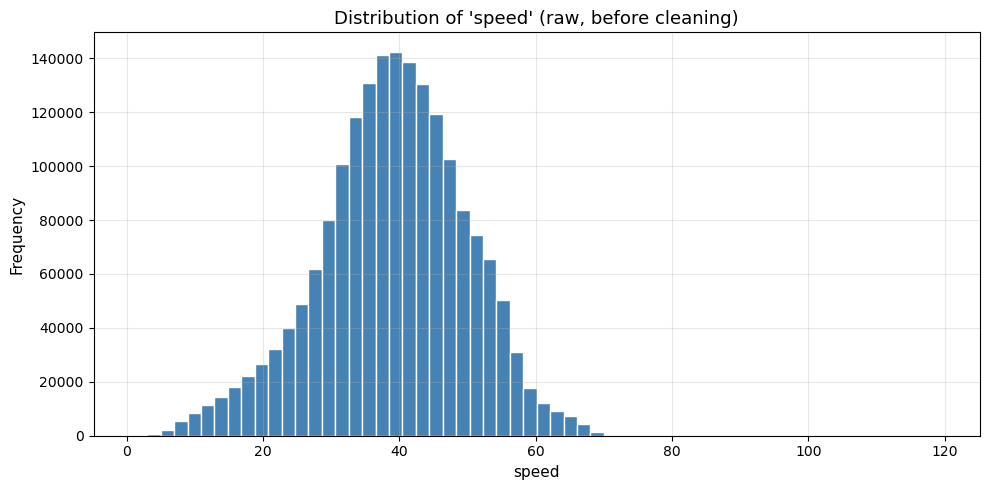

In [2]:
# ============================================================
# SECTION 2: LOAD DATASET
# Requires: Section 1 (DATA_PATH, pd, np, plt)
# ============================================================

# ------------------------------------------------------------
# 1. Load the CSV 
# ------------------------------------------------------------
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}\n"
        "Update DATA_PATH in Section 1 to point to your CSV file."
    )

df = pd.read_csv(DATA_PATH, low_memory=False)

print("Dataset loaded successfully.")
print(f"File size      : {os.path.getsize(DATA_PATH) / 1e6:,.2f} MB")
print(f"Rows x Columns : {df.shape[0]:,} x {df.shape[1]}")
print(f"Memory usage   : {df.memory_usage(deep=True).sum() / 1e6:,.2f} MB")

# ------------------------------------------------------------
# 2. Automatically detect column roles (no hardcoded names)
# ------------------------------------------------------------
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
float_cols   = df.select_dtypes(include=["float"]).columns.tolist()
int_cols     = [c for c in numeric_cols if c not in float_cols]

# --- Speed (value) column: the float column; fallback = most distinct values
if len(float_cols) >= 1:
    VALUE_COL = float_cols[0]
else:
    VALUE_COL = max(numeric_cols, key=lambda c: df[c].nunique())

# --- Index columns: everything numeric except the value column
candidate_idx = [c for c in numeric_cols if c != VALUE_COL]

def pick_by_hint(candidates, hints):
    """Return the first candidate whose name contains any hint, else None."""
    for col in candidates:
        if any(h in col.lower() for h in hints):
            return col
    return None

ROAD_COL = pick_by_hint(candidate_idx, ["road", "link", "sensor", "segment", "id_r"])
rest     = [c for c in candidate_idx if c != ROAD_COL]
DAY_COL  = pick_by_hint(rest, ["day", "date"])
rest     = [c for c in rest if c != DAY_COL]
TIME_COL = pick_by_hint(rest, ["time", "interval", "slot", "hour", "minute"])

# --- Fallback: if hints failed, assign by cardinality
#     (most unique values -> time, fewest -> day, middle -> road)
if None in (ROAD_COL, DAY_COL, TIME_COL):
    by_card = sorted(candidate_idx, key=lambda c: df[c].nunique())
    if len(by_card) < 3:
        raise ValueError(
            f"Expected 3 index columns (road, day, time), found: {by_card}"
        )
    DAY_COL, ROAD_COL, TIME_COL = by_card[0], by_card[1], by_card[2]
    print("\nNote: name hints failed, roles assigned by cardinality.")

INDEX_COLS = [ROAD_COL, DAY_COL, TIME_COL]

# ------------------------------------------------------------
# 3. Report detected roles and dimensions
# ------------------------------------------------------------
print("\n--- Detected column roles ---")
print(f"Value (speed) column : {VALUE_COL}")
print(f"Road column          : {ROAD_COL}  ({df[ROAD_COL].nunique()} unique)")
print(f"Day column           : {DAY_COL}  ({df[DAY_COL].nunique()} unique)")
print(f"Time column          : {TIME_COL}  ({df[TIME_COL].nunique()} unique)")

n_roads = df[ROAD_COL].nunique()
n_days  = df[DAY_COL].nunique()
n_times = df[TIME_COL].nunique()
expected_rows = n_roads * n_days * n_times

print("\n--- Completeness check (roads x days x times) ---")
print(f"Expected rows if fully observed : {expected_rows:,}")
print(f"Actual rows                     : {len(df):,}")
print(f"Missing combinations            : {expected_rows - len(df):,} "
      f"({(expected_rows - len(df)) / expected_rows:.2%})")

# ------------------------------------------------------------
# 4. Preview the data
# ------------------------------------------------------------
print("\n--- First 5 rows ---")
display(df.head())

print("--- Last 5 rows ---")
display(df.tail())

# ------------------------------------------------------------
# 5. Quick visual sanity check: distribution of the speed values
# ------------------------------------------------------------
fig, ax = plt.subplots()
ax.hist(df[VALUE_COL], bins=60, color="steelblue", edgecolor="white")
ax.set_title(f"Distribution of '{VALUE_COL}' (raw, before cleaning)")
ax.set_xlabel(VALUE_COL)
ax.set_ylabel("Frequency")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "02_speed_distribution_raw.png"), dpi=150)
plt.show()

In [3]:
# ============================================================
# SECTION 3: DATASET INSPECTION
# Requires: Section 1 (imports, OUTPUT_DIR) and Section 2
#           (df, VALUE_COL, ROAD_COL, DAY_COL, TIME_COL, INDEX_COLS)
# NOTE: this section only INSPECTS the data. Nothing is modified.
# ============================================================

# Guard: make sure Section 2 variables exist
for _name in ["df", "VALUE_COL", "ROAD_COL", "DAY_COL", "TIME_COL", "INDEX_COLS"]:
    if _name not in globals():
        raise NameError(f"'{_name}' is missing. Please run Sections 1 and 2 first.")

# ------------------------------------------------------------
# 1. Structure: shape, dtypes, memory
# ------------------------------------------------------------
print("=" * 60)
print("1. STRUCTURE")
print("=" * 60)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns\n")
df.info(memory_usage="deep")

# ------------------------------------------------------------
# 2. Missing values (NaN) and duplicates
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("2. MISSING VALUES AND DUPLICATES")
print("=" * 60)
nan_counts = df.isna().sum().to_frame("n_missing")
nan_counts["pct_missing"] = 100 * nan_counts["n_missing"] / len(df)
display(nan_counts)

n_dup_rows = int(df.duplicated().sum())
n_dup_keys = int(df.duplicated(subset=INDEX_COLS).sum())
print(f"Fully duplicated rows                      : {n_dup_rows:,}")
print(f"Duplicated (road, day, time) combinations  : {n_dup_keys:,}")

# ------------------------------------------------------------
# 3. Index columns: ranges and contiguity
#    (important for turning the data into a matrix/tensor later)
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("3. INDEX COLUMNS")
print("=" * 60)
road_ids = np.sort(df[ROAD_COL].unique())
day_ids  = np.sort(df[DAY_COL].unique())
time_ids = np.sort(df[TIME_COL].unique())

index_summary = pd.DataFrame({
    "role":        ["road", "day", "time"],
    "n_unique":    [len(road_ids), len(day_ids), len(time_ids)],
    "min":         [road_ids.min(), day_ids.min(), time_ids.min()],
    "max":         [road_ids.max(), day_ids.max(), time_ids.max()],
    "contiguous":  [
        bool(road_ids.max() - road_ids.min() + 1 == len(road_ids)),
        bool(day_ids.max()  - day_ids.min()  + 1 == len(day_ids)),
        bool(time_ids.max() - time_ids.min() + 1 == len(time_ids)),
    ],
}, index=[ROAD_COL, DAY_COL, TIME_COL])
display(index_summary)

if len(time_ids) > 0 and 1440 % len(time_ids) == 0:
    print(f"\n{len(time_ids)} intervals per day -> each interval is about "
          f"{1440 // len(time_ids)} minutes if the day is fully covered.")

1. STRUCTURE
Shape: 1,855,589 rows x 4 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1855589 entries, 0 to 1855588
Data columns (total 4 columns):
 #   Column   Dtype  
---  ------   -----  
 0   road_id  int64  
 1   day_id   int64  
 2   time_id  int64  
 3   speed    float64
dtypes: float64(1), int64(3)
memory usage: 56.6 MB

2. MISSING VALUES AND DUPLICATES


,n_missing,pct_missing
road_id,0,0.0000
day_id,0,0.0000
time_id,0,0.0000
speed,0,0.0000


Fully duplicated rows                      : 0
Duplicated (road, day, time) combinations  : 0

3. INDEX COLUMNS


,role,n_unique,min,max,contiguous
road_id,road,214,1,214,True
day_id,day,61,1,61,True
time_id,time,144,1,144,True



144 intervals per day -> each interval is about 10 minutes if the day is fully covered.


In [4]:
# 4. Descriptive statistics of the speed values
# ------------------------------------------------------------
print("\n" + "=" * 60)
print(f"4. DESCRIPTIVE STATISTICS OF '{VALUE_COL}'")
print("=" * 60)
speed = df[VALUE_COL]
speed_summary = speed.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("value")
speed_summary.loc["skewness"] = stats.skew(speed.dropna())
speed_summary.loc["kurtosis (excess)"] = stats.kurtosis(speed.dropna())
display(speed_summary)

# Outlier screening with the IQR rule (reporting only, no removal)
q1, q3 = speed.quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_low  = int((speed < lower_fence).sum())
n_high = int((speed > upper_fence).sum())
print(f"IQR fences           : [{lower_fence:,.2f}, {upper_fence:,.2f}]")
print(f"Below lower fence    : {n_low:,} ({n_low / len(df):.3%})")
print(f"Above upper fence    : {n_high:,} ({n_high / len(df):.3%})")
print(f"Non-positive speeds  : {int((speed <= 0).sum()):,}")



4. DESCRIPTIVE STATISTICS OF 'speed'


,value
count,"1,855,589.0000"
mean,39.0074
std,10.8242
min,1.0540
1%,11.2310
5%,19.5500
25%,32.4060
50%,39.3740
75%,46.3190
95%,55.8140


IQR fences           : [11.54, 67.19]
Below lower fence    : 20,190 (1.088%)
Above upper fence    : 3,411 (0.184%)
Non-positive speeds  : 0


In [5]:
# ------------------------------------------------------------
# 5. Coverage: which (road, day, time) combinations are absent?
#    Boolean cube observed_mask_3d[road, day, time]
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("5. COVERAGE OF THE ROAD x DAY x TIME GRID")
print("=" * 60)
r_idx = np.searchsorted(road_ids, df[ROAD_COL].to_numpy())
d_idx = np.searchsorted(day_ids,  df[DAY_COL].to_numpy())
t_idx = np.searchsorted(time_ids, df[TIME_COL].to_numpy())

observed_mask_3d = np.zeros((len(road_ids), len(day_ids), len(time_ids)), dtype=bool)
observed_mask_3d[r_idx, d_idx, t_idx] = True

n_cells    = observed_mask_3d.size
n_observed = int(observed_mask_3d.sum())
n_absent   = n_cells - n_observed
print(f"Grid size (roads x days x times) : {observed_mask_3d.shape}")
print(f"Observed cells                   : {n_observed:,}")
print(f"Absent cells                     : {n_absent:,} ({n_absent / n_cells:.2%})")

# Absent counts along each axis
absent_3d = ~observed_mask_3d
absent_by_road = pd.Series(absent_3d.sum(axis=(1, 2)), index=road_ids, name="absent")
absent_by_day  = pd.Series(absent_3d.sum(axis=(0, 2)), index=day_ids,  name="absent")
absent_by_time = pd.Series(absent_3d.sum(axis=(0, 1)), index=time_ids, name="absent")

print(f"\nRoads with at least one absent cell : {(absent_by_road > 0).sum()} / {len(road_ids)}")
print(f"Days with at least one absent cell  : {(absent_by_day  > 0).sum()} / {len(day_ids)}")
print(f"Times with at least one absent cell : {(absent_by_time > 0).sum()} / {len(time_ids)}")

print("\nTop 5 roads by absent cells:")
display(absent_by_road.sort_values(ascending=False).head(5).to_frame())
print("Top 5 days by absent cells:")
display(absent_by_day.sort_values(ascending=False).head(5).to_frame())


5. COVERAGE OF THE ROAD x DAY x TIME GRID
Grid size (roads x days x times) : (214, 61, 144)
Observed cells                   : 1,855,589
Absent cells                     : 24,187 (1.29%)

Roads with at least one absent cell : 8 / 214
Days with at least one absent cell  : 42 / 61
Times with at least one absent cell : 144 / 144

Top 5 roads by absent cells:


,absent
123,5904
48,4464
146,4464
147,4464
55,4464


Top 5 days by absent cells:


,absent
23,750
1,720
17,720
2,720
30,720


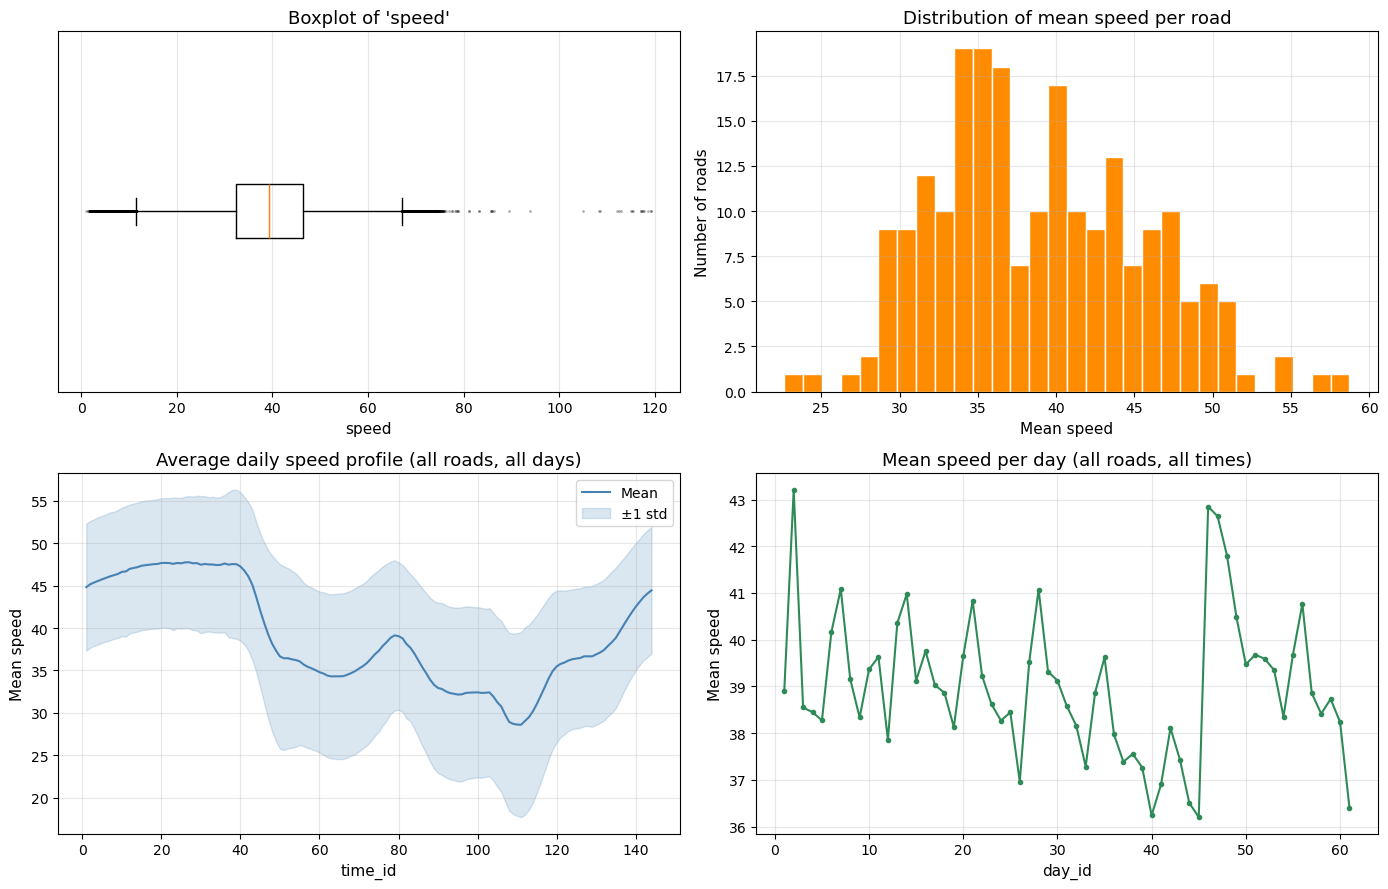

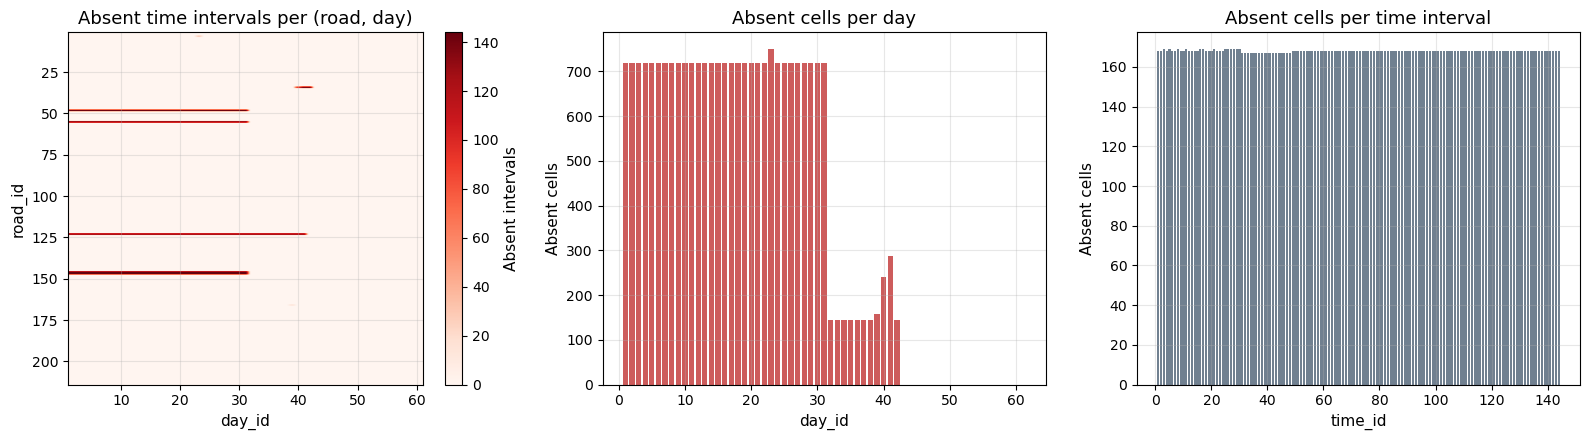


Section 3 complete. Variables available for later sections:
  road_ids, day_ids, time_ids, observed_mask_3d, speed_summary, absent_by_road, absent_by_day, absent_by_time


In [6]:
# ------------------------------------------------------------
# 6. Visualizations
# ------------------------------------------------------------
# --- Figure 1: speed distribution and daily profile -------------------
mean_by_time = df.groupby(TIME_COL)[VALUE_COL].mean()
std_by_time  = df.groupby(TIME_COL)[VALUE_COL].std()
road_mean    = df.groupby(ROAD_COL)[VALUE_COL].mean()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].boxplot(speed, vert=False, showfliers=True,
                   flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[0, 0].set_title(f"Boxplot of '{VALUE_COL}'")
axes[0, 0].set_xlabel(VALUE_COL)
axes[0, 0].set_yticks([])

axes[0, 1].hist(road_mean, bins=30, color="darkorange", edgecolor="white")
axes[0, 1].set_title("Distribution of mean speed per road")
axes[0, 1].set_xlabel(f"Mean {VALUE_COL}")
axes[0, 1].set_ylabel("Number of roads")

axes[1, 0].plot(mean_by_time.index, mean_by_time.values, color="steelblue", label="Mean")
axes[1, 0].fill_between(mean_by_time.index,
                        mean_by_time - std_by_time,
                        mean_by_time + std_by_time,
                        color="steelblue", alpha=0.2, label="±1 std")
axes[1, 0].set_title("Average daily speed profile (all roads, all days)")
axes[1, 0].set_xlabel(TIME_COL)
axes[1, 0].set_ylabel(f"Mean {VALUE_COL}")
axes[1, 0].legend()

mean_by_day = df.groupby(DAY_COL)[VALUE_COL].mean()
axes[1, 1].plot(mean_by_day.index, mean_by_day.values, marker="o", ms=3, color="seagreen")
axes[1, 1].set_title("Mean speed per day (all roads, all times)")
axes[1, 1].set_xlabel(DAY_COL)
axes[1, 1].set_ylabel(f"Mean {VALUE_COL}")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "03_speed_overview.png"), dpi=150)
plt.show()

# --- Figure 2: where are the absent observations? ---------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

im = axes[0].imshow(absent_3d.sum(axis=2), aspect="auto", cmap="Reds",
                    extent=[day_ids.min(), day_ids.max(), road_ids.max(), road_ids.min()])
axes[0].set_title("Absent time intervals per (road, day)")
axes[0].set_xlabel(DAY_COL)
axes[0].set_ylabel(ROAD_COL)
plt.colorbar(im, ax=axes[0], label="Absent intervals")

axes[1].bar(absent_by_day.index, absent_by_day.values, color="indianred")
axes[1].set_title("Absent cells per day")
axes[1].set_xlabel(DAY_COL)
axes[1].set_ylabel("Absent cells")

axes[2].bar(absent_by_time.index, absent_by_time.values, color="slategray")
axes[2].set_title("Absent cells per time interval")
axes[2].set_xlabel(TIME_COL)
axes[2].set_ylabel("Absent cells")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "03_absent_cells.png"), dpi=150)
plt.show()

print("\nSection 3 complete. Variables available for later sections:")
print("  road_ids, day_ids, time_ids, observed_mask_3d, speed_summary, "
      "absent_by_road, absent_by_day, absent_by_time")

Invalid speeds (non-finite or <= 0) set to missing: 0

Roads in raw data       : 214
Roads dropped (> 20% missing): 5 -> [48, 55, 123, 146, 147]
Roads kept              : 209


,missing_fraction
123,0.6721
48,0.5082
55,0.5082
146,0.5082
147,0.5082
34,0.0437
3,0.0034
166,0.0015



Cells still missing among kept roads: 427 (0.0233%)
Road-day series repaired : 5
Cells imputed            : 427
Remaining NaN            : 0

--- Validation ---
df_clean shape          : (1835856, 5)
Complete grid           : 209 roads x 61 days x 144 times = 1,835,856 rows
Imputed share of data   : 0.0233%


,raw (all roads),cleaned (kept roads)
count,"1,855,589.0000","1,835,856.0000"
mean,39.0074,39.1153
std,10.8242,10.7699
min,1.0540,1.4790
25%,32.4060,32.5010
50%,39.3740,39.4600
75%,46.3190,46.4000
max,119.2700,119.2700



IQR-flagged values kept in the data: 21,742 (1.184%) - retained on purpose, since they may be real traffic anomalies.


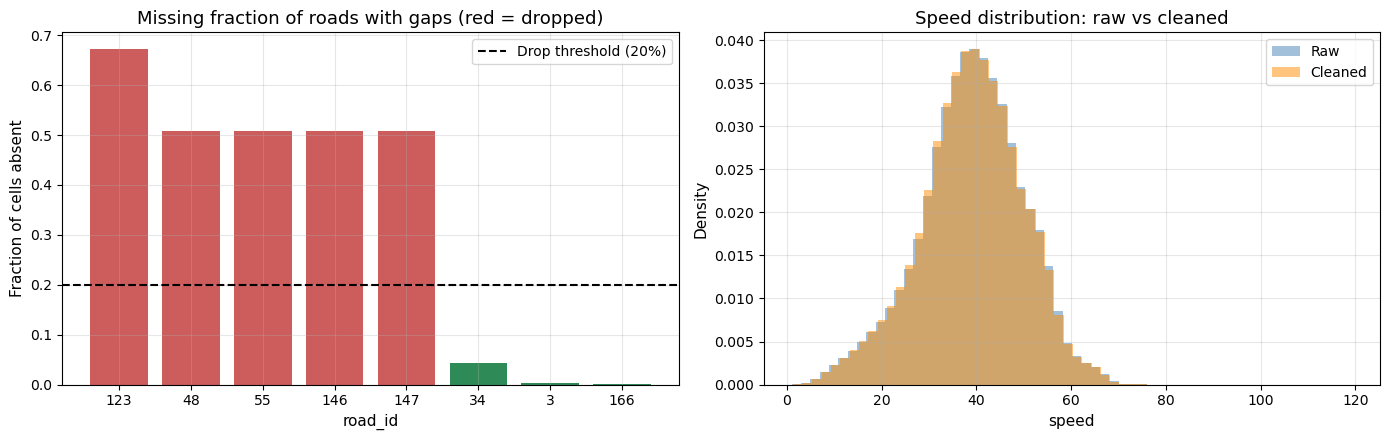

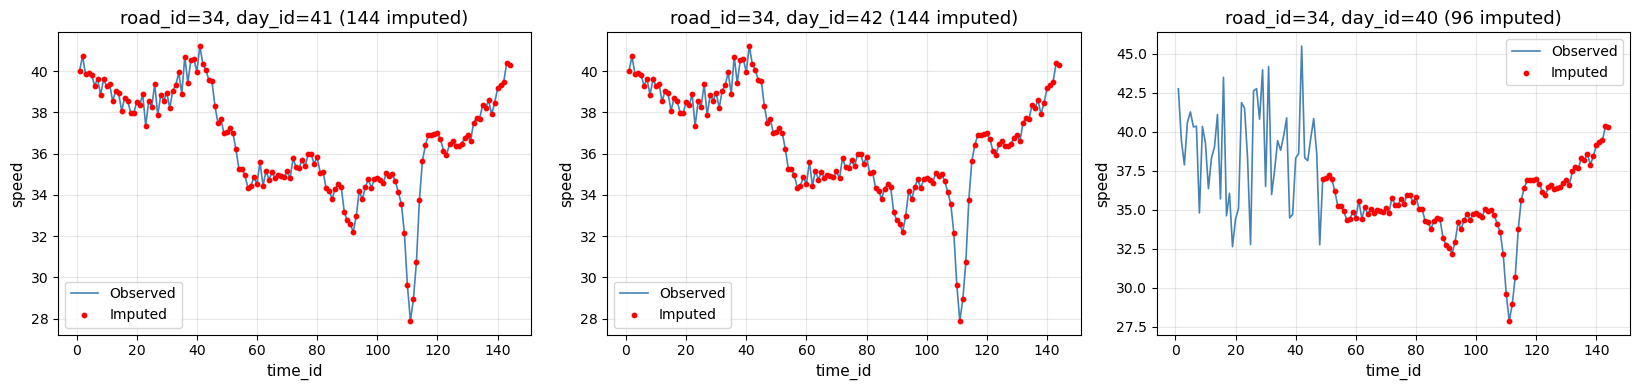


Section 4 complete. Variables available for later sections:
  df_clean, road_ids_clean, n_roads_clean, imputed_mask_3d, cube_filled, roads_dropped, MAX_ROAD_MISSING_FRAC, MAX_INTERP_GAP


In [7]:
# ============================================================
# SECTION 4: DATA CLEANING
# Requires: Sections 1-3
#   (df, VALUE_COL, ROAD_COL, DAY_COL, TIME_COL, INDEX_COLS,
#    road_ids, day_ids, time_ids, observed_mask_3d, absent_by_road)
# Output: df_clean (complete grid, no NaN) with an 'is_imputed' flag
# ============================================================

for _name in ["df", "VALUE_COL", "ROAD_COL", "DAY_COL", "TIME_COL", "INDEX_COLS",
              "road_ids", "day_ids", "time_ids", "observed_mask_3d"]:
    if _name not in globals():
        raise NameError(f"'{_name}' is missing. Please run Sections 1-3 first.")

# ------------------------------------------------------------
# 0. Cleaning parameters 
# ------------------------------------------------------------
MAX_ROAD_MISSING_FRAC = 0.20   # drop roads with more than 20% of their cells absent
MAX_INTERP_GAP        = 6      # linear interpolation only for gaps <= 6 consecutive intervals

n_roads_raw, n_days_raw, n_times_raw = observed_mask_3d.shape
cells_per_road = n_days_raw * n_times_raw

# ------------------------------------------------------------
# 1. Treat physically invalid speeds as missing (none expected, but be safe)
# ------------------------------------------------------------
work = df[INDEX_COLS + [VALUE_COL]].copy()
invalid = ~np.isfinite(work[VALUE_COL]) | (work[VALUE_COL] <= 0)
print(f"Invalid speeds (non-finite or <= 0) set to missing: {int(invalid.sum()):,}")
work.loc[invalid, VALUE_COL] = np.nan

# ------------------------------------------------------------
# 2. Rebuild the full (road x day x time) cube with NaN where absent
# ------------------------------------------------------------
r_i = np.searchsorted(road_ids, work[ROAD_COL].to_numpy())
d_i = np.searchsorted(day_ids,  work[DAY_COL].to_numpy())
t_i = np.searchsorted(time_ids, work[TIME_COL].to_numpy())

cube_raw = np.full((n_roads_raw, n_days_raw, n_times_raw), np.nan)
cube_raw[r_i, d_i, t_i] = work[VALUE_COL].to_numpy()

# ------------------------------------------------------------
# 3. Decide which roads to drop 
# ------------------------------------------------------------
road_missing_frac = pd.Series(np.isnan(cube_raw).sum(axis=(1, 2)) / cells_per_road,
                              index=road_ids, name="missing_fraction")
roads_dropped = road_missing_frac[road_missing_frac > MAX_ROAD_MISSING_FRAC].index.to_numpy()
keep_mask = ~np.isin(road_ids, roads_dropped)
road_ids_clean = road_ids[keep_mask]
n_roads_clean = len(road_ids_clean)

print(f"\nRoads in raw data       : {n_roads_raw}")
print(f"Roads dropped (> {MAX_ROAD_MISSING_FRAC:.0%} missing): {len(roads_dropped)} -> {roads_dropped.tolist()}")
print(f"Roads kept              : {n_roads_clean}")
display(road_missing_frac[road_missing_frac > 0].sort_values(ascending=False).to_frame())

cube_k = cube_raw[keep_mask].copy()           # kept roads only
nan_before = np.isnan(cube_k)
print(f"\nCells still missing among kept roads: {int(nan_before.sum()):,} "
      f"({nan_before.mean():.4%})")

# ------------------------------------------------------------
# 4. Impute the remaining gaps
#    - short interior gaps  -> linear interpolation in time
#    - long / edge / whole-day gaps -> the road's median time-of-day profile
#    (A low-rank model is NOT used here, to avoid circular reasoning later.)
# ------------------------------------------------------------
global_profile = np.nanmedian(cube_k, axis=(0, 1))          # shape (times,)

def fill_series(values, profile, max_gap):
    """Fill NaNs in one road-day time series. Returns the filled copy."""
    out = values.copy()
    nan_mask = np.isnan(values)
    if not nan_mask.any():
        return out
    if nan_mask.all():                                       # entire day absent
        return profile.copy()
    padded = np.concatenate(([0], nan_mask.astype(np.int8), [0]))
    change = np.diff(padded)
    starts = np.where(change == 1)[0]
    ends   = np.where(change == -1)[0]                       # exclusive end
    for s, e in zip(starts, ends):
        interior = (s > 0) and (e < len(values))
        if interior and (e - s) <= max_gap:
            out[s:e] = np.interp(np.arange(s, e), [s - 1, e], [values[s - 1], values[e]])
        else:
            out[s:e] = profile[s:e]
    return out

cube_filled = cube_k.copy()
rows_to_fix = np.argwhere(nan_before.any(axis=2))            # (road, day) pairs with a gap
for r, d in rows_to_fix:
    road_profile = np.nanmedian(cube_k[r], axis=0)           # median over observed days
    road_profile = np.where(np.isnan(road_profile), global_profile, road_profile)
    cube_filled[r, d] = fill_series(cube_k[r, d], road_profile, MAX_INTERP_GAP)

assert not np.isnan(cube_filled).any(), "Some NaN values remain after imputation."
imputed_mask_3d = nan_before                                  # True where a value was imputed
print(f"Road-day series repaired : {len(rows_to_fix)}")
print(f"Cells imputed            : {int(imputed_mask_3d.sum()):,}")
print(f"Remaining NaN            : {int(np.isnan(cube_filled).sum())}")

# ------------------------------------------------------------
# 5. Build the cleaned long-format DataFrame (sorted by road, day, time)
# ------------------------------------------------------------
ri, di, ti = np.indices(cube_filled.shape)
df_clean = pd.DataFrame({
    ROAD_COL:  road_ids_clean[ri.ravel()],
    DAY_COL:   day_ids[di.ravel()],
    TIME_COL:  time_ids[ti.ravel()],
    VALUE_COL: cube_filled.ravel(),
    "is_imputed": imputed_mask_3d.ravel(),
})

# ------------------------------------------------------------
# 6. Validation checks
# ------------------------------------------------------------
expected = n_roads_clean * len(day_ids) * len(time_ids)
assert len(df_clean) == expected, "Cleaned grid is not complete."
assert df_clean.duplicated(subset=INDEX_COLS).sum() == 0
assert df_clean[VALUE_COL].notna().all() and (df_clean[VALUE_COL] > 0).all()

print("\n--- Validation ---")
print(f"df_clean shape          : {df_clean.shape}")
print(f"Complete grid           : {n_roads_clean} roads x {len(day_ids)} days x {len(time_ids)} times = {expected:,} rows")
print(f"Imputed share of data   : {df_clean['is_imputed'].mean():.4%}")

compare = pd.DataFrame({
    "raw (all roads)":     df[VALUE_COL].describe(),
    "cleaned (kept roads)": df_clean[VALUE_COL].describe(),
})
display(compare)

# Outliers are deliberately KEPT: they may be genuine congestion events.
q1, q3 = df_clean[VALUE_COL].quantile([0.25, 0.75])
iqr = q3 - q1
n_out = int(((df_clean[VALUE_COL] < q1 - 1.5 * iqr) | (df_clean[VALUE_COL] > q3 + 1.5 * iqr)).sum())
print(f"\nIQR-flagged values kept in the data: {n_out:,} ({n_out / len(df_clean):.3%}) "
      "- retained on purpose, since they may be real traffic anomalies.")

# ------------------------------------------------------------
# 7. Visualizations
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# (a) missing fraction per road for the affected roads, with the drop threshold
affected = road_missing_frac[road_missing_frac > 0].sort_values(ascending=False)
bar_colors = ["indianred" if v > MAX_ROAD_MISSING_FRAC else "seagreen" for v in affected.values]
axes[0].bar(affected.index.astype(str), affected.values, color=bar_colors)
axes[0].axhline(MAX_ROAD_MISSING_FRAC, color="black", ls="--", label=f"Drop threshold ({MAX_ROAD_MISSING_FRAC:.0%})")
axes[0].set_title("Missing fraction of roads with gaps (red = dropped)")
axes[0].set_xlabel(ROAD_COL)
axes[0].set_ylabel("Fraction of cells absent")
axes[0].legend()

# (b) speed distribution before vs after cleaning
axes[1].hist(df[VALUE_COL], bins=60, density=True, alpha=0.5, label="Raw", color="steelblue")
axes[1].hist(df_clean[VALUE_COL], bins=60, density=True, alpha=0.5, label="Cleaned", color="darkorange")
axes[1].set_title("Speed distribution: raw vs cleaned")
axes[1].set_xlabel(VALUE_COL)
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "04_cleaning_overview.png"), dpi=150)
plt.show()

# (c) example of imputed values on the road with most imputed cells
imputed_per_road = imputed_mask_3d.sum(axis=(1, 2))
if imputed_per_road.max() > 0:
    ex_r = int(np.argmax(imputed_per_road))
    imputed_per_day = imputed_mask_3d[ex_r].sum(axis=1)
    ex_days = np.argsort(imputed_per_day)[::-1][:3]
    ex_days = [d for d in ex_days if imputed_per_day[d] > 0]

    fig, axes = plt.subplots(1, len(ex_days), figsize=(5.5 * len(ex_days), 4), squeeze=False)
    for ax, d in zip(axes[0], ex_days):
        series = cube_filled[ex_r, d]
        m = imputed_mask_3d[ex_r, d]
        ax.plot(time_ids, series, color="steelblue", lw=1.2, label="Observed")
        ax.scatter(time_ids[m], series[m], color="red", s=10, zorder=3, label="Imputed")
        ax.set_title(f"{ROAD_COL}={road_ids_clean[ex_r]}, {DAY_COL}={day_ids[d]} "
                     f"({int(m.sum())} imputed)")
        ax.set_xlabel(TIME_COL)
        ax.set_ylabel(VALUE_COL)
        ax.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "04_imputation_example.png"), dpi=150)
    plt.show()

print("\nSection 4 complete. Variables available for later sections:")
print("  df_clean, road_ids_clean, n_roads_clean, imputed_mask_3d, "
      "cube_filled, roads_dropped, MAX_ROAD_MISSING_FRAC, MAX_INTERP_GAP")

Cross-check passed: X equals the Section 4 cube reshaped to (roads, days*times).

--- Matrix X ---
Shape (m x n)           : 209 x 8784
  m = roads             : 209
  n = days x time slots : 61 x 144 = 8,784
Data type               : float64
Memory                  : 14.69 MB
Largest possible rank   : min(m, n) = 209
Min / Mean / Max        : 1.479 / 39.115 / 119.270
Frobenius norm ||X||_F  : 54,971.0845

--- Interpretation ---
Row i    : the full 8,784-point speed history of road i (a vector in R^8784).
Column j : a snapshot of the whole network at one time slot (a vector in R^209).
The column space of X lives in R^209; its dimension is rank(X) <= 209.

Top-left 6x6 corner of X (road rows, (day, time) columns):


,d1-t1,d1-t2,d1-t3,d1-t4,d1-t5,d1-t6
road 1,40.8930,41.9380,44.0980,44.4830,44.1720,44.4160
road 2,50.3190,51.1300,50.0190,52.8580,53.0710,52.9180
road 3,53.8800,53.6070,56.3250,54.0680,57.9490,57.0380
road 4,37.3050,37.5010,35.2320,39.0550,40.8980,38.7930
road 5,38.3880,38.3830,37.3020,40.3740,40.5740,40.9800
road 6,49.1300,47.3030,51.0050,46.3890,49.3780,45.6070


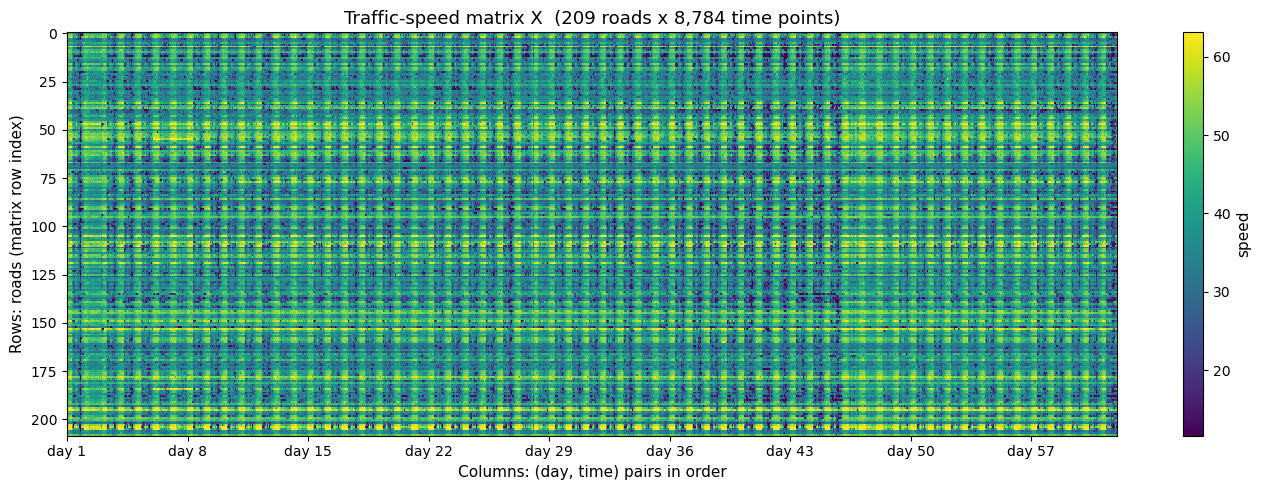

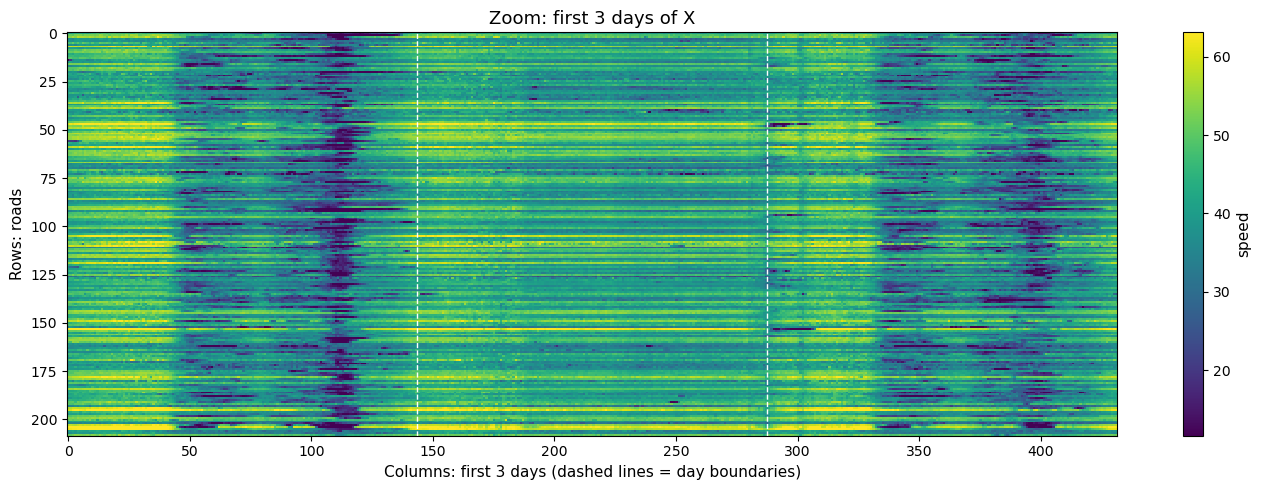

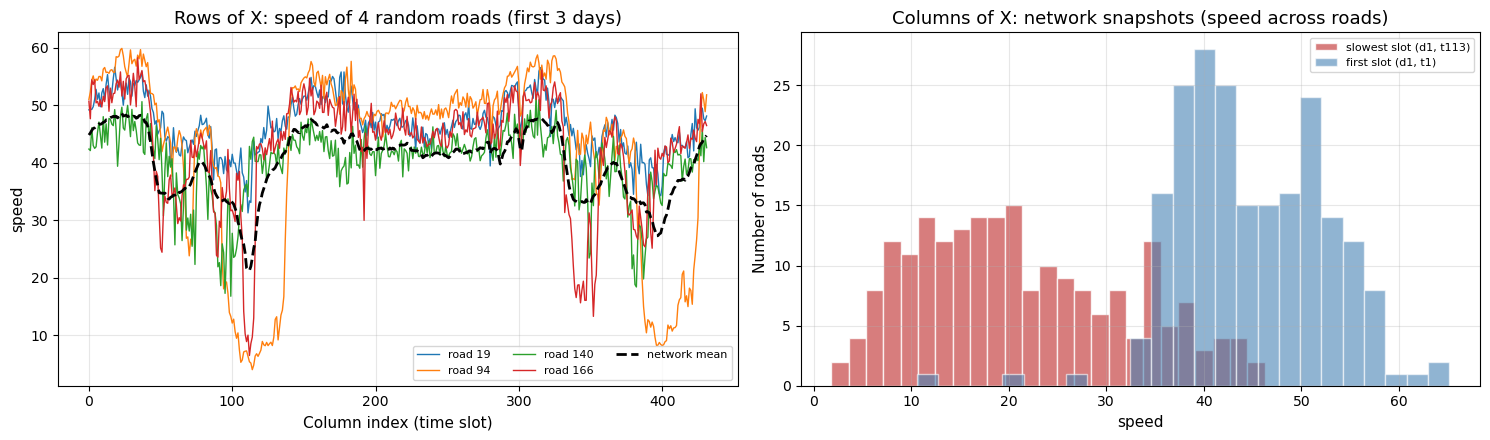


Section 5 complete. Variables available for later sections:
  X, X_imputed_mask, row_labels, col_labels, m, n, fro_X


In [8]:
# ============================================================
# SECTION 5: MATRIX REPRESENTATION
# Requires: Sections 1-4
#   (df_clean, ROAD_COL, DAY_COL, TIME_COL, VALUE_COL,
#    road_ids_clean, n_roads_clean, day_ids, time_ids, cube_filled)
# Output: X (roads x (days*times)), X_imputed_mask, col_labels, fro_X
# ============================================================

for _name in ["df_clean", "ROAD_COL", "DAY_COL", "TIME_COL", "VALUE_COL",
              "road_ids_clean", "n_roads_clean", "day_ids", "time_ids"]:
    if _name not in globals():
        raise NameError(f"'{_name}' is missing. Please run Sections 1-4 first.")

# ------------------------------------------------------------
# 1. Pivot the long table into a wide matrix
#    rows    -> roads
#    columns -> (day, time) pairs, ordered day by day
# ------------------------------------------------------------
wide = df_clean.pivot(index=ROAD_COL, columns=[DAY_COL, TIME_COL], values=VALUE_COL)
wide = wide.sort_index(axis=0).sort_index(axis=1)          # ascending road, day, time

wide_imp = df_clean.pivot(index=ROAD_COL, columns=[DAY_COL, TIME_COL], values="is_imputed")
wide_imp = wide_imp.sort_index(axis=0).sort_index(axis=1)

# The main data matrix X (a plain NumPy array, float64)
X = wide.to_numpy(dtype=float)
X_imputed_mask = wide_imp.to_numpy(dtype=bool)             # True where a value was imputed
row_labels = wide.index.to_numpy()                         # road ids, length m
col_labels = wide.columns.to_list()                        # (day, time) tuples, length n

m, n = X.shape
n_days_clean  = len(day_ids)
n_times_clean = len(time_ids)

# ------------------------------------------------------------
# 2. Integrity checks
# ------------------------------------------------------------
assert m == n_roads_clean, "Row count does not match the number of kept roads."
assert n == n_days_clean * n_times_clean, "Column count must equal days x times."
assert not np.isnan(X).any(), "X contains NaN values."
assert np.array_equal(row_labels, road_ids_clean), "Row order differs from road_ids_clean."

# Cross-check against the cube from Section 4 (if it is available)
if "cube_filled" in globals():
    assert np.allclose(X, cube_filled.reshape(m, -1)), "X does not match cube_filled."
    print("Cross-check passed: X equals the Section 4 cube reshaped to (roads, days*times).")

print("\n--- Matrix X ---")
print(f"Shape (m x n)           : {m} x {n}")
print(f"  m = roads             : {m}")
print(f"  n = days x time slots : {n_days_clean} x {n_times_clean} = {n:,}")
print(f"Data type               : {X.dtype}")
print(f"Memory                  : {X.nbytes / 1e6:,.2f} MB")
print(f"Largest possible rank   : min(m, n) = {min(m, n)}")
print(f"Min / Mean / Max        : {X.min():.3f} / {X.mean():.3f} / {X.max():.3f}")

# Frobenius norm of X: ||X||_F = sqrt(sum of all squared entries)
fro_X = np.linalg.norm(X, ord="fro")
print(f"Frobenius norm ||X||_F  : {fro_X:,.4f}")

# ------------------------------------------------------------
# 3. Linear-algebra interpretation
# ------------------------------------------------------------
print("\n--- Interpretation ---")
print(f"Row i    : the full {n:,}-point speed history of road i (a vector in R^{n}).")
print(f"Column j : a snapshot of the whole network at one time slot (a vector in R^{m}).")
print(f"The column space of X lives in R^{m}; its dimension is rank(X) <= {min(m, n)}.")

# Show a small corner of the matrix with labels
corner_rows, corner_cols = 6, 6
print(f"\nTop-left {corner_rows}x{corner_cols} corner of X (road rows, (day, time) columns):")
display(pd.DataFrame(X[:corner_rows, :corner_cols],
                     index=[f"road {r}" for r in row_labels[:corner_rows]],
                     columns=[f"d{d}-t{t}" for d, t in col_labels[:corner_cols]]))

# ------------------------------------------------------------
# 4. Visualizations
# ------------------------------------------------------------
vmin, vmax = np.percentile(X, [1, 99])      # robust colour range

# --- Figure 1: the whole matrix as a heatmap -------------------------
fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(X, aspect="auto", cmap="viridis", vmin=vmin, vmax=vmax,
               interpolation="nearest")
day_starts = np.arange(0, n, n_times_clean)
tick_step = max(1, len(day_starts) // 8)
ax.set_xticks(day_starts[::tick_step])
ax.set_xticklabels([f"day {col_labels[i][0]}" for i in day_starts[::tick_step]])
ax.set_xlabel("Columns: (day, time) pairs in order")
ax.set_ylabel("Rows: roads (matrix row index)")
ax.set_title(f"Traffic-speed matrix X  ({m} roads x {n:,} time points)")
ax.grid(False)
plt.colorbar(im, ax=ax, label=VALUE_COL)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "05_matrix_heatmap_full.png"), dpi=150)
plt.show()

# --- Figure 2: zoom on the first 3 days ------------------------------
zoom_days = min(3, n_days_clean)
zoom_n = zoom_days * n_times_clean
fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(X[:, :zoom_n], aspect="auto", cmap="viridis", vmin=vmin, vmax=vmax,
               interpolation="nearest")
for k in range(1, zoom_days):
    ax.axvline(k * n_times_clean - 0.5, color="white", ls="--", lw=1)
ax.set_xlabel(f"Columns: first {zoom_days} days (dashed lines = day boundaries)")
ax.set_ylabel("Rows: roads")
ax.set_title(f"Zoom: first {zoom_days} days of X")
ax.grid(False)
plt.colorbar(im, ax=ax, label=VALUE_COL)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "05_matrix_heatmap_zoom.png"), dpi=150)
plt.show()

# --- Figure 3: individual rows (road time series) and a column -------
rng = np.random.default_rng(RANDOM_STATE)
sample_rows = np.sort(rng.choice(m, size=4, replace=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for r in sample_rows:
    axes[0].plot(X[r, :zoom_n], lw=1, label=f"road {row_labels[r]}")
axes[0].plot(X[:, :zoom_n].mean(axis=0), color="black", lw=2, ls="--", label="network mean")
axes[0].set_title(f"Rows of X: speed of 4 random roads (first {zoom_days} days)")
axes[0].set_xlabel("Column index (time slot)")
axes[0].set_ylabel(VALUE_COL)
axes[0].legend(ncol=3, fontsize=8)

peak_col = int(np.argmin(X.mean(axis=0)))     # slot with the lowest network-average speed
axes[1].hist(X[:, peak_col], bins=25, color="indianred", edgecolor="white", alpha=0.8,
             label=f"slowest slot (d{col_labels[peak_col][0]}, t{col_labels[peak_col][1]})")
axes[1].hist(X[:, 0], bins=25, color="steelblue", edgecolor="white", alpha=0.6,
             label=f"first slot (d{col_labels[0][0]}, t{col_labels[0][1]})")
axes[1].set_title("Columns of X: network snapshots (speed across roads)")
axes[1].set_xlabel(VALUE_COL)
axes[1].set_ylabel("Number of roads")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "05_matrix_rows_columns.png"), dpi=150)
plt.show()

print("\nSection 5 complete. Variables available for later sections:")
print("  X, X_imputed_mask, row_labels, col_labels, m, n, fro_X")

In [9]:
# ============================================================
# SECTION 6: MATRIX RANK ANALYSIS
# Requires: Sections 1-5 (X, fro_X, m, n, n_times_clean, col_labels)
# Output: s_X, s_Xc, Xc, row_means, rank_summary, rank_vs_days
# ============================================================

for _name in ["X", "fro_X", "m", "n", "n_times_clean"]:
    if _name not in globals():
        raise NameError(f"'{_name}' is missing. Please run Sections 1-5 first.")

# ------------------------------------------------------------
# 1. Exact (numerical) rank of X
# ------------------------------------------------------------
# matrix_rank counts singular values above  tol = sigma_max * max(m, n) * eps
rank_default = np.linalg.matrix_rank(X)
print("--- Numerical rank of X ---")
print(f"Shape                       : {m} x {n}")
print(f"Maximum possible rank       : min(m, n) = {min(m, n)}")
print(f"np.linalg.matrix_rank(X)    : {rank_default}")

# ------------------------------------------------------------
# 2. Singular values (values only; the full SVD comes in Section 7)
#    sigma_i are the square roots of the eigenvalues of X X^T
# ------------------------------------------------------------
s_X = sla.svdvals(X)                         # descending order, length min(m, n)

# Row-centred copy: subtract each road's mean speed (this is what PCA does later)
row_means = X.mean(axis=1, keepdims=True)
Xc = X - row_means
s_Xc = sla.svdvals(Xc)

# Consistency check: ||X||_F^2 = sum of sigma_i^2
fro_from_s = np.sqrt(np.sum(s_X ** 2))
print(f"\n||X||_F from the data       : {fro_X:,.4f}")
print(f"sqrt(sum sigma_i^2)         : {fro_from_s:,.4f}")
assert np.isclose(fro_X, fro_from_s), "Frobenius norm and singular values disagree."

eps = np.finfo(float).eps
default_tol = s_X.max() * max(m, n) * eps
assert rank_default == int(np.sum(s_X > default_tol)), "Rank mismatch."

# ------------------------------------------------------------
# 3. Rank under different tolerances (relative to sigma_1)
# ------------------------------------------------------------
rel_tols = [1e-12, 1e-8, 1e-4, 1e-3, 1e-2, 5e-2, 1e-1]
tol_table = pd.DataFrame({
    "relative tol (tol / sigma_1)": [f"{t:.0e}" for t in rel_tols],
    "rank of X":  [int(np.sum(s_X  > t * s_X[0]))  for t in rel_tols],
    "rank of Xc": [int(np.sum(s_Xc > t * s_Xc[0])) for t in rel_tols],
})
print("\n--- Rank as a function of tolerance ---")
display(tol_table)

# ------------------------------------------------------------
# 4. Effective-rank measures
# ------------------------------------------------------------
def effective_rank_measures(s, thresholds=(0.90, 0.95, 0.99)):
    """Return a dict with several rank notions computed from singular values."""
    energy = s ** 2
    cum = np.cumsum(energy) / energy.sum()
    out = {f"k for {int(t * 100)}% energy": int(np.searchsorted(cum, t) + 1) for t in thresholds}
    out["stable rank  (||X||_F^2 / sigma_1^2)"] = float(energy.sum() / energy[0])
    p = s / s.sum()
    p = p[p > 0]
    out["entropy effective rank"] = float(np.exp(-np.sum(p * np.log(p))))
    out["sigma_1 energy share"] = float(cum[0])
    out["condition number (s_1 / s_min)"] = float(s[0] / s[-1])
    return out

rank_summary = pd.DataFrame({
    "X (raw)": effective_rank_measures(s_X),
    "Xc (row-centred)": effective_rank_measures(s_Xc),
})
print("\n--- Effective-rank summary ---")
display(rank_summary)

cum_X  = np.cumsum(s_X ** 2)  / np.sum(s_X ** 2)
cum_Xc = np.cumsum(s_Xc ** 2) / np.sum(s_Xc ** 2)

# Share of total energy captured by the first k components
ks = [k for k in [1, 2, 3, 5, 10, 20, 50, 100] if k <= len(s_X)]
energy_at_k = pd.DataFrame({
    "k": ks,
    "X (raw)":          [cum_X[k - 1]  for k in ks],
    "Xc (row-centred)": [cum_Xc[k - 1] for k in ks],
}).set_index("k")
print("\n--- Cumulative energy captured by the first k singular values ---")
display(energy_at_k.map(lambda v: f"{v:.2%}") if hasattr(energy_at_k, "map") else energy_at_k.applymap(lambda v: f"{v:.2%}"))

# ------------------------------------------------------------
# 5. How does the effective rank change with the amount of data used?
#    Use the first d days (columns) and recompute on the centred matrix.
# ------------------------------------------------------------
n_days_avail = n // n_times_clean
day_counts = sorted(set([1, 2, 3, 5, 7, 10, 15, 20, 30, 40, 50, n_days_avail]))
day_counts = [d for d in day_counts if d <= n_days_avail]

rows = []
for d in day_counts:
    Xd = X[:, : d * n_times_clean]
    Xd = Xd - Xd.mean(axis=1, keepdims=True)
    sd = sla.svdvals(Xd)
    cum_d = np.cumsum(sd ** 2) / np.sum(sd ** 2)
    rows.append({
        "days used": d,
        "columns": Xd.shape[1],
        "numerical rank": int(np.linalg.matrix_rank(Xd)),
        "k for 90% energy": int(np.searchsorted(cum_d, 0.90) + 1),
        "k for 95% energy": int(np.searchsorted(cum_d, 0.95) + 1),
        "k for 99% energy": int(np.searchsorted(cum_d, 0.99) + 1),
    })
rank_vs_days = pd.DataFrame(rows)
print("\n--- Rank vs. number of days used (row-centred) ---")
display(rank_vs_days)



--- Numerical rank of X ---
Shape                       : 209 x 8784
Maximum possible rank       : min(m, n) = 209
np.linalg.matrix_rank(X)    : 209

||X||_F from the data       : 54,971.0845
sqrt(sum sigma_i^2)         : 54,971.0845

--- Rank as a function of tolerance ---


,relative tol (tol / sigma_1),rank of X,rank of Xc
0,1e-12,209,209
1,1e-08,209,209
2,1e-04,209,209
3,1e-03,209,209
4,1e-02,33,209
5,5e-02,2,46
6,1e-01,1,8



--- Effective-rank summary ---


,X (raw),Xc (row-centred)
k for 90% energy,1.0000,55.0000
k for 95% energy,1.0000,102.0000
k for 99% energy,9.0000,174.0000
stable rank (||X||_F^2 / sigma_1^2),1.0206,1.5394
entropy effective rank,44.5677,144.7807
sigma_1 energy share,0.9798,0.6496
condition number (s_1 / s_min),389.1221,67.5070



--- Cumulative energy captured by the first k singular values ---


,X (raw),Xc (row-centred)
k,,
1,97.98%,64.96%
2,98.45%,70.36%
3,98.67%,73.05%
5,98.86%,75.61%
10,99.04%,79.16%
20,99.23%,83.05%
50,99.51%,89.31%
100,99.77%,94.87%



--- Rank vs. number of days used (row-centred) ---


,days used,columns,numerical rank,k for 90% energy,k for 95% energy,k for 99% energy
0,1,144,143,9,20,65
1,2,288,209,14,35,99
2,3,432,209,21,47,119
3,5,720,209,28,60,137
4,7,1008,209,35,70,149
5,10,1440,209,39,78,156
6,15,2160,209,44,85,163
7,20,2880,209,47,90,166
8,30,4320,209,50,95,169
9,40,5760,209,52,98,171


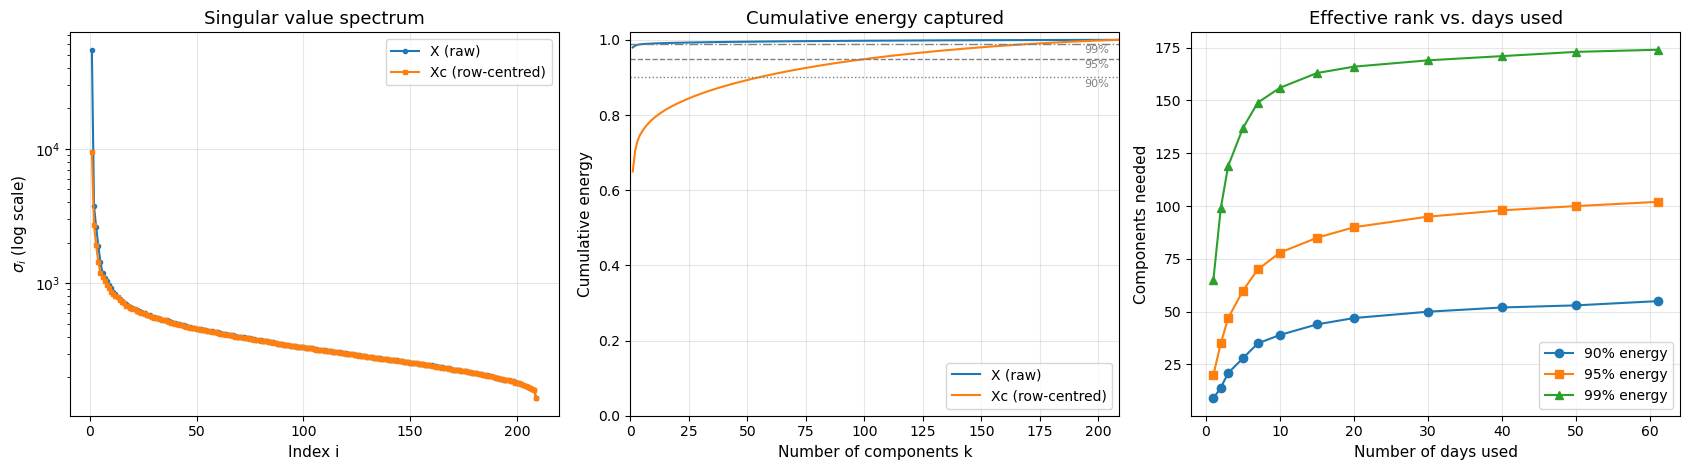

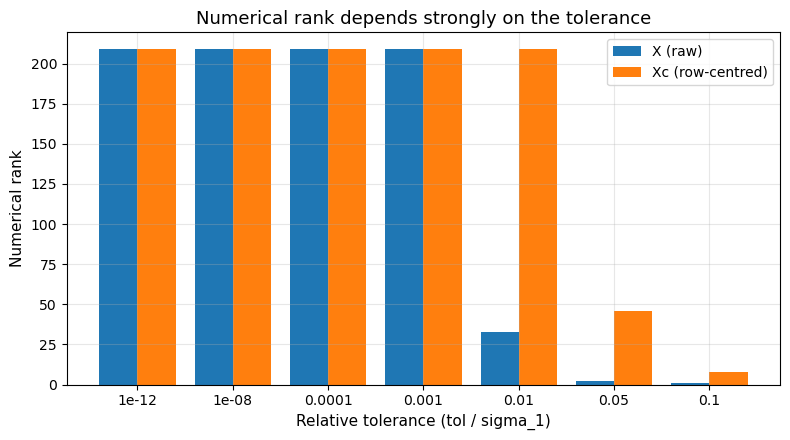


Section 6 complete. Variables available for later sections:
  s_X, s_Xc, Xc, row_means, rank_summary, tol_table, energy_at_k, rank_vs_days, cum_X, cum_Xc


In [10]:
# ------------------------------------------------------------
# 6. Visualizations
# ------------------------------------------------------------
idx = np.arange(1, len(s_X) + 1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# (a) Singular value spectrum (log scale)
axes[0].semilogy(idx, s_X,  "o-", ms=3, label="X (raw)")
axes[0].semilogy(idx, s_Xc, "s-", ms=3, label="Xc (row-centred)")
axes[0].set_title("Singular value spectrum")
axes[0].set_xlabel("Index i")
axes[0].set_ylabel(r"$\sigma_i$ (log scale)")
axes[0].legend()

# (b) Cumulative energy
axes[1].plot(idx, cum_X,  label="X (raw)")
axes[1].plot(idx, cum_Xc, label="Xc (row-centred)")
for t, ls in zip([0.90, 0.95, 0.99], [":", "--", "-."]):
    axes[1].axhline(t, color="gray", ls=ls, lw=1)
    axes[1].text(len(idx) * 0.98, t - 0.025, f"{int(t * 100)}%", ha="right", fontsize=8, color="gray")
axes[1].set_xlim(0, len(idx))
axes[1].set_ylim(0, 1.02)
axes[1].set_title("Cumulative energy captured")
axes[1].set_xlabel("Number of components k")
axes[1].set_ylabel("Cumulative energy")
axes[1].legend(loc="lower right")

# (c) Effective rank vs days of data
axes[2].plot(rank_vs_days["days used"], rank_vs_days["k for 90% energy"], "o-", label="90% energy")
axes[2].plot(rank_vs_days["days used"], rank_vs_days["k for 95% energy"], "s-", label="95% energy")
axes[2].plot(rank_vs_days["days used"], rank_vs_days["k for 99% energy"], "^-", label="99% energy")
axes[2].set_title("Effective rank vs. days used")
axes[2].set_xlabel("Number of days used")
axes[2].set_ylabel("Components needed")
axes[2].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "06_rank_analysis.png"), dpi=150)
plt.show()

# Tolerance sensitivity chart
fig, ax = plt.subplots(figsize=(8, 4.5))
xpos = np.arange(len(rel_tols))
ax.bar(xpos - 0.2, tol_table["rank of X"],  width=0.4, label="X (raw)")
ax.bar(xpos + 0.2, tol_table["rank of Xc"], width=0.4, label="Xc (row-centred)")
ax.set_xticks(xpos)
ax.set_xticklabels([f"{t:g}" for t in rel_tols])
ax.set_xlabel("Relative tolerance (tol / sigma_1)")
ax.set_ylabel("Numerical rank")
ax.set_title("Numerical rank depends strongly on the tolerance")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "06_rank_vs_tolerance.png"), dpi=150)
plt.show()

print("\nSection 6 complete. Variables available for later sections:")
print("  s_X, s_Xc, Xc, row_means, rank_summary, tol_table, energy_at_k, rank_vs_days, cum_X, cum_Xc")

--- Shapes of the SVD factors ---
X  = U  diag(S)  Vt   : U (209, 209), S (209,), Vt (209, 8784)
Xc = Uc diag(Sc) Vtc  : Uc (209, 209), Sc (209,), Vtc (209, 8784)

--- SVD verification ---


,X (raw),Xc (row-centred)
relative reconstruction error,1.10e-15,2.48e-15
max |U^T U - I|,2.00e-15,2.22e-15
max |V^T V - I|,1.78e-15,2.66e-15
S sorted descending,True,True
S non-negative,True,True


Singular values agree with Section 6 (svdvals).

Max relative gap between eig(Xc Xc^T) and Sc^2 : 2.37e-14

--- Leading modes of Xc ---


,singular value,energy share,cumulative energy
mode,,,
1,"9,431.9029",0.6496,0.6496
2,"2,719.9962",0.0540,0.7036
3,"1,918.3962",0.0269,0.7305
4,"1,440.0152",0.0151,0.7456
5,"1,197.8478",0.0105,0.7561
6,"1,113.3349",0.0091,0.7652
7,"1,038.4172",0.0079,0.7730
8,969.3270,0.0069,0.7799
9,923.5522,0.0062,0.7861



Correlation(u1 of X, road mean speed)            : 0.9979
Correlation(v1 of Xc, network-average deviation) : 0.9992
Roads whose u1 loading has the majority sign     : 100.0%


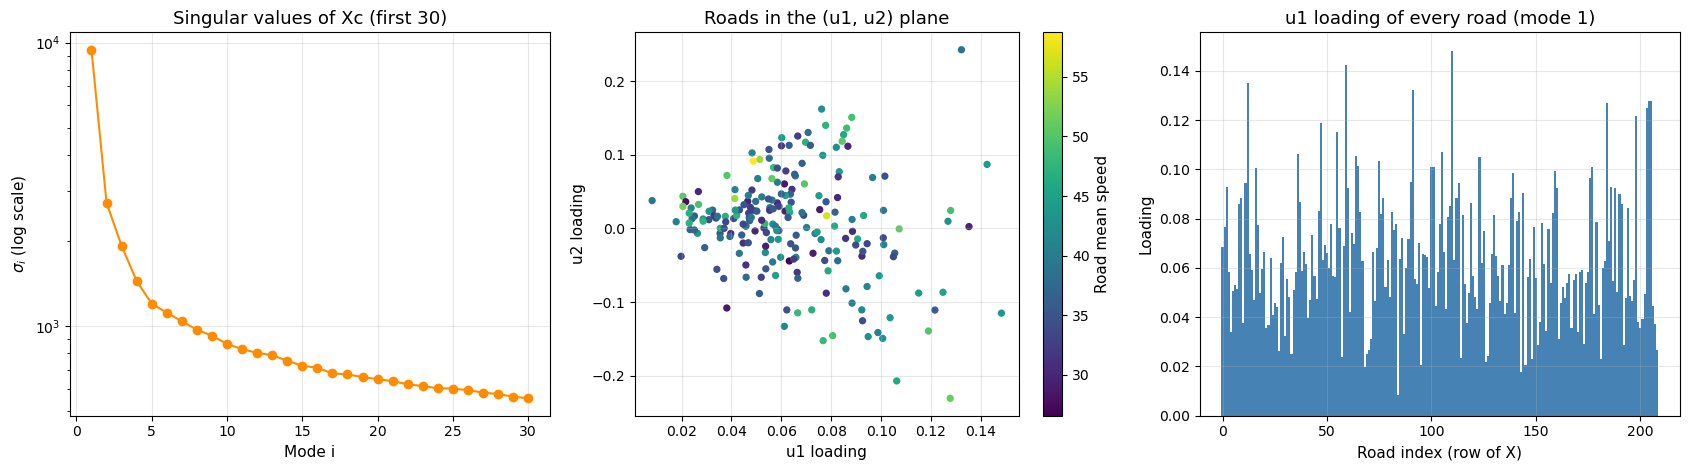

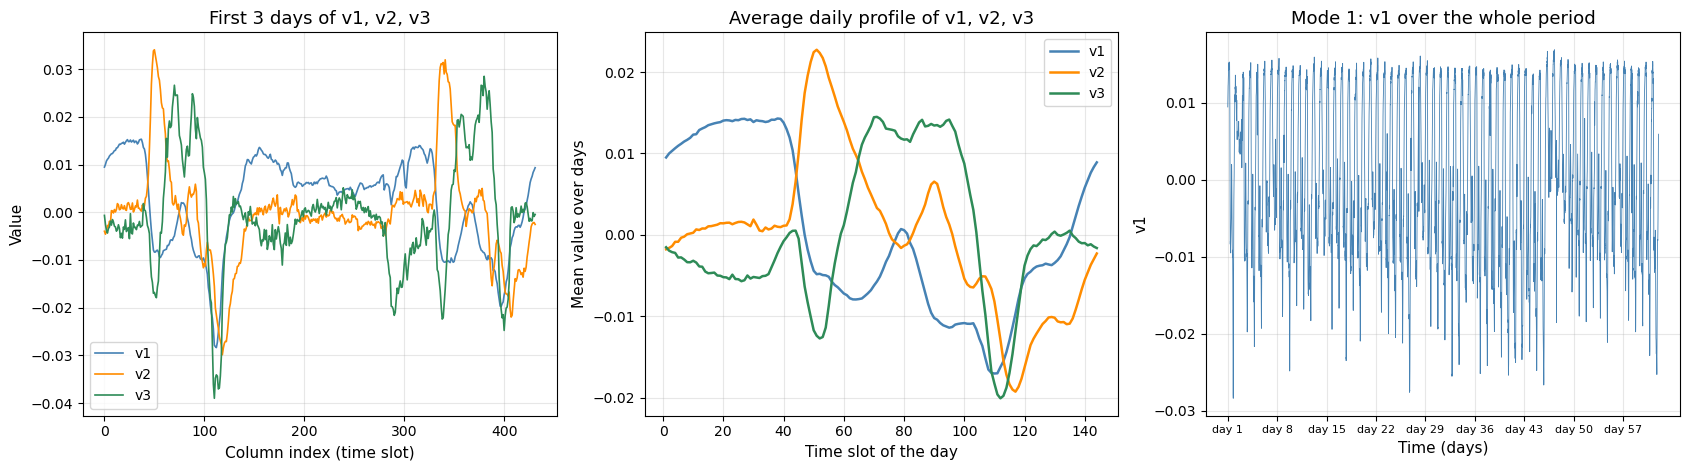


Section 7 complete. Variables available for later sections:
  U, S, Vt (SVD of X);  Uc, Sc, Vtc (SVD of Xc);  fix_signs, modes_table


In [11]:
# ============================================================
# SECTION 7: SINGULAR VALUE DECOMPOSITION (SVD)
# Requires: Sections 1-6
#   (X, Xc, row_means, s_X, s_Xc, fro_X, m, n, n_times_clean,
#    row_labels, time_ids)
# Output: U, S, Vt   (SVD of X)
#         Uc, Sc, Vtc (SVD of the row-centred matrix Xc)
# ============================================================

for _name in ["X", "Xc", "row_means", "s_X", "s_Xc", "fro_X", "m", "n",
              "n_times_clean", "row_labels", "time_ids"]:
    if _name not in globals():
        raise NameError(f"'{_name}' is missing. Please run Sections 1-6 first.")

# ------------------------------------------------------------
# 1. Compute the (economy-size) SVD:  A = U diag(S) Vt
#    U  : m x r   left singular vectors  (patterns across ROADS)
#    S  : r       singular values, descending
#    Vt : r x n   right singular vectors (patterns across TIME)
#    with r = min(m, n)
# ------------------------------------------------------------
def fix_signs(U_, Vt_):
    """SVD vectors are only defined up to a joint sign flip of (u_i, v_i).
    Make the largest-magnitude entry of every u_i positive for reproducibility."""
    idx = np.argmax(np.abs(U_), axis=0)
    signs = np.sign(U_[idx, np.arange(U_.shape[1])])
    signs[signs == 0] = 1.0
    return U_ * signs, Vt_ * signs[:, None]

U,  S,  Vt  = sla.svd(X,  full_matrices=False)
Uc, Sc, Vtc = sla.svd(Xc, full_matrices=False)
U,  Vt  = fix_signs(U,  Vt)
Uc, Vtc = fix_signs(Uc, Vtc)
r = len(S)

print("--- Shapes of the SVD factors ---")
print(f"X  = U  diag(S)  Vt   : U {U.shape}, S {S.shape}, Vt {Vt.shape}")
print(f"Xc = Uc diag(Sc) Vtc  : Uc {Uc.shape}, Sc {Sc.shape}, Vtc {Vtc.shape}")

# ------------------------------------------------------------
# 2. Verify the defining properties of the SVD
# ------------------------------------------------------------
def svd_checks(A, U_, S_, Vt_, name):
    recon = (U_ * S_) @ Vt_                                  # U diag(S) Vt
    rel_err = np.linalg.norm(A - recon, "fro") / np.linalg.norm(A, "fro")
    orth_U = np.max(np.abs(U_.T @ U_ - np.eye(U_.shape[1])))
    orth_V = np.max(np.abs(Vt_ @ Vt_.T - np.eye(Vt_.shape[0])))
    return {
        "relative reconstruction error": rel_err,
        "max |U^T U - I|": orth_U,
        "max |V^T V - I|": orth_V,
        "S sorted descending": bool(np.all(np.diff(S_) <= 0)),
        "S non-negative": bool(np.all(S_ >= 0)),
    }

checks = pd.DataFrame({
    "X (raw)": svd_checks(X, U, S, Vt, "X"),
    "Xc (row-centred)": svd_checks(Xc, Uc, Sc, Vtc, "Xc"),
})
print("\n--- SVD verification ---")
# Show tiny numbers in scientific notation (the default format would print 0.0000)
display(checks.map(lambda v: f"{v:.2e}" if isinstance(v, float) else str(v))
        if hasattr(checks, "map") else
        checks.applymap(lambda v: f"{v:.2e}" if isinstance(v, float) else str(v)))

# Agreement with the singular values computed in Section 6
assert np.allclose(S,  s_X),  "S differs from s_X (Section 6)."
assert np.allclose(Sc, s_Xc), "Sc differs from s_Xc (Section 6)."
print("Singular values agree with Section 6 (svdvals).")

# ------------------------------------------------------------
# 3. Link to eigenvalues:  sigma_i^2 = eigenvalues of X X^T
# ------------------------------------------------------------
eigvals = np.sort(np.linalg.eigvalsh(Xc @ Xc.T))[::-1]      # m x m Gram matrix
rel_gap = np.max(np.abs(eigvals - Sc ** 2) / np.maximum(Sc ** 2, 1e-12))
print(f"\nMax relative gap between eig(Xc Xc^T) and Sc^2 : {rel_gap:.2e}")

# ------------------------------------------------------------
# 4. Summary table of the leading modes (centred matrix)
# ------------------------------------------------------------
n_show = 10
energy_share = Sc ** 2 / np.sum(Sc ** 2)
modes_table = pd.DataFrame({
    "mode": np.arange(1, n_show + 1),
    "singular value": Sc[:n_show],
    "energy share": energy_share[:n_show],
    "cumulative energy": np.cumsum(energy_share)[:n_show],
}).set_index("mode")
print("\n--- Leading modes of Xc ---")
display(modes_table)

# ------------------------------------------------------------
# 5. Interpretation of the first modes
# ------------------------------------------------------------
# (a) Raw X: is the first left singular vector just the road mean level?
corr_u1_mean = np.corrcoef(U[:, 0], row_means.ravel())[0, 1]
print(f"\nCorrelation(u1 of X, road mean speed)            : {corr_u1_mean:.4f}")

# (b) Centred Xc: does the first right singular vector follow the network-wide speed change?
net_dev = Xc.mean(axis=0)                                    # average deviation across roads, per time slot
corr_v1_net = np.corrcoef(Vtc[0], net_dev)[0, 1]
print(f"Correlation(v1 of Xc, network-average deviation) : {corr_v1_net:.4f}")

share_same_sign = np.mean(np.sign(Uc[:, 0]) == np.sign(np.median(Uc[:, 0])))
print(f"Roads whose u1 loading has the majority sign     : {share_same_sign:.1%}")

# Fold the right singular vectors into an average day (days x times)
n_days_clean2 = n // n_times_clean
def fold_by_day(v):
    return v.reshape(n_days_clean2, n_times_clean)

# ------------------------------------------------------------
# 6. Visualizations
# ------------------------------------------------------------
# --- Figure 1: left singular vectors (road space) ---------------------
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

k_scree = min(30, r)
axes[0].semilogy(np.arange(1, k_scree + 1), Sc[:k_scree], "o-", color="darkorange")
axes[0].set_title("Singular values of Xc (first 30)")
axes[0].set_xlabel("Mode i")
axes[0].set_ylabel(r"$\sigma_i$ (log scale)")

sc = axes[1].scatter(Uc[:, 0], Uc[:, 1], c=row_means.ravel(), cmap="viridis", s=18)
axes[1].set_title("Roads in the (u1, u2) plane")
axes[1].set_xlabel("u1 loading")
axes[1].set_ylabel("u2 loading")
plt.colorbar(sc, ax=axes[1], label="Road mean speed")

axes[2].bar(np.arange(m), Uc[:, 0],
            color=np.where(Uc[:, 0] >= 0, "steelblue", "indianred"), width=1.0)
axes[2].set_title("u1 loading of every road (mode 1)")
axes[2].set_xlabel("Road index (row of X)")
axes[2].set_ylabel("Loading")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "07_svd_left_vectors.png"), dpi=150)
plt.show()

# --- Figure 2: right singular vectors (time space) --------------------
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
colors = ["steelblue", "darkorange", "seagreen"]

zoom_n = min(3, n_days_clean2) * n_times_clean
for i in range(3):
    axes[0].plot(Vtc[i, :zoom_n], lw=1.2, color=colors[i], label=f"v{i + 1}")
axes[0].set_title("First 3 days of v1, v2, v3")
axes[0].set_xlabel("Column index (time slot)")
axes[0].set_ylabel("Value")
axes[0].legend()

for i in range(3):
    daily_profile = fold_by_day(Vtc[i]).mean(axis=0)
    axes[1].plot(time_ids, daily_profile, lw=1.8, color=colors[i], label=f"v{i + 1}")
axes[1].set_title("Average daily profile of v1, v2, v3")
axes[1].set_xlabel("Time slot of the day")
axes[1].set_ylabel("Mean value over days")
axes[1].legend()

axes[2].plot(Vtc[0], lw=0.6, color="steelblue")
day_starts = np.arange(0, n, n_times_clean)
tick_step = max(1, len(day_starts) // 8)
axes[2].set_xticks(day_starts[::tick_step])
axes[2].set_xticklabels([f"day {i // n_times_clean + 1}" for i in day_starts[::tick_step]], fontsize=8)
axes[2].set_title("Mode 1: v1 over the whole period")
axes[2].set_xlabel("Time (days)")
axes[2].set_ylabel("v1")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "07_svd_right_vectors.png"), dpi=150)
plt.show()

print("\nSection 7 complete. Variables available for later sections:")
print("  U, S, Vt (SVD of X);  Uc, Sc, Vtc (SVD of Xc);  fix_signs, modes_table")

--- Rank-k approximation quality ---
(Eckart-Young check against sqrt(sum of discarded sigma^2): passed for every k)



,energy retained,rel. error vs Xc,rel. error vs X,RMSE,MAE,random-subspace error / SVD error,compression ratio
k,,,,,,,
1,0.6496,0.5919,0.1260,5.1125,3.4139,1.6874,199.4845
2,0.7036,0.5444,0.1159,4.7019,3.1453,1.8332,100.8878
3,0.7305,0.5191,0.1105,4.4836,2.9910,1.9196,67.5170
5,0.7561,0.4938,0.1051,4.2652,2.8321,1.9938,40.6352
10,0.7916,0.4565,0.0972,3.9429,2.6416,2.1404,20.3647
15,0.8138,0.4315,0.0919,3.7268,2.5169,2.2197,13.5870
20,0.8305,0.4118,0.0877,3.5562,2.4229,2.2492,10.1942
30,0.8563,0.3791,0.0807,3.2738,2.2617,2.4418,6.7987
50,0.8931,0.3269,0.0696,2.8237,1.9710,2.6710,4.0805


Spectral-norm check:  ||Xc - Xc_k||_2  vs  sigma_(k+1)
  k=  1:    2719.9962  vs     2719.9962   (match: True)
  k=  5:    1113.3349  vs     1113.3349   (match: True)
  k= 20:     638.6115  vs      638.6115   (match: True)


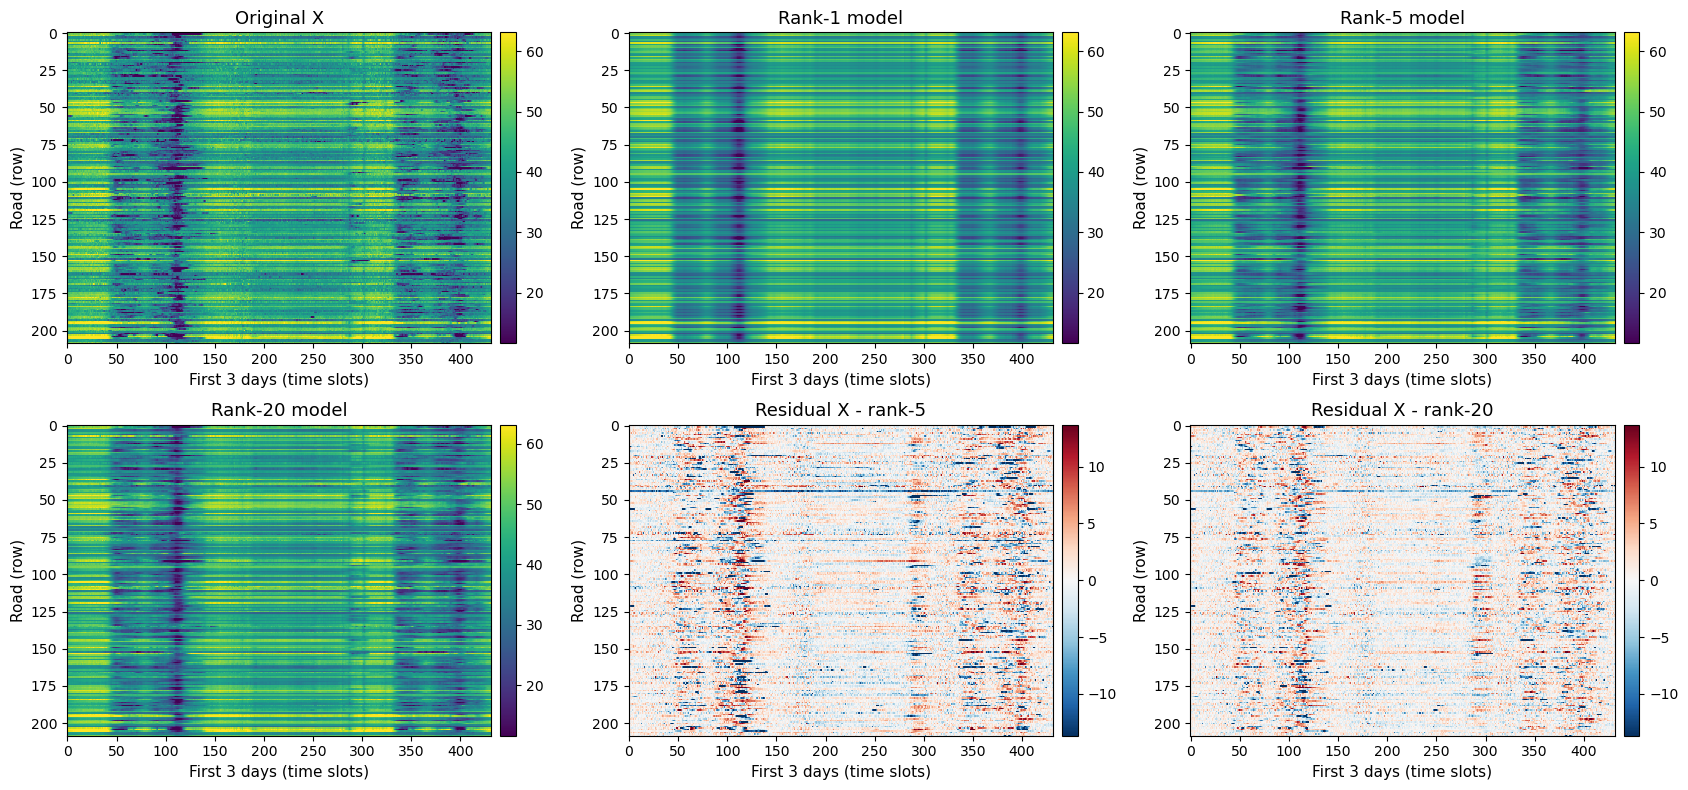

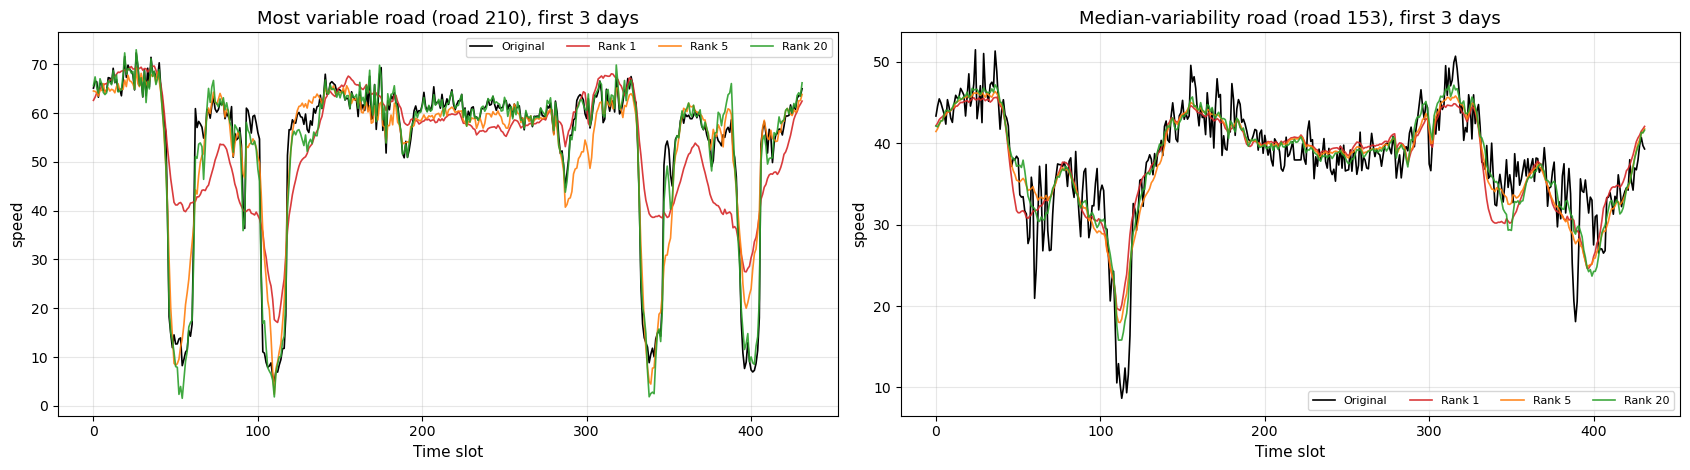

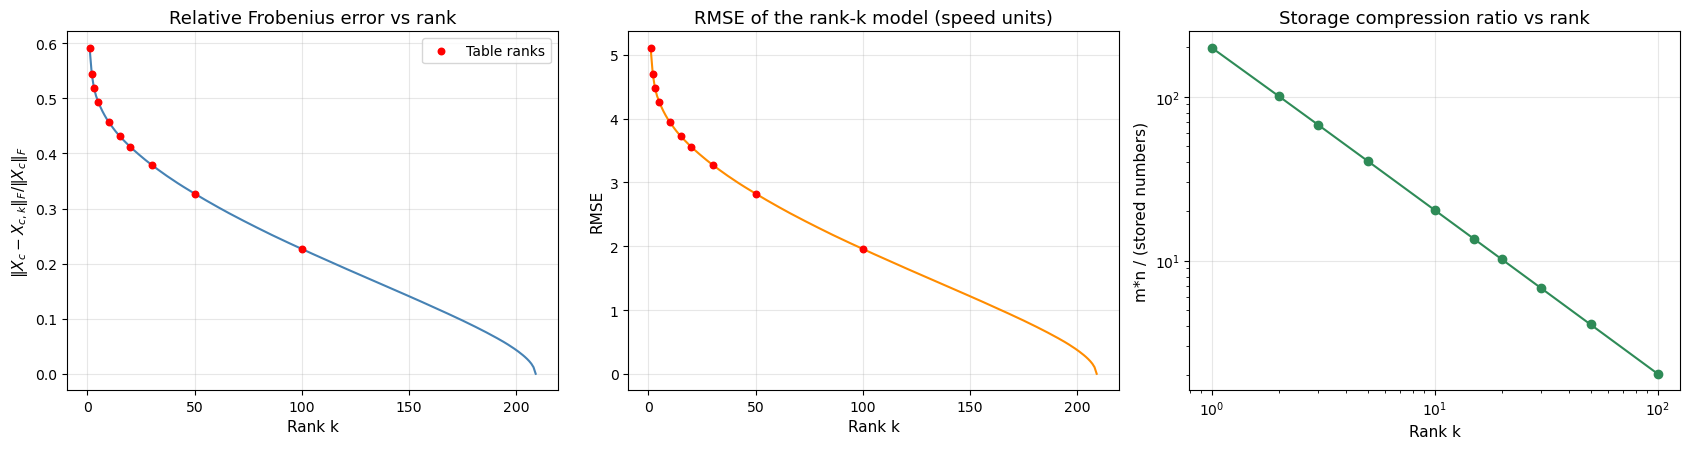


Section 8 complete. Variables available for later sections:
  lowrank_reconstruct(k), lowrank_table, X_lr, K_LIST, rel_err_curve, rmse_curve, fro_Xc


In [12]:
# ============================================================
# SECTION 8: LOW-RANK APPROXIMATION
# Requires: Sections 1-7
#   (X, Xc, row_means, Uc, Sc, Vtc, cum_Xc, fro_X, m, n,
#    n_times_clean, row_labels, RANDOM_STATE)
# Output: lowrank_reconstruct(k), lowrank_table, X_lr, K_LIST,
#         rel_err_curve, rmse_curve
# ============================================================

for _name in ["X", "Xc", "row_means", "Uc", "Sc", "Vtc", "cum_Xc", "fro_X",
              "m", "n", "n_times_clean", "row_labels"]:
    if _name not in globals():
        raise NameError(f"'{_name}' is missing. Please run Sections 1-7 first.")

# ------------------------------------------------------------
# 1. The truncated-SVD model
#    Xc_k = sum_{i<=k} sigma_i u_i v_i^T      (best rank-k approximation of Xc)
#    X_hat_k = row_means + Xc_k               (mean level + rank-k pattern)
# ------------------------------------------------------------
r = len(Sc)

def lowrank_reconstruct(k, add_mean=True):
    """Rank-k approximation of the traffic matrix.
    add_mean=True  -> row_means + rank-k approximation of Xc  (approximates X)
    add_mean=False -> rank-k approximation of Xc itself"""
    k = int(k)
    if not 1 <= k <= r:
        raise ValueError(f"k must be between 1 and {r}.")
    Xk = (Uc[:, :k] * Sc[:k]) @ Vtc[:k]            # U_k diag(S_k) V_k^T
    return Xk + row_means if add_mean else Xk

K_LIST = [k for k in [1, 2, 3, 5, 10, 15, 20, 30, 50, 100] if k <= r]
PLOT_KS = [k for k in [1, 5, 20] if k <= r]       # ranks kept in memory for plotting
X_lr = {k: lowrank_reconstruct(k) for k in PLOT_KS}

# ------------------------------------------------------------
# 2. Error of the rank-k approximation for several k
#    Eckart-Young-Mirsky theorem (checked numerically below):
#      ||Xc - Xc_k||_F = sqrt(sum_{i>k} sigma_i^2)
#      ||Xc - Xc_k||_2 = sigma_{k+1}
#      and no other rank-k matrix has a smaller error in either norm.
# ------------------------------------------------------------
fro_Xc = np.linalg.norm(Xc, "fro")
rng = np.random.default_rng(RANDOM_STATE)

rows = []
for k in K_LIST:
    Rk = Xc - lowrank_reconstruct(k, add_mean=False)          # residual matrix
    err_F = np.linalg.norm(Rk, "fro")

    # (a) Eckart-Young for the Frobenius norm: matches the tail of the spectrum
    tail_F = np.sqrt(np.sum(Sc[k:] ** 2))
    assert np.isclose(err_F, tail_F, rtol=1e-8), f"Eckart-Young (Frobenius) failed at k={k}"

    # (b) Compare with a RANDOM rank-k subspace projection (should be worse)
    Q, _ = np.linalg.qr(rng.standard_normal((m, k)))
    err_rand = np.linalg.norm(Xc - Q @ (Q.T @ Xc), "fro")

    params_lr = k * (m + n + 1) + m                           # U_k, S_k, V_k and the means
    rows.append({
        "k": k,
        "energy retained": cum_Xc[k - 1],
        "rel. error vs Xc": err_F / fro_Xc,
        "rel. error vs X": err_F / fro_X,
        "RMSE": err_F / np.sqrt(m * n),
        "MAE": np.mean(np.abs(Rk)),
        "random-subspace error / SVD error": err_rand / err_F,
        "compression ratio": (m * n) / params_lr,
    })

lowrank_table = pd.DataFrame(rows).set_index("k")
print("--- Rank-k approximation quality ---")
print("(Eckart-Young check against sqrt(sum of discarded sigma^2): passed for every k)\n")
display(lowrank_table)

# Spectral-norm version of the theorem for a few ranks
print("Spectral-norm check:  ||Xc - Xc_k||_2  vs  sigma_(k+1)")
for k in [kk for kk in [1, 5, 20] if kk < r]:
    spec = np.linalg.norm(Xc - lowrank_reconstruct(k, add_mean=False), 2)
    print(f"  k={k:>3}: {spec:12.4f}  vs  {Sc[k]:12.4f}   (match: {np.isclose(spec, Sc[k])})")

# ------------------------------------------------------------
# 3. Error curve for EVERY rank, computed directly from the spectrum
#    relative error(k) = sqrt(1 - cumulative energy(k))
# ------------------------------------------------------------
k_all = np.arange(1, r + 1)
rel_err_curve = np.sqrt(np.clip(1.0 - cum_Xc, 0.0, None))
rmse_curve = fro_Xc * rel_err_curve / np.sqrt(m * n)

# ------------------------------------------------------------
# 4. Visualizations
# ------------------------------------------------------------
zoom_days = min(3, n // n_times_clean)
zn = zoom_days * n_times_clean
vmin, vmax = np.percentile(X, [1, 99])

# --- Figure 1: heatmaps of original, rank-k models and residuals ------
k_a, k_b = PLOT_KS[1], PLOT_KS[-1]                     # e.g. 5 and 20
res_a = (X - X_lr[k_a])[:, :zn]
res_b = (X - X_lr[k_b])[:, :zn]
lim = np.percentile(np.abs(np.concatenate([res_a.ravel(), res_b.ravel()])), 99)

panels = [
    (X[:, :zn],               "Original X",              "viridis", (vmin, vmax)),
    (X_lr[PLOT_KS[0]][:, :zn], f"Rank-{PLOT_KS[0]} model", "viridis", (vmin, vmax)),
    (X_lr[k_a][:, :zn],       f"Rank-{k_a} model",       "viridis", (vmin, vmax)),
    (X_lr[k_b][:, :zn],       f"Rank-{k_b} model",       "viridis", (vmin, vmax)),
    (res_a,                   f"Residual X - rank-{k_a}", "RdBu_r",  (-lim, lim)),
    (res_b,                   f"Residual X - rank-{k_b}", "RdBu_r",  (-lim, lim)),
]
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, (M, title, cmap, (lo, hi)) in zip(axes.ravel(), panels):
    im = ax.imshow(M, aspect="auto", cmap=cmap, vmin=lo, vmax=hi, interpolation="nearest")
    ax.set_title(title)
    ax.set_xlabel(f"First {zoom_days} days (time slots)")
    ax.set_ylabel("Road (row)")
    ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "08_lowrank_heatmaps.png"), dpi=150)
plt.show()

# --- Figure 2: individual road series, original vs rank-k -------------
row_std = X.std(axis=1)
example_rows = [int(np.argmax(row_std)), int(np.argsort(row_std)[len(row_std) // 2])]
titles = ["Most variable road", "Median-variability road"]

fig, axes = plt.subplots(1, 2, figsize=(17, 4.8))
for ax, rr, ttl in zip(axes, example_rows, titles):
    ax.plot(X[rr, :zn], color="black", lw=1.2, label="Original")
    for k, c in zip(PLOT_KS, ["tab:red", "tab:orange", "tab:green"]):
        ax.plot(X_lr[k][rr, :zn], color=c, lw=1.2, alpha=0.9, label=f"Rank {k}")
    ax.set_title(f"{ttl} (road {row_labels[rr]}), first {zoom_days} days")
    ax.set_xlabel("Time slot")
    ax.set_ylabel(VALUE_COL)
    ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "08_lowrank_road_series.png"), dpi=150)
plt.show()

# --- Figure 3: how the error falls with the rank ----------------------
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

axes[0].plot(k_all, rel_err_curve, color="steelblue")
axes[0].scatter(K_LIST, lowrank_table["rel. error vs Xc"], color="red", zorder=3, s=22, label="Table ranks")
axes[0].set_title("Relative Frobenius error vs rank")
axes[0].set_xlabel("Rank k")
axes[0].set_ylabel(r"$\|X_c - X_{c,k}\|_F / \|X_c\|_F$")
axes[0].legend()

axes[1].plot(k_all, rmse_curve, color="darkorange")
axes[1].scatter(K_LIST, lowrank_table["RMSE"], color="red", zorder=3, s=22)
axes[1].set_title("RMSE of the rank-k model (speed units)")
axes[1].set_xlabel("Rank k")
axes[1].set_ylabel("RMSE")

axes[2].loglog(K_LIST, lowrank_table["compression ratio"], "o-", color="seagreen")
axes[2].set_title("Storage compression ratio vs rank")
axes[2].set_xlabel("Rank k")
axes[2].set_ylabel("m*n / (stored numbers)")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "08_lowrank_error_curves.png"), dpi=150)
plt.show()

print("\nSection 8 complete. Variables available for later sections:")
print("  lowrank_reconstruct(k), lowrank_table, X_lr, K_LIST, rel_err_curve, rmse_curve, fro_Xc")

(a) Elbow of the cumulative-energy curve : k = 43  (a geometric hint, it ignores generalisation)

(b) Held-out validation: 46 training days, 15 test days, 10 road folds


,held-out RMSE,improvement vs k=0
k,,
0,8.3425,0.0000
1,4.9705,0.4042
2,4.6136,0.4470
3,4.4757,0.4635
5,4.3495,0.4786
8,4.2604,0.4893
10,4.2443,0.4912
15,4.2557,0.4899
20,4.2991,0.4847


Best held-out RMSE at k = 10; smallest k within 1% of it: k = 8

>>> K_SELECTED = 8  (used in the rest of this section; Section 10 will re-test it)

--- Overall reconstruction error at K_SELECTED ---
||X - X_hat||_F            : 5,490.03
Relative to ||X||_F        : 0.0999
Relative to ||Xc||_F       : 0.4691
RMSE (observed cells)      : 4.0499
MAE  (observed cells)      : 2.7063
Largest |residual|         : 65.26

--- Residual distribution ---


,value
(Gaussian reference beyond 3 sigma),0.0027
excess kurtosis,7.6075
mean,-0.0004
robust sigma (MAD),2.6257
share beyond 3 robust sigma,0.0596
share beyond 4 robust sigma,0.0293
skewness,-1.2156
std,4.0499



--- Error by road ---
Road RMSE: min 1.77 | median 3.79 | max 6.56
Road R^2 : min 0.189 | median 0.759 | max 0.955
Five roads with the highest RMSE:


,mean speed,speed std,RMSE,R^2 (variance explained)
road,,,,
139,41.0387,9.6316,6.5583,0.5364
80,49.3417,13.0956,6.4996,0.7537
8,53.9847,8.8446,6.4294,0.4716
76,29.6475,8.5404,5.9812,0.5095
111,49.2536,11.6222,5.9800,0.7353


Five roads with the lowest R^2:


,mean speed,speed std,RMSE,R^2 (variance explained)
road,,,,
87,39.5667,4.6436,4.1806,0.1895
131,37.7512,4.4848,3.6422,0.3405
149,40.5766,3.3295,2.6686,0.3576
22,35.5940,6.7951,5.4381,0.3595
34,36.3906,4.5355,3.6398,0.3760



--- Error by time slot and by day ---
Slot RMSE: min 2.21 (slot 17) | max 5.91 (slot 112)
Day  RMSE: min 2.65 (day 2) | max 5.13 (day 45)
Correlation(slot RMSE, network mean speed) : -0.975

Residual RMSE by fitted-speed octile:


,count,RMSE
"(-15.878, 27.607]",229429,5.7361
"(27.607, 32.143]",229429,4.9642
"(32.143, 35.779]",229428,4.4235
"(35.779, 39.001]",229429,3.8580
"(39.001, 42.132]",229428,3.5713
"(42.132, 45.894]",229429,3.3083
"(45.894, 51.103]",229428,2.9836
"(51.103, 75.83]",229429,2.5723


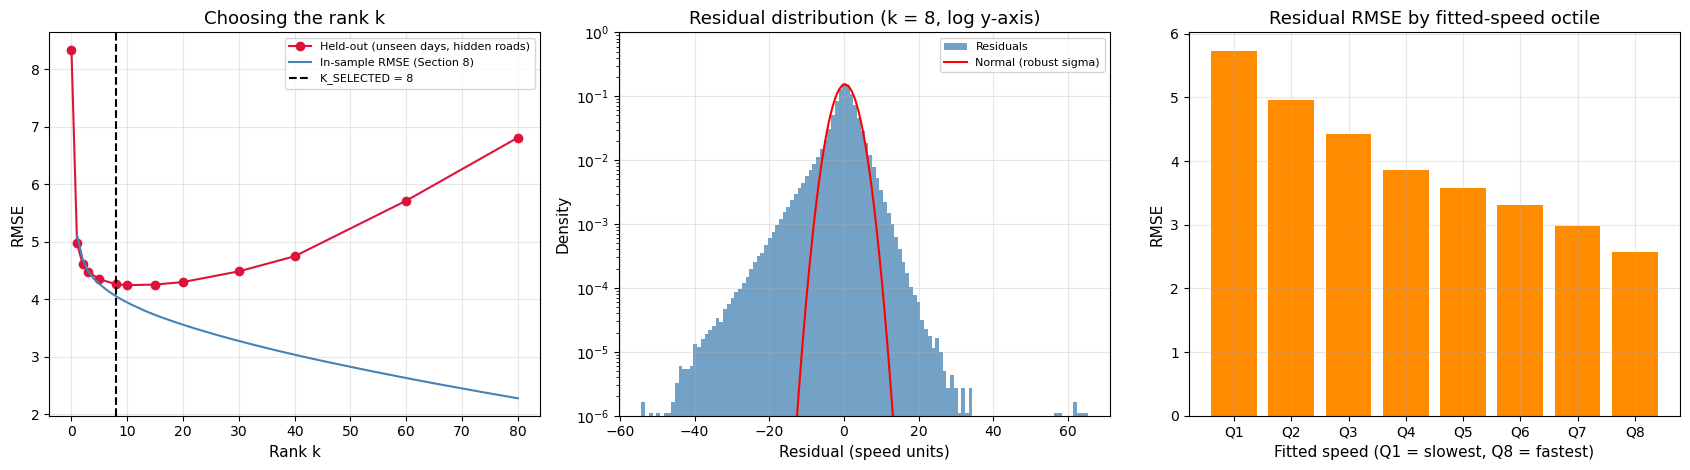

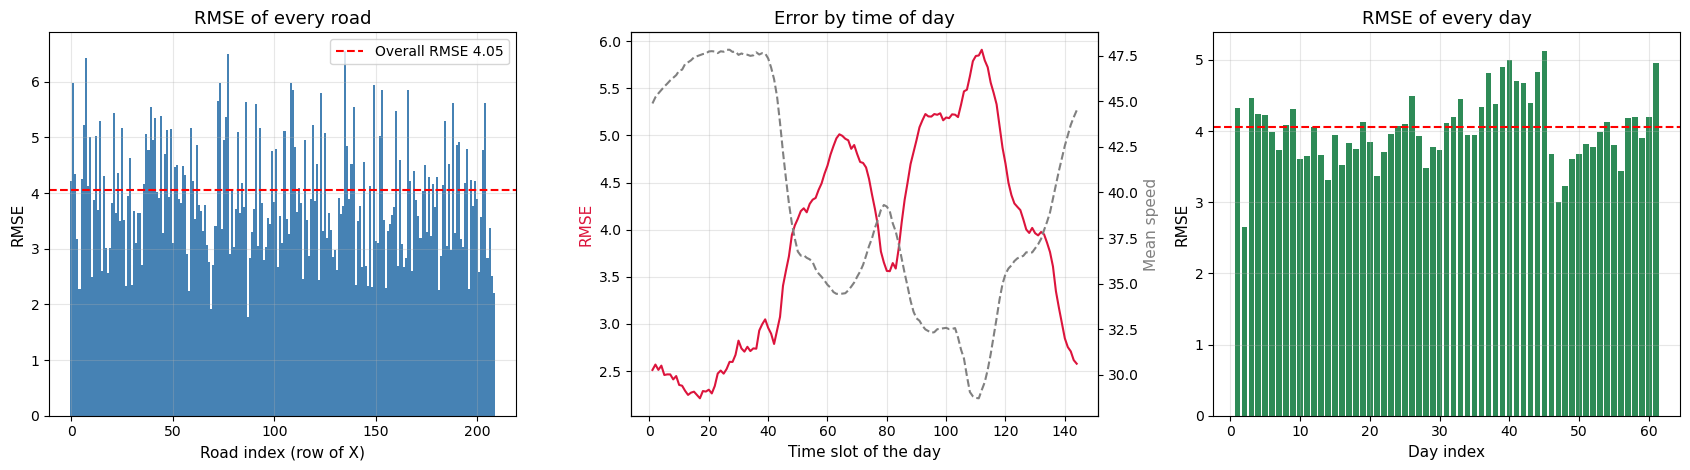

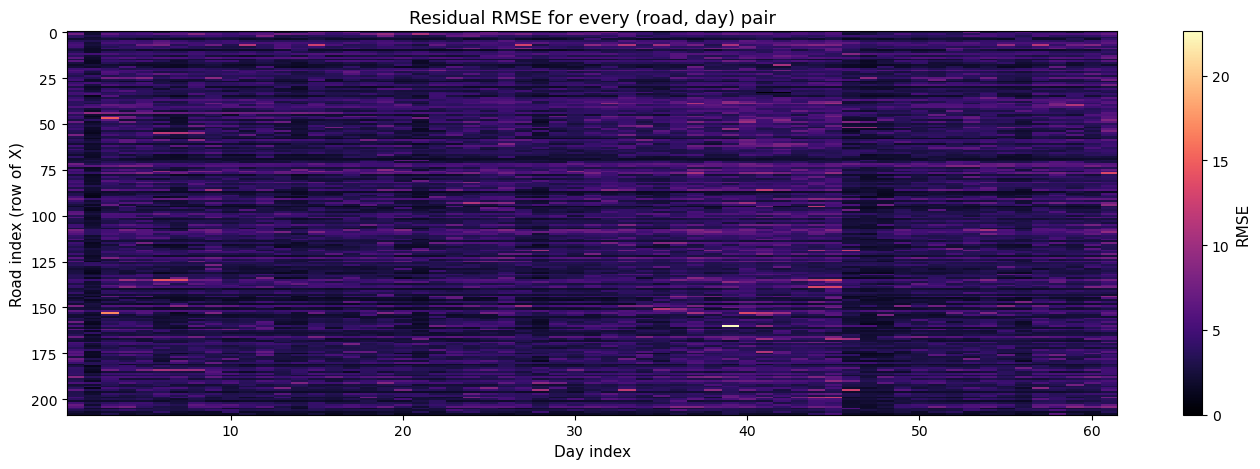


Section 9 complete. Variables available for later sections:
  K_SELECTED, X_hat, R, resid_sigma, obs_mask, cv_table, road_table, slot_rmse, day_rmse, road_day_rmse


In [13]:
# ============================================================
# SECTION 9: RECONSTRUCTION ERROR ANALYSIS
# Requires: Sections 1-8
#   (X, X_imputed_mask, row_means, Uc, Sc, cum_Xc, rmse_curve, fro_X,
#    m, n, n_times_clean, row_labels, time_ids, K_LIST,
#    lowrank_reconstruct, RANDOM_STATE)
# Output: K_SELECTED, X_hat, R, resid_sigma, cv_table, road_table,
#         slot_rmse, day_rmse
# ============================================================

for _name in ["X", "X_imputed_mask", "row_means", "Uc", "Sc", "cum_Xc", "rmse_curve",
              "fro_X", "m", "n", "n_times_clean", "row_labels", "time_ids",
              "K_LIST", "lowrank_reconstruct"]:
    if _name not in globals():
        raise NameError(f"'{_name}' is missing. Please run Sections 1-8 first.")

obs_mask = ~X_imputed_mask                 # evaluate only on genuinely observed cells
n_days_all = n // n_times_clean

# ------------------------------------------------------------
# 1. Choosing the rank k
#    (a) elbow of the cumulative-energy curve (point farthest from the chord)
#    (b) held-out validation: predict HIDDEN ROADS on UNSEEN DAYS from the rest
# ------------------------------------------------------------
# (a) Elbow: normalised distance from the straight line joining first and last point
kk = np.arange(1, len(cum_Xc) + 1)
x_norm = (kk - kk[0]) / (kk[-1] - kk[0])
y_norm = (cum_Xc - cum_Xc[0]) / (cum_Xc[-1] - cum_Xc[0])
k_elbow = int(kk[np.argmax(y_norm - x_norm)])
print(f"(a) Elbow of the cumulative-energy curve : k = {k_elbow}  "
      "(a geometric hint, it ignores generalisation)")

# (b) Held-out validation
#     * fit the SVD basis on the first 75% of the days only (training days)
#     * on the remaining days, hide a block of roads, estimate each time slot's
#       coefficients by least squares from the VISIBLE roads, predict the hidden ones
#     * repeat over 10 road folds; compare with predicting each road's training mean (k = 0)
rng = np.random.default_rng(RANDOM_STATE)
split = int(round(0.75 * n_days_all)) * n_times_clean
X_tr, X_te = X[:, :split], X[:, split:]
mask_te = obs_mask[:, split:]
mu_tr = X_tr.mean(axis=1, keepdims=True)
U_tr, S_tr, _ = sla.svd(X_tr - mu_tr, full_matrices=False)
Xte_c = X_te - mu_tr

N_FOLDS = 10
folds = np.array_split(rng.permutation(m), N_FOLDS)
max_visible = m - max(len(f) for f in folds)
cv_ks = [k for k in [1, 2, 3, 5, 8, 10, 15, 20, 30, 40, 60, 80] if k < max_visible]

def cv_rmse(k):
    sse, cnt = 0.0, 0
    for hid in folds:
        vis = np.setdiff1d(np.arange(m), hid)
        if k == 0:
            pred = np.zeros((len(hid), Xte_c.shape[1]))             # predict the training mean
        else:
            Uk = U_tr[:, :k]
            coef, *_ = np.linalg.lstsq(Uk[vis], Xte_c[vis], rcond=None)
            pred = Uk[hid] @ coef
        err2 = (Xte_c[hid] - pred) ** 2
        w = mask_te[hid]
        sse += float(err2[w].sum())
        cnt += int(w.sum())
    return np.sqrt(sse / cnt)

cv_table = pd.DataFrame({"k": [0] + cv_ks,
                         "held-out RMSE": [cv_rmse(k) for k in [0] + cv_ks]}).set_index("k")

best_k = int(cv_table["held-out RMSE"].iloc[1:].idxmin())
CV_TOL = 0.01                                           # accept the smallest k within 1% of the best
K_SELECTED = int(min(k for k in cv_ks
                     if cv_table.loc[k, "held-out RMSE"] <= (1 + CV_TOL) * cv_table.loc[best_k, "held-out RMSE"]))
cv_table["improvement vs k=0"] = 1 - cv_table["held-out RMSE"] / cv_table.loc[0, "held-out RMSE"]

print(f"\n(b) Held-out validation: {int(round(0.75 * n_days_all))} training days, "
      f"{n_days_all - int(round(0.75 * n_days_all))} test days, {N_FOLDS} road folds")
display(cv_table)
print(f"Best held-out RMSE at k = {best_k}; smallest k within {CV_TOL:.0%} of it: k = {K_SELECTED}")
print(f"\n>>> K_SELECTED = {K_SELECTED}  (used in the rest of this section; Section 10 will re-test it)")

# ------------------------------------------------------------
# 2. Reconstruction and residual matrix at K_SELECTED
# ------------------------------------------------------------
X_hat = lowrank_reconstruct(K_SELECTED)          # row_means + rank-k pattern
R = X - X_hat                                    # residual matrix (the anomaly signal)

def masked_rmse(res, mask, axis=None):
    num = np.sum((res ** 2) * mask, axis=axis)
    den = np.maximum(np.sum(mask, axis=axis), 1)
    return np.sqrt(num / den)

overall_rmse = float(masked_rmse(R, obs_mask))
overall_mae = float(np.abs(R)[obs_mask].mean())
fro_R = float(np.linalg.norm(R, "fro"))
print("\n--- Overall reconstruction error at K_SELECTED ---")
print(f"||X - X_hat||_F            : {fro_R:,.2f}")
print(f"Relative to ||X||_F        : {fro_R / fro_X:.4f}")
print(f"Relative to ||Xc||_F       : {fro_R / np.linalg.norm(X - row_means, 'fro'):.4f}")
print(f"RMSE (observed cells)      : {overall_rmse:.4f}")
print(f"MAE  (observed cells)      : {overall_mae:.4f}")
print(f"Largest |residual|         : {np.abs(R).max():.2f}")

# ------------------------------------------------------------
# 3. Distribution of the residuals (heavy tails?)
# ------------------------------------------------------------
res_obs = R[obs_mask]
med = np.median(res_obs)
resid_sigma = 1.4826 * np.median(np.abs(res_obs - med))     # robust scale (MAD)
z = (res_obs - med) / resid_sigma
dist_table = pd.DataFrame({
    "value": {
        "mean": res_obs.mean(),
        "std": res_obs.std(),
        "robust sigma (MAD)": resid_sigma,
        "skewness": stats.skew(res_obs),
        "excess kurtosis": stats.kurtosis(res_obs),
        "share beyond 3 robust sigma": np.mean(np.abs(z) > 3),
        "share beyond 4 robust sigma": np.mean(np.abs(z) > 4),
        "(Gaussian reference beyond 3 sigma)": 0.0027,
    }
})
print("\n--- Residual distribution ---")
display(dist_table)

# ------------------------------------------------------------
# 4. Where is the error? by road, by time slot, by day, by speed level
# ------------------------------------------------------------
R3 = R.reshape(m, n_days_all, n_times_clean)
M3 = obs_mask.reshape(m, n_days_all, n_times_clean)

road_rmse = masked_rmse(R, obs_mask, axis=1)
road_sst = np.sum((X - X.mean(axis=1, keepdims=True)) ** 2 * obs_mask, axis=1)
road_sse = np.sum((R ** 2) * obs_mask, axis=1)
road_table = pd.DataFrame({
    "road": row_labels,
    "mean speed": X.mean(axis=1),
    "speed std": X.std(axis=1),
    "RMSE": road_rmse,
    "R^2 (variance explained)": 1 - road_sse / road_sst,
}).set_index("road")

slot_rmse = pd.Series(masked_rmse(R3, M3, axis=(0, 1)), index=time_ids, name="RMSE")
day_rmse = pd.Series(masked_rmse(R3, M3, axis=(0, 2)), index=np.arange(1, n_days_all + 1), name="RMSE")
road_day_rmse = masked_rmse(R3, M3, axis=2)                  # m x days

print("\n--- Error by road ---")
print(f"Road RMSE: min {road_rmse.min():.2f} | median {np.median(road_rmse):.2f} | max {road_rmse.max():.2f}")
print(f"Road R^2 : min {road_table['R^2 (variance explained)'].min():.3f} | "
      f"median {road_table['R^2 (variance explained)'].median():.3f} | "
      f"max {road_table['R^2 (variance explained)'].max():.3f}")
print("Five roads with the highest RMSE:")
display(road_table.sort_values("RMSE", ascending=False).head(5))
print("Five roads with the lowest R^2:")
display(road_table.sort_values("R^2 (variance explained)").head(5))

print("\n--- Error by time slot and by day ---")
print(f"Slot RMSE: min {slot_rmse.min():.2f} (slot {slot_rmse.idxmin()}) | "
      f"max {slot_rmse.max():.2f} (slot {slot_rmse.idxmax()})")
print(f"Day  RMSE: min {day_rmse.min():.2f} (day {day_rmse.idxmin()}) | "
      f"max {day_rmse.max():.2f} (day {day_rmse.idxmax()})")
net_profile = X.reshape(m, n_days_all, n_times_clean).mean(axis=(0, 1))
print(f"Correlation(slot RMSE, network mean speed) : {np.corrcoef(slot_rmse.values, net_profile)[0, 1]:.3f}")

# Error vs fitted speed level (is the noise level constant?)
bins = pd.qcut(X_hat[obs_mask], q=8, duplicates="drop")
speed_level = (pd.DataFrame({"fitted": X_hat[obs_mask], "res": R[obs_mask]})
               .groupby(bins, observed=True)["res"]
               .agg(count="size", RMSE=lambda s: np.sqrt(np.mean(s ** 2))))
print("\nResidual RMSE by fitted-speed octile:")
display(speed_level)

# ------------------------------------------------------------
# 5. Visualizations
# ------------------------------------------------------------
# --- Figure 1: choosing k and residual distribution --------------------
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

axes[0].plot(cv_table.index, cv_table["held-out RMSE"], "o-", color="crimson", label="Held-out (unseen days, hidden roads)")
axes[0].plot(np.arange(1, len(rmse_curve) + 1)[:max(cv_ks)], rmse_curve[:max(cv_ks)], "-", color="steelblue",
             label="In-sample RMSE (Section 8)")
axes[0].axvline(K_SELECTED, color="black", ls="--", label=f"K_SELECTED = {K_SELECTED}")
axes[0].set_title("Choosing the rank k")
axes[0].set_xlabel("Rank k")
axes[0].set_ylabel("RMSE")
axes[0].legend(fontsize=8)

axes[1].hist(res_obs, bins=120, density=True, color="steelblue", alpha=0.75, label="Residuals")
xs = np.linspace(res_obs.min(), res_obs.max(), 400)
axes[1].plot(xs, stats.norm.pdf(xs, med, resid_sigma), "r-", lw=1.5, label="Normal (robust sigma)")
axes[1].set_yscale("log")
axes[1].set_ylim(1e-6, 1.0)
axes[1].set_title(f"Residual distribution (k = {K_SELECTED}, log y-axis)")
axes[1].set_xlabel("Residual (speed units)")
axes[1].set_ylabel("Density")
axes[1].legend(fontsize=8)

axes[2].bar(np.arange(len(speed_level)), speed_level["RMSE"], color="darkorange")
axes[2].set_xticks(np.arange(len(speed_level)))
axes[2].set_xticklabels([f"Q{i + 1}" for i in range(len(speed_level))])
axes[2].set_title("Residual RMSE by fitted-speed octile")
axes[2].set_xlabel("Fitted speed (Q1 = slowest, Q8 = fastest)")
axes[2].set_ylabel("RMSE")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "09_choose_k_and_residuals.png"), dpi=150)
plt.show()

# --- Figure 2: where the error is --------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

axes[0].bar(np.arange(m), road_rmse, color="steelblue", width=1.0)
axes[0].axhline(overall_rmse, color="red", ls="--", label=f"Overall RMSE {overall_rmse:.2f}")
axes[0].set_title("RMSE of every road")
axes[0].set_xlabel("Road index (row of X)")
axes[0].set_ylabel("RMSE")
axes[0].legend()

axes[1].plot(slot_rmse.index, slot_rmse.values, color="crimson", label="Residual RMSE")
axes[1].set_xlabel("Time slot of the day")
axes[1].set_ylabel("RMSE", color="crimson")
ax2 = axes[1].twinx()
ax2.plot(time_ids, net_profile, color="gray", ls="--", label="Network mean speed")
ax2.set_ylabel("Mean speed", color="gray")
ax2.grid(False)
axes[1].set_title("Error by time of day")

axes[2].bar(day_rmse.index, day_rmse.values, color="seagreen")
axes[2].axhline(overall_rmse, color="red", ls="--")
axes[2].set_title("RMSE of every day")
axes[2].set_xlabel("Day index")
axes[2].set_ylabel("RMSE")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "09_error_by_road_time_day.png"), dpi=150)
plt.show()

# --- Figure 3: error map over roads x days ------------------------------
fig, ax = plt.subplots(figsize=(14, 4.8))
im = ax.imshow(road_day_rmse, aspect="auto", cmap="magma", interpolation="nearest",
               extent=[0.5, n_days_all + 0.5, m - 0.5, -0.5])
ax.set_title("Residual RMSE for every (road, day) pair")
ax.set_xlabel("Day index")
ax.set_ylabel("Road index (row of X)")
ax.grid(False)
plt.colorbar(im, ax=ax, label="RMSE")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "09_error_map_road_day.png"), dpi=150)
plt.show()

print("\nSection 9 complete. Variables available for later sections:")
print("  K_SELECTED, X_hat, R, resid_sigma, obs_mask, cv_table, road_table, "
      "slot_rmse, day_rmse, road_day_rmse")

--- Injected anomalies ---
Severity           : moderate
Target rate        : 2.00% of cells
Actual rate        : 2.005%  (36,807 cells of 1,835,856)


,events,cells,mean_length,mean_roads,share of anomalous cells
type,,,,,
point,7344,7344,1.0000,1.0000,0.1995
incident,1473,14697,11.9776,1.0000,0.3993
regional,156,14766,12.0449,9.5833,0.4012



Cells actually changed             : 42,743 (labelled: 36,807; the rest are the soft ramp edges)
||E||_F / ||X||_F                  : 0.0780
|change| on labelled cells         : median 20.28 | 10th pct 11.78 | 90th pct 30.46
Robust residual sigma (Section 9)  : 2.63  (for comparison with the changes above)

--- Effect on the singular values (centred matrix) ---
||E_c||_2                         : 673.55
max_i |sigma_i(anomalous) - sigma_i(clean)| : 114.56
Weyl's inequality holds           : True


,clean sigma,anomalous sigma,relative change
1,"9,431.9029","9,383.2602",-0.0052
2,"2,719.9962","2,716.7295",-0.0012
3,"1,918.3962","1,930.3436",0.0062
4,"1,440.0152","1,462.7642",0.0158
5,"1,197.8478","1,237.4684",0.0331
6,"1,113.3349","1,149.2166",0.0322
7,"1,038.4172","1,077.0928",0.0372
8,969.3270,"1,027.1337",0.0596



--- Sanity check: rank-8 residual detector on the contaminated matrix ---


,cells,ROC-AUC |residual|,ROC-AUC slot-normalised
all anomalies,36807,0.9832,0.9811
point,7344,0.9876,0.9839
incident,14697,0.9818,0.9794
regional,14766,0.9826,0.9813



--- Severity sweep (rank-8 residual detector, refitted on each contaminated matrix) ---


,anomalous share,median |change|,10th pct |change|,ROC-AUC |residual|
severity,,,,
mild,0.0200,10.9316,6.2623,0.9248
moderate,0.0200,20.2772,11.7828,0.9832
severe,0.0200,28.0758,16.5382,0.9942


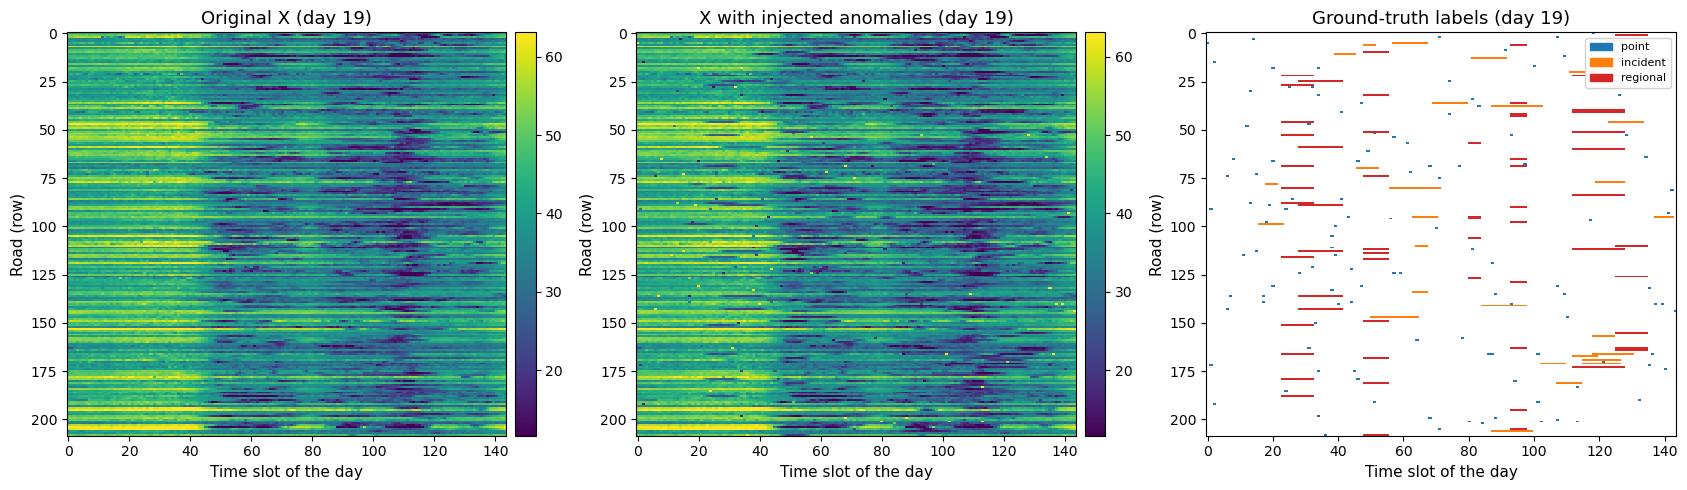

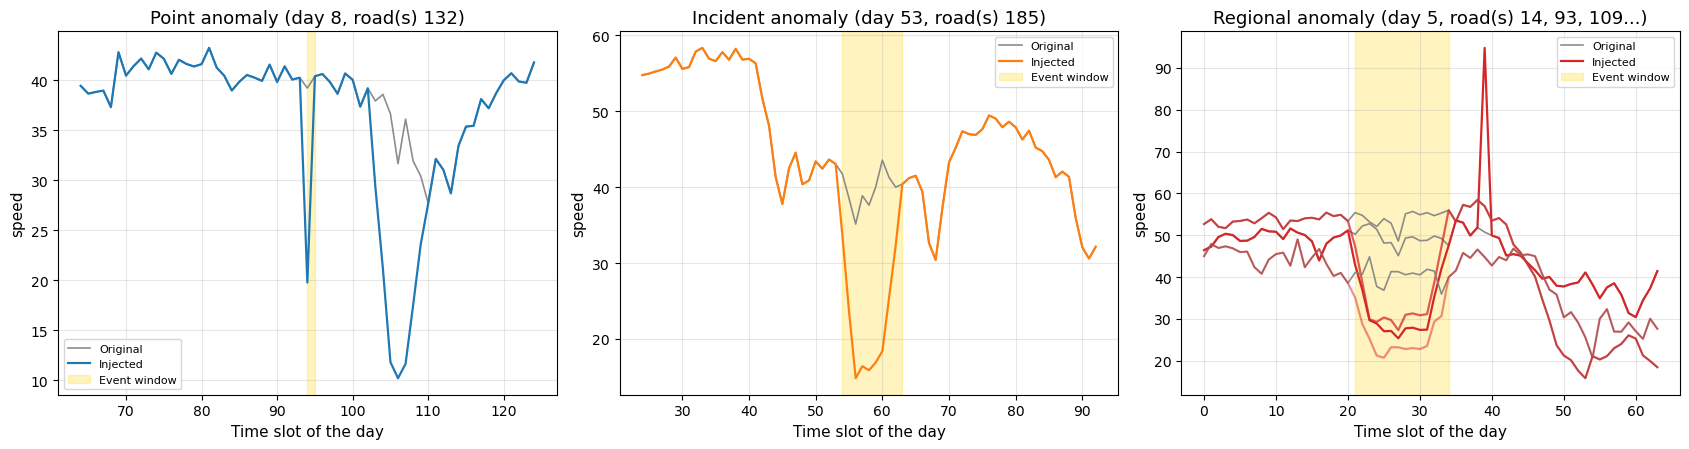

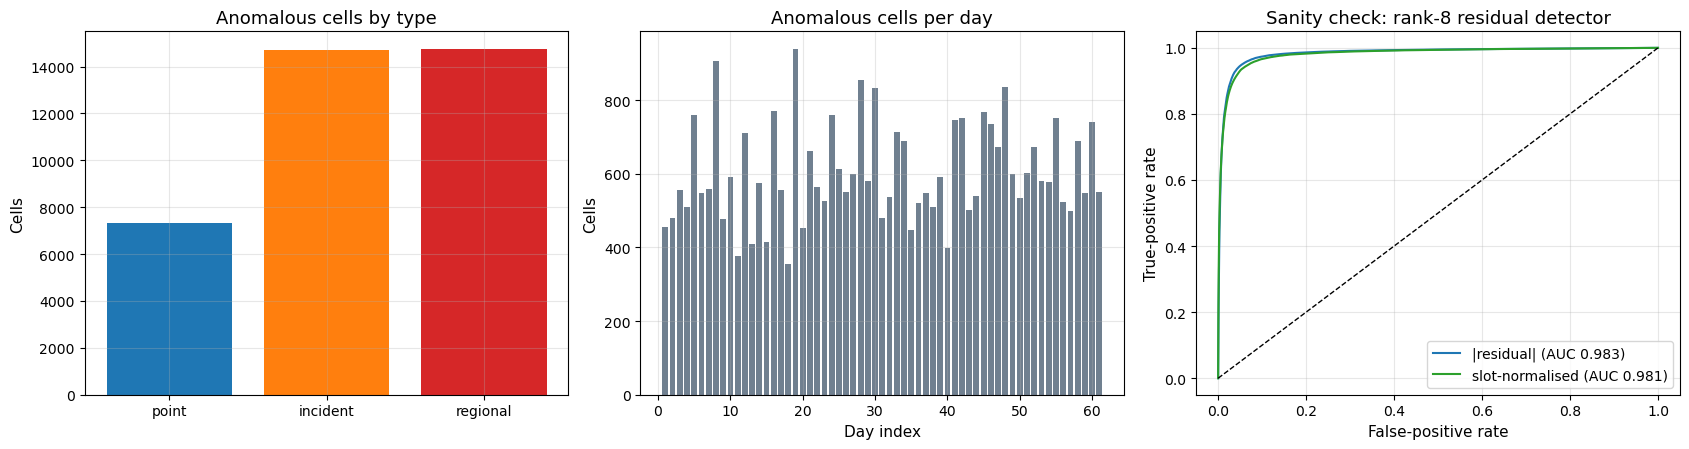


Section 10 complete. Variables available for later sections:
  X_anom, Y_true, anomaly_type, events_df, eval_mask, inject_anomalies(), SEVERITY, TYPE_NAMES,
  ANOMALY_RATE, Uc_anom, Sc_anom, Vtc_anom, row_means_anom, score_raw, score_norm, auc_table, severity_sweep


In [14]:
# ============================================================
# SECTION 10: ARTIFICIAL ANOMALY INJECTION
# Requires: Sections 1-9
#   (X, X_imputed_mask, obs_mask, K_SELECTED, Sc, m, n, n_times_clean,
#    row_labels, time_ids, RANDOM_STATE)
# Output: X_anom, Y_true, anomaly_type, events_df, inject_anomalies(),
#         Uc_anom, Sc_anom, Vtc_anom, row_means_anom
# ============================================================

for _name in ["X", "X_imputed_mask", "obs_mask", "K_SELECTED", "Sc", "m", "n",
              "n_times_clean", "row_labels", "time_ids"]:
    if _name not in globals():
        raise NameError(f"'{_name}' is missing. Please run Sections 1-9 first.")

from sklearn.metrics import roc_auc_score, roc_curve   # (already imported in Section 1)

T = n_times_clean                 # time slots per day
D = n // T                        # number of days

# ------------------------------------------------------------
# 1. Anomaly design (all knobs in one place)
# ------------------------------------------------------------
ANOMALY_RATE = 0.02               # target share of ALL cells that will be anomalous
TYPE_SHARE = {1: 0.20,            # 1 = point anomaly (isolated spike or drop)
              2: 0.40,            # 2 = incident (one road, sustained slowdown)
              3: 0.40}            # 3 = regional (5-15 roads slow down together)
TYPE_NAMES = {1: "point", 2: "incident", 3: "regional"}
SEGMENT_LEN = (6, 18)             # event length in time slots (about 1-3 hours of 10-min slots)
REGION_ROADS = (5, 15)            # number of roads in a regional event
RAMP = 2                          # slots used for the smooth start/end of a segment
SEVERITY = {                      # multiplicative factors applied to the true speed
    "mild":     {"drop": (0.60, 0.80), "spike": (1.25, 1.50)},
    "moderate": {"drop": (0.30, 0.60), "spike": (1.50, 2.00)},
    "severe":   {"drop": (0.10, 0.40), "spike": (2.00, 3.00)},
}
DEFAULT_SEVERITY = "moderate"
MIN_SPEED, MAX_SPEED = float(X.min()), float(X.max())    # keep injected speeds plausible

def _segment_weights(L, ramp=RAMP):
    """Trapezoid profile in [0, 1]: smooth onset and recovery of an event."""
    up = np.arange(1, L + 1) / (ramp + 1)
    down = np.arange(L, 0, -1) / (ramp + 1)
    return np.minimum.reduce([up, down, np.ones(L)])

# ------------------------------------------------------------
# 2. The injection function (reused later for other severities)
# ------------------------------------------------------------
def inject_anomalies(X_base, rate=ANOMALY_RATE, severity=DEFAULT_SEVERITY,
                     seed=RANDOM_STATE, forbidden=None, max_tries=200_000):
    """Return (X_anom, labels, atype, events_df).
    labels : bool matrix, True on anomalous cells (ground truth)
    atype  : int8 matrix, 0 = normal, 1 = point, 2 = incident, 3 = regional
    Events never overlap, never cross a day boundary and never touch 'forbidden' cells."""
    rng = np.random.default_rng(seed)
    sev = SEVERITY[severity]
    Xa = X_base.copy()
    labels = np.zeros(X_base.shape, dtype=bool)
    atype = np.zeros(X_base.shape, dtype=np.int8)
    blocked = np.zeros(X_base.shape, dtype=bool) if forbidden is None else forbidden.copy()
    events = []
    total_cells = X_base.size

    for typ, share in TYPE_SHARE.items():
        budget = share * rate * total_cells
        done, tries = 0, 0
        while done < budget and tries < max_tries:
            tries += 1
            d = int(rng.integers(D))
            if typ == 1:                                          # --- point anomaly
                r, t = int(rng.integers(m)), int(rng.integers(T))
                c = d * T + t
                if blocked[r, c]:
                    continue
                if rng.random() < 0.6:
                    factor = rng.uniform(*sev["drop"]); kind = "drop"
                else:
                    factor = rng.uniform(*sev["spike"]); kind = "spike"
                Xa[r, c] = np.clip(X_base[r, c] * factor, MIN_SPEED, MAX_SPEED)
                labels[r, c] = True; atype[r, c] = 1; blocked[r, c] = True
                events.append(dict(type=TYPE_NAMES[1], roads=[r], day=d, start=t, length=1,
                                   factor=round(float(factor), 3), kind=kind, n_cells=1))
                done += 1
            else:                                                 # --- segment anomalies
                L = int(rng.integers(SEGMENT_LEN[0], SEGMENT_LEN[1] + 1))
                s = int(rng.integers(0, T - L + 1))
                nr = 1 if typ == 2 else int(rng.integers(REGION_ROADS[0], REGION_ROADS[1] + 1))
                roads = rng.choice(m, size=nr, replace=False)
                cols = slice(d * T + s, d * T + s + L)
                if blocked[roads][:, cols].any():
                    continue
                f_min = rng.uniform(*sev["drop"])                 # strongest slowdown in the event
                w = _segment_weights(L)
                factor_t = 1.0 - (1.0 - f_min) * w                # smooth ramp towards f_min
                for r in roads:
                    Xa[r, cols] = np.clip(X_base[r, cols] * factor_t, MIN_SPEED, MAX_SPEED)
                    core = w >= 0.5                               # label only the clearly affected slots
                    idx = np.arange(d * T + s, d * T + s + L)[core]
                    labels[r, idx] = True; atype[r, idx] = typ
                blocked[roads, cols] = True
                n_lab = int((w >= 0.5).sum()) * nr
                events.append(dict(type=TYPE_NAMES[typ], roads=[int(x) for x in roads], day=d, start=s,
                                   length=L, factor=round(float(f_min), 3), kind="drop", n_cells=n_lab))
                done += n_lab
    return Xa, labels, atype, pd.DataFrame(events)

# ------------------------------------------------------------
# 3. Inject into the cleaned matrix (imputed cells are protected)
# ------------------------------------------------------------
X_anom, Y_true, anomaly_type, events_df = inject_anomalies(X, forbidden=X_imputed_mask)
eval_mask = obs_mask.copy()                 # cells that may be used for evaluation

print("--- Injected anomalies ---")
print(f"Severity           : {DEFAULT_SEVERITY}")
print(f"Target rate        : {ANOMALY_RATE:.2%} of cells")
print(f"Actual rate        : {Y_true.mean():.3%}  ({int(Y_true.sum()):,} cells of {Y_true.size:,})")
summary = (events_df.groupby("type")
           .agg(events=("type", "size"), cells=("n_cells", "sum"),
                mean_length=("length", "mean"), mean_roads=("roads", lambda s: np.mean([len(x) for x in s])))
           .reindex(["point", "incident", "regional"]))
summary["share of anomalous cells"] = summary["cells"] / summary["cells"].sum()
display(summary)

assert not np.any(Y_true & X_imputed_mask), "An anomaly overlaps an imputed cell."
assert np.array_equal(Y_true, anomaly_type > 0), "Labels and type matrix disagree."

# Size of the perturbation  E = X_anom - X
E = X_anom - X
n_changed = int((np.abs(E) > 1e-12).sum())
print(f"\nCells actually changed             : {n_changed:,} (labelled: {int(Y_true.sum()):,}; "
      "the rest are the soft ramp edges)")
print(f"||E||_F / ||X||_F                  : {np.linalg.norm(E, 'fro') / fro_X:.4f}")
abs_change_labelled = np.abs(E[Y_true])
print(f"|change| on labelled cells         : median {np.median(abs_change_labelled):.2f} | "
      f"10th pct {np.percentile(abs_change_labelled, 10):.2f} | 90th pct {np.percentile(abs_change_labelled, 90):.2f}")
print(f"Robust residual sigma (Section 9)  : {resid_sigma:.2f}  (for comparison with the changes above)")

# ------------------------------------------------------------
# 4. Linear-algebra effect of the contamination (Weyl's inequality)
#    |sigma_i(A + E) - sigma_i(A)| <= ||E||_2   for every i
# ------------------------------------------------------------
row_means_anom = X_anom.mean(axis=1, keepdims=True)
Xc_anom = X_anom - row_means_anom
Uc_anom, Sc_anom, Vtc_anom = sla.svd(Xc_anom, full_matrices=False)

E_c = Xc_anom - (X - row_means)                 # perturbation of the centred matrix
spec_E = sla.svdvals(E_c)[0]                    # ||E_c||_2
max_shift = np.max(np.abs(Sc_anom - Sc))
print("\n--- Effect on the singular values (centred matrix) ---")
print(f"||E_c||_2                         : {spec_E:,.2f}")
print(f"max_i |sigma_i(anomalous) - sigma_i(clean)| : {max_shift:,.2f}")
print(f"Weyl's inequality holds           : {max_shift <= spec_E + 1e-9}")
sv_cmp = pd.DataFrame({"clean sigma": Sc[:8], "anomalous sigma": Sc_anom[:8]}, index=np.arange(1, 9))
sv_cmp["relative change"] = sv_cmp["anomalous sigma"] / sv_cmp["clean sigma"] - 1
display(sv_cmp)

# ------------------------------------------------------------
# 5. Sanity check: can a rank-K residual detector see the injected anomalies?
#    (A full, fair comparison of methods is the job of Section 14.)
# ------------------------------------------------------------
Xk_anom = row_means_anom + (Uc_anom[:, :K_SELECTED] * Sc_anom[:K_SELECTED]) @ Vtc_anom[:K_SELECTED]
R_anom = X_anom - Xk_anom

# Score 1: absolute residual.  Score 2: residual divided by a per-time-slot robust scale.
R3a = R_anom.reshape(m, D, T)
med_slot = np.median(R3a, axis=(0, 1))
slot_scale = 1.4826 * np.median(np.abs(R3a - med_slot), axis=(0, 1))
score_raw = np.abs(R_anom)
score_norm = np.abs(R_anom - np.tile(med_slot, D)) / np.tile(slot_scale, D)

def auc_for(score, positives, negatives_mask):
    sel = positives | negatives_mask
    return roc_auc_score(positives[sel], score[sel])

neg = eval_mask & ~Y_true
rows = {"all anomalies": Y_true & eval_mask}
for t, name in TYPE_NAMES.items():
    rows[name] = (anomaly_type == t) & eval_mask
auc_table = pd.DataFrame({
    "cells": {k: int(v.sum()) for k, v in rows.items()},
    "ROC-AUC |residual|": {k: auc_for(score_raw, v, neg) for k, v in rows.items()},
    "ROC-AUC slot-normalised": {k: auc_for(score_norm, v, neg) for k, v in rows.items()},
})
print(f"\n--- Sanity check: rank-{K_SELECTED} residual detector on the contaminated matrix ---")
display(auc_table)

# ------------------------------------------------------------
# 5b. Severity sweep: how does difficulty change with the injected strength?
#     (Section 14 can reuse inject_anomalies() with severity="mild" for a harder test)
# ------------------------------------------------------------
sweep_rows = []
for sev in SEVERITY:
    Xa_s, lab_s, _, _ = inject_anomalies(X, severity=sev, forbidden=X_imputed_mask)
    rm_s = Xa_s.mean(axis=1, keepdims=True)
    U_s, S_s, Vt_s = sla.svd(Xa_s - rm_s, full_matrices=False)
    R_s = Xa_s - (rm_s + (U_s[:, :K_SELECTED] * S_s[:K_SELECTED]) @ Vt_s[:K_SELECTED])
    chg = np.abs((Xa_s - X)[lab_s])
    sweep_rows.append({
        "severity": sev,
        "anomalous share": lab_s.mean(),
        "median |change|": np.median(chg),
        "10th pct |change|": np.percentile(chg, 10),
        "ROC-AUC |residual|": roc_auc_score(lab_s[eval_mask], np.abs(R_s)[eval_mask]),
    })
severity_sweep = pd.DataFrame(sweep_rows).set_index("severity")
print("\n--- Severity sweep (rank-%d residual detector, refitted on each contaminated matrix) ---" % K_SELECTED)
display(severity_sweep)
del Xa_s, U_s, Vt_s, R_s                      # free memory

# ------------------------------------------------------------
# 6. Visualizations
# ------------------------------------------------------------
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# --- Figure 1: the busiest day, before / after / ground truth ----------
cells_per_day = Y_true.reshape(m, D, T).sum(axis=(0, 2))
d_star = int(np.argmax(cells_per_day))
win = slice(d_star * T, (d_star + 1) * T)
vmin, vmax = np.percentile(X, [1, 99])
type_cmap = ListedColormap(["white", "tab:blue", "tab:orange", "tab:red"])

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, M, ttl in zip(axes[:2], [X[:, win], X_anom[:, win]], ["Original X", "X with injected anomalies"]):
    im = ax.imshow(M, aspect="auto", cmap="viridis", vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_title(f"{ttl} (day {d_star + 1})")
    ax.set_xlabel("Time slot of the day"); ax.set_ylabel("Road (row)"); ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
axes[2].imshow(anomaly_type[:, win], aspect="auto", cmap=type_cmap, vmin=0, vmax=3, interpolation="nearest")
axes[2].set_title(f"Ground-truth labels (day {d_star + 1})")
axes[2].set_xlabel("Time slot of the day"); axes[2].set_ylabel("Road (row)"); axes[2].grid(False)
axes[2].legend(handles=[Patch(color=type_cmap(i), label=TYPE_NAMES[i]) for i in (1, 2, 3)],
               loc="upper right", fontsize=8, framealpha=0.9)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "10_injection_heatmaps.png"), dpi=150)
plt.show()

# --- Figure 2: one example of each anomaly type ------------------------
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, typ in zip(axes, [1, 2, 3]):
    ev = events_df[events_df["type"] == TYPE_NAMES[typ]].iloc[len(events_df[events_df["type"] == TYPE_NAMES[typ]]) // 2]
    d0, s0, L0 = int(ev["day"]), int(ev["start"]), int(ev["length"])
    lo, hi = max(0, s0 - 30), min(T, s0 + L0 + 30)
    shown = ev["roads"][:3]
    for j, r in enumerate(shown):
        cols = np.arange(d0 * T + lo, d0 * T + hi)
        ax.plot(np.arange(lo, hi), X[r, cols], color="gray", lw=1.2, alpha=0.9,
                label="Original" if j == 0 else None)
        ax.plot(np.arange(lo, hi), X_anom[r, cols], lw=1.6, color=["tab:blue", "tab:orange", "tab:red"][typ - 1],
                alpha=1.0 - 0.25 * j, label="Injected" if j == 0 else None)
    ax.axvspan(s0, s0 + L0, color="gold", alpha=0.25, label="Event window")
    ax.set_title(f"{TYPE_NAMES[typ].capitalize()} anomaly (day {d0 + 1}, road(s) "
                 f"{', '.join(str(row_labels[r]) for r in shown)}{'...' if len(ev['roads']) > 3 else ''})")
    ax.set_xlabel("Time slot of the day"); ax.set_ylabel(VALUE_COL); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "10_injection_examples.png"), dpi=150)
plt.show()

# --- Figure 3: composition, spread over days, sanity-check ROC ----------
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
cells_by_type = events_df.groupby("type")["n_cells"].sum().reindex(["point", "incident", "regional"])
axes[0].bar(cells_by_type.index, cells_by_type.values, color=["tab:blue", "tab:orange", "tab:red"])
axes[0].set_title("Anomalous cells by type"); axes[0].set_ylabel("Cells")

axes[1].bar(np.arange(1, D + 1), cells_per_day, color="slategray")
axes[1].set_title("Anomalous cells per day"); axes[1].set_xlabel("Day index"); axes[1].set_ylabel("Cells")

sel = eval_mask
for scr, lab, col, auc_col in [(score_raw, "|residual|", "tab:blue", "ROC-AUC |residual|"),
                               (score_norm, "slot-normalised", "tab:green", "ROC-AUC slot-normalised")]:
    fpr, tpr, _ = roc_curve(Y_true[sel], scr[sel])
    keep = np.linspace(0, len(fpr) - 1, 2000).astype(int)          # thin the curve for plotting
    axes[2].plot(fpr[keep], tpr[keep], color=col,
                 label=f"{lab} (AUC {auc_table.loc['all anomalies', auc_col]:.3f})")
axes[2].plot([0, 1], [0, 1], "k--", lw=1)
axes[2].set_title(f"Sanity check: rank-{K_SELECTED} residual detector")
axes[2].set_xlabel("False-positive rate"); axes[2].set_ylabel("True-positive rate"); axes[2].legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "10_injection_summary.png"), dpi=150)
plt.show()

print("\nSection 10 complete. Variables available for later sections:")
print("  X_anom, Y_true, anomaly_type, events_df, eval_mask, inject_anomalies(), SEVERITY, TYPE_NAMES,")
print("  ANOMALY_RATE, Uc_anom, Sc_anom, Vtc_anom, row_means_anom, score_raw, score_norm, auc_table, severity_sweep")

Data matrix for PCA : 8,784 samples x 209 features (roads)
Components found    : 209

--- PCA vs SVD equivalence (clean data) ---


,gap
max rel. diff explained_variance_ vs sigma^2/(N-1),3.46e-15
max abs diff variance ratio vs Section 7 energy share,1.11e-16
max abs diff first 20 axes vs u_i (sign-aligned),2.08e-14
max abs diff first 20 scores vs sigma_i v_i,2.20e-12
max abs diff PCA mean vs row means,0.00e+00
max abs diff rank-8 reconstruction vs Section 8,3.62e-13



--- Cumulative explained variance ---


,covariance PCA,correlation PCA (standardised roads)
k,,
1,64.96%,61.22%
2,70.36%,65.74%
3,73.05%,68.31%
5,75.61%,71.07%
8,77.99%,73.69%
10,79.16%,74.86%
20,83.05%,78.95%


Kaiser rule (correlation PCA, eigenvalue > 1): 12 components (a rough guide only)

PCA residual vs SVD residual of Section 10 : max abs difference = 3.41e-13

--- Slot-level PCA statistics (contaminated data) ---
SPE control limit (Jackson-Mudholkar, alpha=0.01) : 6,955.2   -> 25.5% of slots above it (nominal 1%)
T^2 control limit (chi-square, k=8)           : 20.1   -> 5.7% of slots above it (nominal 1%)
Share of slots containing >= 1 injected cell        : 92.9%
Spearman(SPE, injected cells per slot)              : 0.586
Spearman(T^2, injected cells per slot)              : 0.157
Contribution analysis (top-100 SPE slots): biggest contributor is an injected cell in 70% of slots (base rate 2.0%)

--- Cell-level detection (moderate severity, k = 8) ---


,ROC-AUC,avg. precision,precision@top2%,recall@top2%,F1@top2%
method,,,,,
PCA |residual|,0.9832,0.6663,0.6568,0.6551,0.6560
PCA road-standardised,0.9819,0.6875,0.6673,0.6655,0.6664
Correlation-PCA |z residual|,0.9811,0.6964,0.6731,0.6713,0.6722



--- Detection quality vs number of components ---


,ROC-AUC,avg. precision
k,,
1,0.9774,0.5247
2,0.9809,0.5921
3,0.9822,0.6172
5,0.9829,0.6374
8,0.9832,0.6663
10,0.9831,0.6758
15,0.9822,0.6942
20,0.9792,0.7068
30,0.9715,0.6994


Best average precision at k = 20  (K_SELECTED from Section 9 = 8)


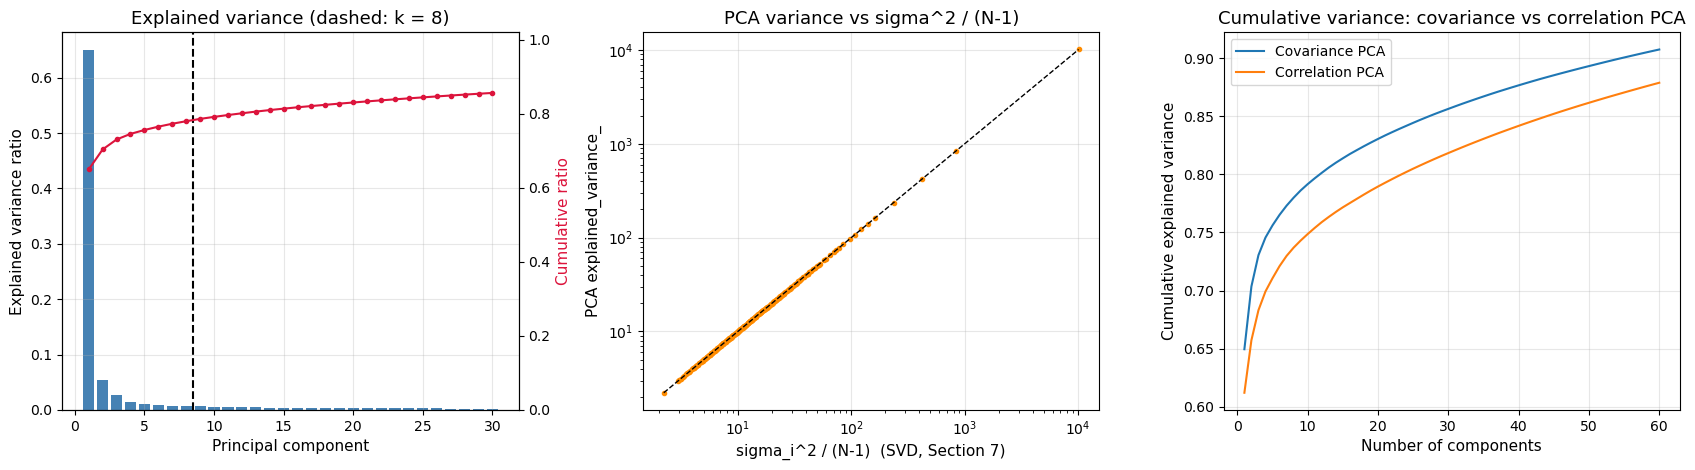

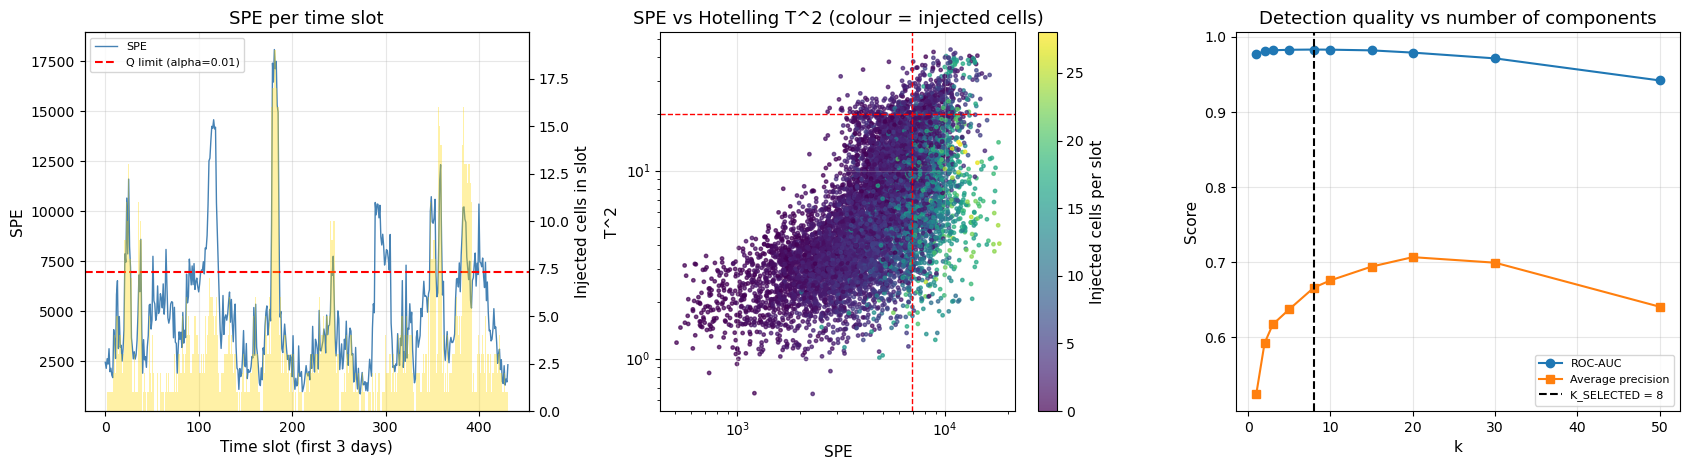

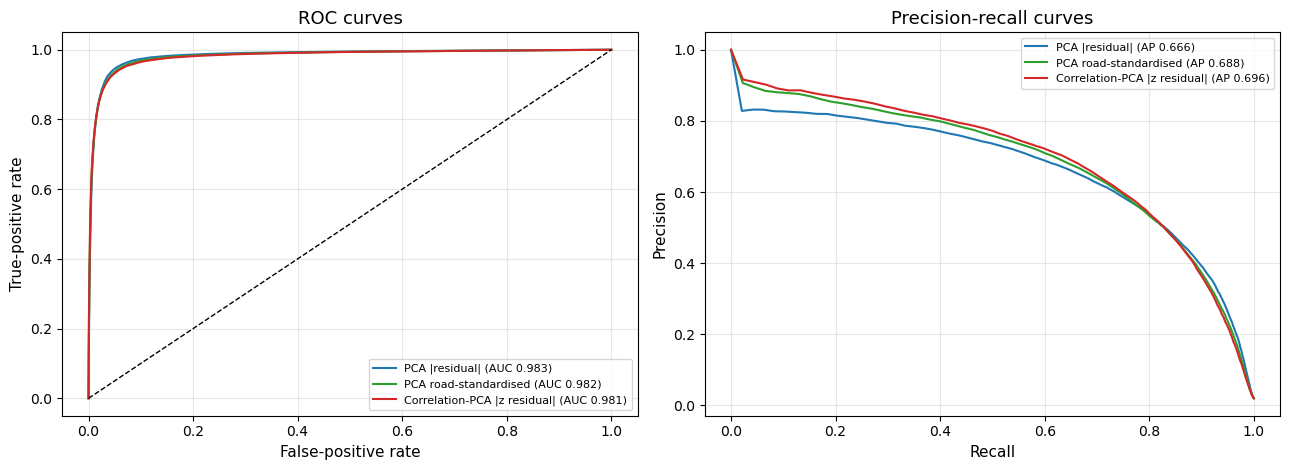


Section 11 complete. Variables available for later sections:
  pca_full, pca_anom, R_pca, spe, t2, score_pca, score_pca_road, score_pca_corr,
  pca_scores_table, k_sweep, Q_limit, T2_limit


In [15]:
# ============================================================
# SECTION 11: PRINCIPAL COMPONENT ANALYSIS (PCA)
# Requires: Sections 1-10
#   (X, X_anom, Y_true, eval_mask, K_SELECTED, Sc, Uc, Vtc, energy_share,
#    row_means, lowrank_reconstruct, m, n, n_times_clean, ANOMALY_RATE,
#    R_anom, RANDOM_STATE, PCA, StandardScaler)
# Output: pca_full, pca_anom, R_pca, spe, t2, pca_scores_table, k_sweep
# ============================================================

for _name in ["X", "X_anom", "Y_true", "eval_mask", "K_SELECTED", "Sc", "Uc", "Vtc",
              "energy_share", "row_means", "lowrank_reconstruct", "m", "n",
              "n_times_clean", "ANOMALY_RATE", "R_anom"]:
    if _name not in globals():
        raise NameError(f"'{_name}' is missing. Please run Sections 1-10 first.")

from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             precision_score, recall_score, f1_score)

N_SAMPLES = n                       # one sample per (day, time) slot
D = n // n_times_clean

# ------------------------------------------------------------
# 1. Orientation for scikit-learn: samples x features
#    samples  = the n = 8,784 time slots
#    features = the m = 209 roads
#    PCA subtracts the mean of every feature (= every road's mean speed),
#    which is exactly the row-centring used for X_c in Sections 6-8.
# ------------------------------------------------------------
Z = X.T                                     # (n x m), clean data
pca_full = PCA(n_components=None, svd_solver="full").fit(Z)
print(f"Data matrix for PCA : {Z.shape[0]:,} samples x {Z.shape[1]} features (roads)")
print(f"Components found    : {pca_full.n_components_}")

# ------------------------------------------------------------
# 2. PCA = SVD of the centred data (numerical proof against Section 7)
#    explained_variance_  = sigma_i^2 / (N - 1)
#    components_          = left singular vectors u_i (as rows)
#    transform(Z)         = V * Sigma  (the scores)
# ------------------------------------------------------------
ev_from_svd = Sc ** 2 / (N_SAMPLES - 1)
rel_ev = np.max(np.abs(pca_full.explained_variance_ - ev_from_svd) / ev_from_svd)
rel_ratio = np.max(np.abs(pca_full.explained_variance_ratio_ - energy_share))

n_cmp = 20                                                       # compare the leading axes
signs = np.sign(np.sum(pca_full.components_[:n_cmp] * Uc[:, :n_cmp].T, axis=1))
axis_gap = np.max(np.abs(pca_full.components_[:n_cmp] * signs[:, None] - Uc[:, :n_cmp].T))
scores_pca = pca_full.transform(Z)[:, :n_cmp]
score_gap = np.max(np.abs(scores_pca * signs - (Vtc[:n_cmp].T * Sc[:n_cmp])))
mean_gap = np.max(np.abs(pca_full.mean_ - row_means.ravel()))

pca_k = PCA(n_components=K_SELECTED, svd_solver="full").fit(Z)
recon_gap = np.max(np.abs(pca_k.inverse_transform(pca_k.transform(Z)).T - lowrank_reconstruct(K_SELECTED)))

equiv = pd.Series({
    "max rel. diff  explained_variance_ vs sigma^2/(N-1)": rel_ev,
    "max abs diff   variance ratio vs Section 7 energy share": rel_ratio,
    f"max abs diff   first {n_cmp} axes vs u_i (sign-aligned)": axis_gap,
    f"max abs diff   first {n_cmp} scores vs sigma_i v_i": score_gap,
    "max abs diff   PCA mean vs row means": mean_gap,
    f"max abs diff   rank-{K_SELECTED} reconstruction vs Section 8": recon_gap,
}, name="gap")
print("\n--- PCA vs SVD equivalence (clean data) ---")
display(equiv.map(lambda v: f"{v:.2e}").to_frame("gap"))

# ------------------------------------------------------------
# 3. Variance explained, and covariance-PCA vs correlation-PCA
#    Standardising every road (z-score) gives PCA of the CORRELATION matrix.
# ------------------------------------------------------------
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
scaler_clean = StandardScaler().fit(Z)
pca_corr_full = PCA(n_components=None, svd_solver="full").fit(scaler_clean.transform(Z))
cum_var_corr = np.cumsum(pca_corr_full.explained_variance_ratio_)

var_table = pd.DataFrame({
    "covariance PCA": [cum_var[k - 1] for k in (1, 2, 3, 5, 8, 10, 20)],
    "correlation PCA (standardised roads)": [cum_var_corr[k - 1] for k in (1, 2, 3, 5, 8, 10, 20)],
}, index=pd.Index([1, 2, 3, 5, 8, 10, 20], name="k"))
print("\n--- Cumulative explained variance ---")
display(var_table.map(lambda v: f"{v:.2%}") if hasattr(var_table, "map") else var_table.applymap(lambda v: f"{v:.2%}"))
kaiser = int(np.sum(pca_corr_full.explained_variance_ > 1.0))
print(f"Kaiser rule (correlation PCA, eigenvalue > 1): {kaiser} components (a rough guide only)")

# ------------------------------------------------------------
# 4. PCA fitted on the CONTAMINATED data (unsupervised, as in practice)
# ------------------------------------------------------------
Z_anom = X_anom.T
pca_anom_full = PCA(n_components=None, svd_solver="full").fit(Z_anom)
pca_anom = PCA(n_components=K_SELECTED, svd_solver="full").fit(Z_anom)

pc_scores = pca_anom.transform(Z_anom)                           # (n x k)
Z_hat = pca_anom.inverse_transform(pc_scores)                    # (n x m)
R_pca = (Z_anom - Z_hat).T                                       # back to (m x n)
res_gap = np.max(np.abs(R_pca - R_anom))
print(f"\nPCA residual vs SVD residual of Section 10 : max abs difference = {res_gap:.2e}")

# Classical PCA monitoring statistics for every time slot (column)
spe = np.sum((Z_anom - Z_hat) ** 2, axis=1)                      # Q / SPE: distance to the subspace
t2 = np.sum(pc_scores ** 2 / pca_anom.explained_variance_, axis=1)   # Hotelling T^2: distance inside it

alpha = 0.01
lam_res = pca_anom_full.explained_variance_[K_SELECTED:]         # discarded eigenvalues
th1, th2, th3 = lam_res.sum(), (lam_res ** 2).sum(), (lam_res ** 3).sum()
h0 = 1 - 2 * th1 * th3 / (3 * th2 ** 2)
c_a = stats.norm.ppf(1 - alpha)
Q_limit = th1 * (c_a * np.sqrt(2 * th2 * h0 ** 2) / th1 + 1 + th2 * h0 * (h0 - 1) / th1 ** 2) ** (1 / h0)
T2_limit = stats.chi2.ppf(1 - alpha, K_SELECTED)

load_per_slot = Y_true.sum(axis=0)                               # injected cells in each slot
rho_spe = stats.spearmanr(spe, load_per_slot)[0]
rho_t2 = stats.spearmanr(t2, load_per_slot)[0]
print("\n--- Slot-level PCA statistics (contaminated data) ---")
print(f"SPE control limit (Jackson-Mudholkar, alpha={alpha}) : {Q_limit:,.1f}   "
      f"-> {np.mean(spe > Q_limit):.1%} of slots above it (nominal {alpha:.0%})")
print(f"T^2 control limit (chi-square, k={K_SELECTED})           : {T2_limit:,.1f}   "
      f"-> {np.mean(t2 > T2_limit):.1%} of slots above it (nominal {alpha:.0%})")
print(f"Share of slots containing >= 1 injected cell        : {np.mean(load_per_slot > 0):.1%}")
print(f"Spearman(SPE, injected cells per slot)              : {rho_spe:.3f}")
print(f"Spearman(T^2, injected cells per slot)              : {rho_t2:.3f}")

# Contribution analysis: in the 100 slots with the largest SPE, is the single biggest
# contributor (road with the largest squared residual) a truly injected cell?
top_slots = np.argsort(spe)[::-1][:100]
top_road = np.argmax(R_pca[:, top_slots] ** 2, axis=0)
hit_rate = Y_true[top_road, top_slots].mean()
print(f"Contribution analysis (top-100 SPE slots): biggest contributor is an injected cell "
      f"in {hit_rate:.0%} of slots (base rate {Y_true.mean():.1%})")

# ------------------------------------------------------------
# 5. Cell-level anomaly scores from PCA (three variants)
# ------------------------------------------------------------
# (a) absolute residual (this equals the SVD detector of Section 10)
score_pca = np.abs(R_pca)

# (b) residual standardised by each road's robust residual scale
road_med = np.median(R_pca, axis=1, keepdims=True)
road_sigma = 1.4826 * np.median(np.abs(R_pca - road_med), axis=1, keepdims=True)
score_pca_road = np.abs(R_pca - road_med) / road_sigma

# (c) correlation PCA: standardise every road first, residual measured in z-units
scaler_anom = StandardScaler().fit(Z_anom)
Zs = scaler_anom.transform(Z_anom)
pca_corr = PCA(n_components=K_SELECTED, svd_solver="full").fit(Zs)
R_corr = (Zs - pca_corr.inverse_transform(pca_corr.transform(Zs))).T
score_pca_corr = np.abs(R_corr)

variants = {
    "PCA |residual|": score_pca,
    "PCA road-standardised": score_pca_road,
    "Correlation-PCA |z residual|": score_pca_corr,
}

y_eval = Y_true[eval_mask]
rows = []
for name, sc_ in variants.items():
    s = sc_[eval_mask]
    thr = np.quantile(s, 1 - ANOMALY_RATE)                       # flag the top 2% (assumed contamination)
    pred = s >= thr
    rows.append({
        "method": name,
        "ROC-AUC": roc_auc_score(y_eval, s),
        "avg. precision": average_precision_score(y_eval, s),
        "precision@top2%": precision_score(y_eval, pred),
        "recall@top2%": recall_score(y_eval, pred),
        "F1@top2%": f1_score(y_eval, pred),
    })
pca_scores_table = pd.DataFrame(rows).set_index("method")
print("\n--- Cell-level detection (moderate severity, k = %d) ---" % K_SELECTED)
display(pca_scores_table)

# ------------------------------------------------------------
# 6. Does the chosen k also suit detection? (re-test of K_SELECTED)
# ------------------------------------------------------------
mu_a = pca_anom_full.mean_
all_scores = pca_anom_full.transform(Z_anom)
comps = pca_anom_full.components_
ks_sweep = [1, 2, 3, 5, 8, 10, 15, 20, 30, 50]
sweep = []
for k in ks_sweep:
    Rk = (Z_anom - (mu_a + all_scores[:, :k] @ comps[:k])).T
    s = np.abs(Rk)[eval_mask]
    sweep.append({"k": k, "ROC-AUC": roc_auc_score(y_eval, s),
                  "avg. precision": average_precision_score(y_eval, s)})
k_sweep = pd.DataFrame(sweep).set_index("k")
print("\n--- Detection quality vs number of components ---")
display(k_sweep)
best_k_detect = int(k_sweep["avg. precision"].idxmax())
print(f"Best average precision at k = {best_k_detect}  (K_SELECTED from Section 9 = {K_SELECTED})")

# ------------------------------------------------------------
# 7. Visualizations
# ------------------------------------------------------------
# --- Figure 1: variance explained and PCA = SVD -------------------------
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
kmax = 30
axes[0].bar(np.arange(1, kmax + 1), pca_full.explained_variance_ratio_[:kmax], color="steelblue", label="Per component")
ax2 = axes[0].twinx()
ax2.plot(np.arange(1, kmax + 1), cum_var[:kmax], "o-", color="crimson", ms=3, label="Cumulative")
ax2.set_ylim(0, 1.02); ax2.set_ylabel("Cumulative ratio", color="crimson"); ax2.grid(False)
axes[0].axvline(K_SELECTED + 0.5, color="black", ls="--")
axes[0].set_title(f"Explained variance (dashed: k = {K_SELECTED})")
axes[0].set_xlabel("Principal component"); axes[0].set_ylabel("Explained variance ratio")

axes[1].loglog(ev_from_svd, pca_full.explained_variance_, "o", ms=3, color="darkorange")
lims = [ev_from_svd.min(), ev_from_svd.max()]
axes[1].plot(lims, lims, "k--", lw=1)
axes[1].set_title("PCA variance vs sigma^2 / (N-1)")
axes[1].set_xlabel("sigma_i^2 / (N-1)  (SVD, Section 7)"); axes[1].set_ylabel("PCA explained_variance_")

axes[2].plot(np.arange(1, 61), cum_var[:60], label="Covariance PCA")
axes[2].plot(np.arange(1, 61), cum_var_corr[:60], label="Correlation PCA")
axes[2].set_title("Cumulative variance: covariance vs correlation PCA")
axes[2].set_xlabel("Number of components"); axes[2].set_ylabel("Cumulative explained variance")
axes[2].legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "11_pca_variance.png"), dpi=150)
plt.show()

# --- Figure 2: monitoring statistics ------------------------------------
show_days = 3
zn = show_days * n_times_clean
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

axes[0].plot(spe[:zn], color="steelblue", lw=1, label="SPE")
axes[0].axhline(Q_limit, color="red", ls="--", label=f"Q limit (alpha={alpha})")
axes[0].set_ylabel("SPE"); axes[0].set_xlabel(f"Time slot (first {show_days} days)")
axes[0].set_title("SPE per time slot")
axb = axes[0].twinx()
axb.bar(np.arange(zn), load_per_slot[:zn], color="gold", alpha=0.35, width=1.0, label="Injected cells")
axb.set_ylabel("Injected cells in slot"); axb.grid(False)
axes[0].legend(loc="upper left", fontsize=8)

sc3 = axes[1].scatter(spe, t2, c=load_per_slot, cmap="viridis", s=6, alpha=0.7)
axes[1].axvline(Q_limit, color="red", ls="--", lw=1); axes[1].axhline(T2_limit, color="red", ls="--", lw=1)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title("SPE vs Hotelling T^2 (colour = injected cells)")
axes[1].set_xlabel("SPE"); axes[1].set_ylabel("T^2")
plt.colorbar(sc3, ax=axes[1], label="Injected cells per slot")

axes[2].plot(k_sweep.index, k_sweep["ROC-AUC"], "o-", label="ROC-AUC")
axes[2].plot(k_sweep.index, k_sweep["avg. precision"], "s-", label="Average precision")
axes[2].axvline(K_SELECTED, color="black", ls="--", label=f"K_SELECTED = {K_SELECTED}")
axes[2].set_title("Detection quality vs number of components")
axes[2].set_xlabel("k"); axes[2].set_ylabel("Score"); axes[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "11_pca_monitoring.png"), dpi=150)
plt.show()

# --- Figure 3: ROC and precision-recall of the three PCA variants --------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for (name, sc_), col in zip(variants.items(), ["tab:blue", "tab:green", "tab:red"]):
    s = sc_[eval_mask]
    fpr, tpr, _ = roc_curve(y_eval, s)
    keep = np.linspace(0, len(fpr) - 1, 2000).astype(int)
    axes[0].plot(fpr[keep], tpr[keep], color=col,
                 label=f"{name} (AUC {pca_scores_table.loc[name, 'ROC-AUC']:.3f})")
    prec, rec, _ = precision_recall_curve(y_eval, s)
    keep = np.linspace(0, len(prec) - 1, 2000).astype(int)
    axes[1].plot(rec[keep], prec[keep], color=col,
                 label=f"{name} (AP {pca_scores_table.loc[name, 'avg. precision']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("ROC curves"); axes[0].set_xlabel("False-positive rate"); axes[0].set_ylabel("True-positive rate")
axes[0].legend(fontsize=8)
axes[1].set_title("Precision-recall curves"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "11_pca_detection_curves.png"), dpi=150)
plt.show()

print("\nSection 11 complete. Variables available for later sections:")
print("  pca_full, pca_anom, R_pca, spe, t2, score_pca, score_pca_road, score_pca_corr,")
print("  pca_scores_table, k_sweep, Q_limit, T2_limit")

--- Tensors ---
Order (number of modes)    : 3
Shape (roads, days, times) : (209, 61, 144)
Number of entries          : 1,835,856
Memory per tensor          : 14.69 MB
Cross-check passed: X_tensor equals the Section 4 cube.

||tensor||_F = 54,971.0845   vs   ||X||_F (Section 5) = 54,971.0845   -> equal: True

--- Mode-n unfoldings of the centred tensor ---
X_(1) roads (mode 1)        : shape (209, 8784)
X_(2) days (mode 2)         : shape (61, 30096)
X_(3) time of day (mode 3)  : shape (144, 12749)
Mode-1 unfolding equals the matrix X from Section 5.
fold(unfold(T, n), n, shape) == T  for all three modes.
Frobenius norm of every unfolding: ['11,702.38', '11,702.38', '11,702.38'] | tensor: 11,702.38

Mode-2 product with a 5 x 61 matrix: (209, 61, 144) -> (209, 5, 144)
Identity (T x_2 A)_(2) = A T_(2) holds: True

--- Multilinear rank analysis (centred tensor) ---


,size,numerical rank,sigma_1 energy,k for 90% energy,k for 95% energy,k for 99% energy
mode,,,,,,
roads (mode 1),209,209,0.6496,55,102,174
days (mode 2),61,61,0.6812,25,41,56
time of day (mode 3),144,144,0.6042,14,34,103


Mode-1 singular values equal Sc from Section 7.

Energy captured by the first r components of each mode:


,roads (mode 1),days (mode 2),time of day (mode 3)
1,64.96%,68.12%,60.42%
2,70.36%,74.32%,68.16%
3,73.05%,77.62%,74.60%
5,75.61%,79.98%,81.62%
8,77.99%,82.20%,85.91%
10,79.16%,83.39%,87.77%
20,83.05%,88.15%,92.43%



Day-mode factors (columns of U_2): autocorrelation at lag 1 and lag 7
  factor 1: lag-1 +0.273 | lag-7 +0.168
  factor 2: lag-1 +0.311 | lag-7 +0.439
  factor 3: lag-1 +0.536 | lag-7 +0.201


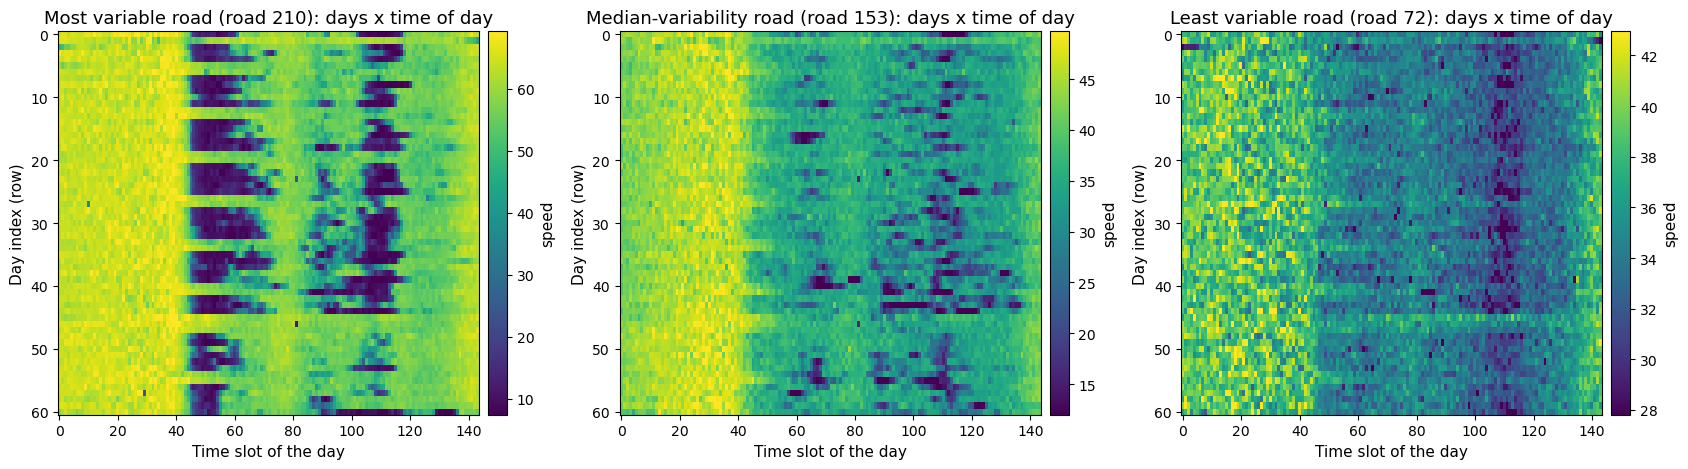

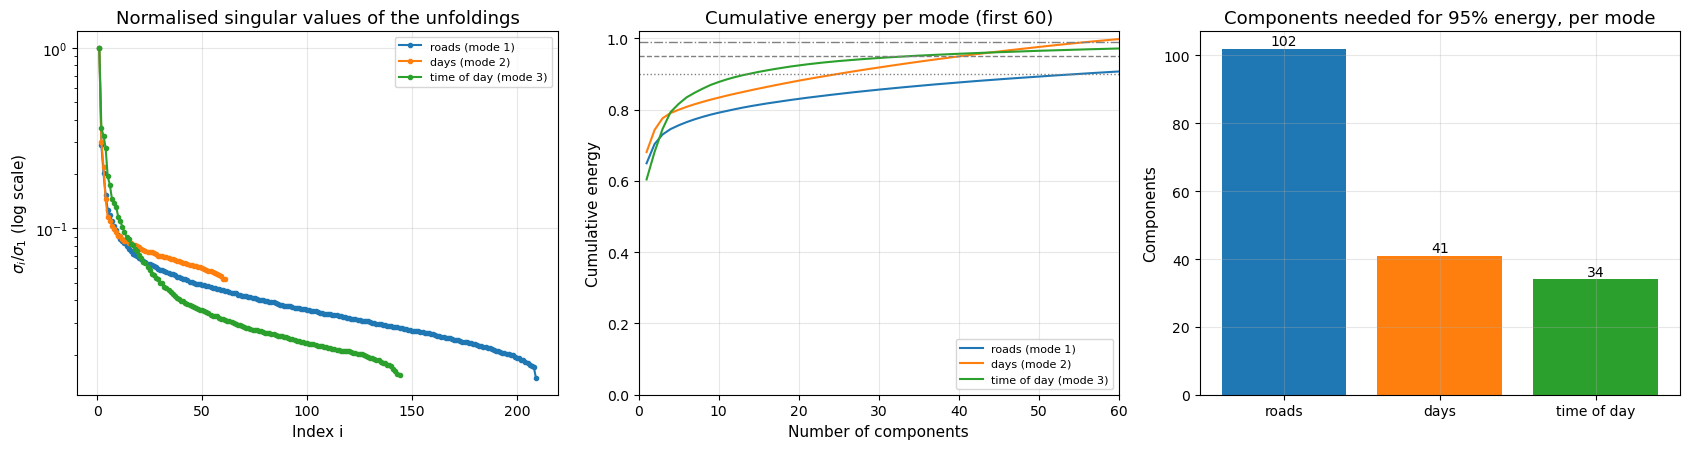

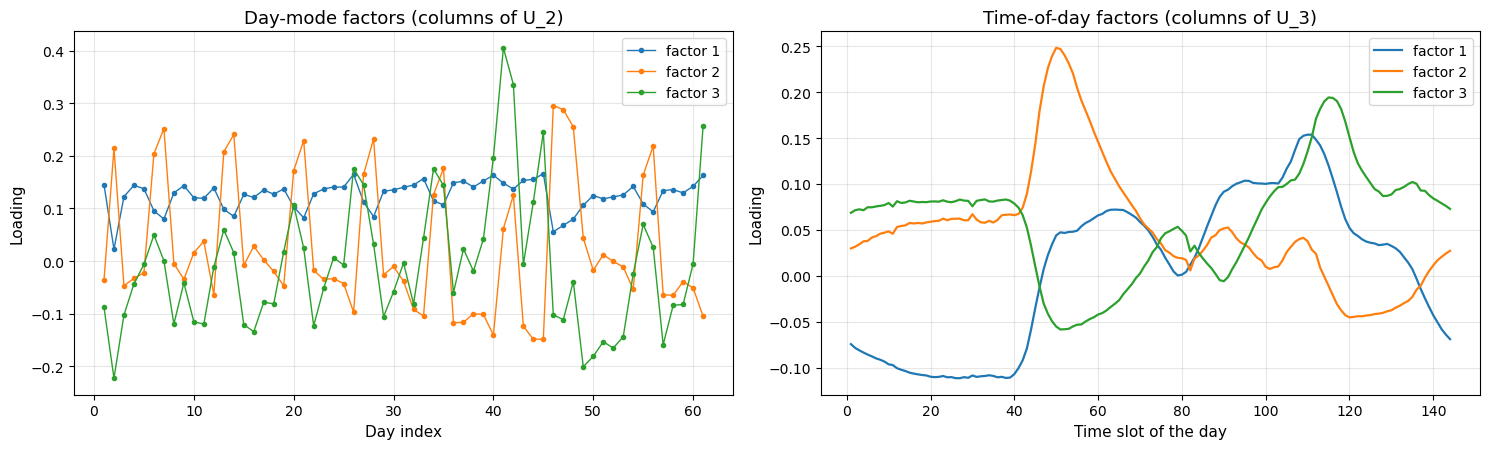


Section 12 complete. Variables available for later sections:
  X_tensor, X_anom_tensor, Xc_tensor, Xc_anom_tensor, Y_true_tensor, eval_mask_tensor,
  imputed_tensor, TENSOR_SHAPE, unfoldings, mode_spectra, mode_factors, multilinear_table


In [16]:
# ============================================================
# SECTION 12: TENSOR REPRESENTATION
# Requires: Sections 1-11
#   (X, X_anom, Y_true, eval_mask, X_imputed_mask, row_means, row_means_anom,
#    Sc, m, n, n_times_clean, row_labels, time_ids, fro_X, tl, unfold, fold)
# Output: X_tensor, X_anom_tensor, Xc_tensor, Xc_anom_tensor, Y_true_tensor,
#         eval_mask_tensor, TENSOR_SHAPE, multilinear_table, mode_factors
# ============================================================

for _name in ["X", "X_anom", "Y_true", "eval_mask", "X_imputed_mask", "row_means",
              "row_means_anom", "Sc", "m", "n", "n_times_clean", "row_labels",
              "time_ids", "fro_X", "tl", "unfold", "fold"]:
    if _name not in globals():
        raise NameError(f"'{_name}' is missing. Please run Sections 1-11 first.")

n_roads_t = m
n_days_t = n // n_times_clean
n_times_t = n_times_clean
TENSOR_SHAPE = (n_roads_t, n_days_t, n_times_t)
MODE_NAMES = ["roads (mode 1)", "days (mode 2)", "time of day (mode 3)"]

# ------------------------------------------------------------
# 1. Reshape the matrices into third-order tensors  roads x days x times
#    The columns of X are ordered day by day, so a plain reshape is correct:
#    column index = day * n_times + time.
# ------------------------------------------------------------
X_tensor      = tl.tensor(X.reshape(TENSOR_SHAPE))                 # clean
X_anom_tensor = tl.tensor(X_anom.reshape(TENSOR_SHAPE))            # with injected anomalies
Y_true_tensor    = Y_true.reshape(TENSOR_SHAPE)                    # ground truth
eval_mask_tensor = eval_mask.reshape(TENSOR_SHAPE)                 # observed (non-imputed) cells
imputed_tensor   = X_imputed_mask.reshape(TENSOR_SHAPE)

# Remove each road's mean level, exactly as in the matrix / PCA models
Xc_tensor      = X_tensor - row_means.reshape(n_roads_t, 1, 1)
Xc_anom_tensor = X_anom_tensor - row_means_anom.reshape(n_roads_t, 1, 1)

print("--- Tensors ---")
print(f"Order (number of modes)    : {X_tensor.ndim}")
print(f"Shape (roads, days, times) : {X_tensor.shape}")
print(f"Number of entries          : {X_tensor.size:,}")
print(f"Memory per tensor          : {X_tensor.nbytes / 1e6:,.2f} MB")

# Consistency checks against earlier sections
if "cube_filled" in globals():
    assert np.allclose(X_tensor, cube_filled), "X_tensor differs from the Section 4 cube."
    print("Cross-check passed: X_tensor equals the Section 4 cube.")
assert X_tensor[0, 0, 0] == X[0, 0] and X_tensor[5, 2, 7] == X[5, 2 * n_times_t + 7]
assert np.array_equal(Y_true_tensor.sum(axis=(1, 2)), Y_true.sum(axis=1))

# Frobenius norm of a tensor: sqrt of the sum of ALL squared entries
fro_tensor = float(tl.norm(X_tensor, 2))
print(f"\n||tensor||_F = {fro_tensor:,.4f}   vs   ||X||_F (Section 5) = {fro_X:,.4f}   "
      f"-> equal: {np.isclose(fro_tensor, fro_X)}")

# ------------------------------------------------------------
# 2. Mode-n unfoldings (matricisation)  X_(n)
#    TensorLy puts mode n on the rows and flattens the other modes (C order).
#    X_(1): roads x (days*times)   -> this IS the matrix X of Section 5
#    X_(2): days  x (roads*times)
#    X_(3): times x (roads*days)
# ------------------------------------------------------------
unfoldings = {mode: unfold(Xc_tensor, mode) for mode in range(3)}
print("\n--- Mode-n unfoldings of the centred tensor ---")
for mode in range(3):
    print(f"X_({mode + 1}) {MODE_NAMES[mode]:<22}: shape {unfoldings[mode].shape}")

assert np.allclose(unfold(X_tensor, 0), X), "Mode-1 unfolding should equal the matrix X."
print("Mode-1 unfolding equals the matrix X from Section 5.")

# fold() inverts unfold()
for mode in range(3):
    back = fold(unfoldings[mode], mode, Xc_tensor.shape)
    assert np.allclose(back, Xc_tensor)
print("fold(unfold(T, n), n, shape) == T  for all three modes.")

# All unfoldings contain the same entries, hence the same Frobenius norm
norms = [np.linalg.norm(unfoldings[mode], "fro") for mode in range(3)]
print("Frobenius norm of every unfolding:", [f"{v:,.2f}" for v in norms],
      f"| tensor: {tl.norm(Xc_tensor, 2):,.2f}")

# ------------------------------------------------------------
# 3. Mode-n product and its unfolding identity
#    (T x_n A)_(n) = A  T_(n)       with  A of shape (new_dim, old_dim)
# ------------------------------------------------------------
rng_t = np.random.default_rng(RANDOM_STATE)
A_demo = rng_t.standard_normal((5, n_days_t))                      # compresses the day mode 61 -> 5
prod = tl.tenalg.mode_dot(Xc_tensor, A_demo, mode=1)
print(f"\nMode-2 product with a 5 x {n_days_t} matrix: {Xc_tensor.shape} -> {prod.shape}")
print("Identity (T x_2 A)_(2) = A T_(2) holds:",
      np.allclose(unfold(prod, 1), A_demo @ unfoldings[1]))

# ------------------------------------------------------------
# 4. Multilinear rank analysis: singular values of every unfolding
#    The mode-n rank r_n = rank(T_(n)); the tuple (r_1, r_2, r_3) is the
#    multilinear rank, which sets the size of the Tucker core in Section 13.
# ------------------------------------------------------------
mode_spectra, mode_factors, rows = {}, {}, []

def fix_sign_cols(U_):
    """Make the largest-magnitude entry of each column positive (reproducible plots)."""
    idx = np.argmax(np.abs(U_), axis=0)
    sg = np.sign(U_[idx, np.arange(U_.shape[1])]); sg[sg == 0] = 1
    return U_ * sg

for mode in range(3):
    U_n, s_n, _ = sla.svd(unfoldings[mode], full_matrices=False)
    mode_spectra[mode] = s_n
    mode_factors[mode] = fix_sign_cols(U_n)                        # HOSVD-style factor matrix
    energy = s_n ** 2
    cum = np.cumsum(energy) / energy.sum()
    rows.append({
        "mode": MODE_NAMES[mode],
        "size": unfoldings[mode].shape[0],
        "numerical rank": int(np.linalg.matrix_rank(unfoldings[mode])),
        "sigma_1 energy": cum[0],
        "k for 90% energy": int(np.searchsorted(cum, 0.90) + 1),
        "k for 95% energy": int(np.searchsorted(cum, 0.95) + 1),
        "k for 99% energy": int(np.searchsorted(cum, 0.99) + 1),
    })
multilinear_table = pd.DataFrame(rows).set_index("mode")
print("\n--- Multilinear rank analysis (centred tensor) ---")
display(multilinear_table)

assert np.allclose(mode_spectra[0], Sc), "Mode-1 spectrum must equal the matrix spectrum (Section 6/7)."
print("Mode-1 singular values equal Sc from Section 7.")

# Energy captured by the first r components of each mode
rs = [1, 2, 3, 5, 8, 10, 20]
cum_table = pd.DataFrame({
    MODE_NAMES[mode]: [np.sum(mode_spectra[mode][:r] ** 2) / np.sum(mode_spectra[mode] ** 2)
                       for r in rs if r <= len(mode_spectra[mode])]
    for mode in range(3)
}, index=[r for r in rs])
print("\nEnergy captured by the first r components of each mode:")
display(cum_table.map(lambda v: f"{v:.2%}") if hasattr(cum_table, "map") else cum_table.applymap(lambda v: f"{v:.2%}"))

# Day-mode factors: is there a repeating pattern across days?
def autocorr(x, lag):
    x = x - x.mean()
    return float(np.sum(x[lag:] * x[:-lag]) / np.sum(x * x))
print("\nDay-mode factors (columns of U_2): autocorrelation at lag 1 and lag 7")
for i in range(3):
    f = mode_factors[1][:, i]
    print(f"  factor {i + 1}: lag-1 {autocorr(f, 1):+.3f} | lag-7 {autocorr(f, 7):+.3f}")

# ------------------------------------------------------------
# 5. Visualizations
# ------------------------------------------------------------
# --- Figure 1: frontal views, one road = one (days x times) matrix ------
row_std_t = X.std(axis=1)
view_roads = [int(np.argmax(row_std_t)), int(np.argsort(row_std_t)[len(row_std_t) // 2]), int(np.argmin(row_std_t))]
view_titles = ["Most variable road", "Median-variability road", "Least variable road"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, r, ttl in zip(axes, view_roads, view_titles):
    vlo, vhi = np.percentile(X_tensor[r], [1, 99])
    im = ax.imshow(X_tensor[r], aspect="auto", cmap="viridis", vmin=vlo, vmax=vhi, interpolation="nearest")
    ax.set_title(f"{ttl} (road {row_labels[r]}): days x time of day")
    ax.set_xlabel("Time slot of the day"); ax.set_ylabel("Day index (row)"); ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.02, label=VALUE_COL)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "12_tensor_road_slices.png"), dpi=150)
plt.show()

# --- Figure 2: multilinear spectra --------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
cols_ = ["tab:blue", "tab:orange", "tab:green"]
for mode in range(3):
    s_n = mode_spectra[mode]
    axes[0].semilogy(np.arange(1, len(s_n) + 1), s_n / s_n[0], "o-", ms=3, color=cols_[mode], label=MODE_NAMES[mode])
    cum = np.cumsum(s_n ** 2) / np.sum(s_n ** 2)
    axes[1].plot(np.arange(1, len(s_n) + 1), cum, color=cols_[mode], label=MODE_NAMES[mode])
axes[0].set_title("Normalised singular values of the unfoldings")
axes[0].set_xlabel("Index i"); axes[0].set_ylabel(r"$\sigma_i / \sigma_1$ (log scale)"); axes[0].legend(fontsize=8)
for t_, ls_ in zip([0.90, 0.95, 0.99], [":", "--", "-."]):
    axes[1].axhline(t_, color="gray", ls=ls_, lw=1)
axes[1].set_xlim(0, 60); axes[1].set_ylim(0, 1.02)
axes[1].set_title("Cumulative energy per mode (first 60)")
axes[1].set_xlabel("Number of components"); axes[1].set_ylabel("Cumulative energy"); axes[1].legend(fontsize=8, loc="lower right")

axes[2].bar(multilinear_table.index.str.replace(r" \(mode \d\)", "", regex=True),
            multilinear_table["k for 95% energy"], color=cols_)
for i, v in enumerate(multilinear_table["k for 95% energy"]):
    axes[2].text(i, v + 1, str(v), ha="center")
axes[2].set_title("Components needed for 95% energy, per mode")
axes[2].set_ylabel("Components")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "12_tensor_mode_spectra.png"), dpi=150)
plt.show()

# --- Figure 3: leading factor vectors of the day and time modes -----------
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for i in range(3):
    axes[0].plot(np.arange(1, n_days_t + 1), mode_factors[1][:, i], "o-", ms=3, lw=1, label=f"factor {i + 1}")
    axes[1].plot(time_ids, mode_factors[2][:, i], lw=1.6, label=f"factor {i + 1}")
axes[0].set_title("Day-mode factors (columns of U_2)"); axes[0].set_xlabel("Day index"); axes[0].set_ylabel("Loading"); axes[0].legend()
axes[1].set_title("Time-of-day factors (columns of U_3)"); axes[1].set_xlabel("Time slot of the day"); axes[1].set_ylabel("Loading"); axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "12_tensor_mode_factors.png"), dpi=150)
plt.show()

print("\nSection 12 complete. Variables available for later sections:")
print("  X_tensor, X_anom_tensor, Xc_tensor, Xc_anom_tensor, Y_true_tensor, eval_mask_tensor,")
print("  imputed_tensor, TENSOR_SHAPE, unfoldings, mode_spectra, mode_factors, multilinear_table")

--- HOSVD energy map ---
Energy of the rank-8 matrix model (Section 6) : 77.9910%
Energy of Tucker ranks (8, 61, 144)            : 77.9910%   -> identical: True

Target relative error (rank-8 matrix model): 0.4691
Smallest-parameter Tucker ranks reaching it (HOSVD)  : (16, 14, 10)
Stored numbers: Tucker 7,878  vs  rank-8 matrix 71,952  -> 9.1x fewer
HOSVD error at these ranks: 5,485.48   |  spectral upper bound: 7,852.05   -> bound holds: True

--- Tucker (HOOI) on the clean tensor, ranks (16, 14, 10) ---
Fitting time                        : 3.8 s
Core shape                          : (16, 14, 10)
Factor shapes                       : [(209, 16), (61, 14), (144, 10)]
Max |U^T U - I| over the factors    : 2.00e-15
||T - T_hat||^2 = ||T||^2 - ||G||^2 : gap 3.81e-16 (relative)
HOOI error 5,410.31  <=  HOSVD error 5,485.48  : True

--- Reconstruction accuracy on the clean data ---


,stored numbers,rel. error vs Xc,RMSE (observed cells)
Matrix rank-8 (SVD / PCA),71952,0.4691,4.0499
"Tucker HOSVD (16, 14, 10)",7878,0.4687,4.0467
"Tucker HOOI (16, 14, 10)",7878,0.4623,3.9910



--- Cell-level detection on contaminated data (fitting time 3.2 s) ---


,ROC-AUC,avg. precision,precision@top2%,recall@top2%,F1@top2%
method,,,,,
PCA |residual|,0.9832,0.6663,0.6568,0.6551,0.6560
PCA road-standardised,0.9819,0.6875,0.6673,0.6655,0.6664
Tucker |residual|,0.9858,0.6767,0.6659,0.6642,0.6651
Tucker road-standardised,0.9851,0.7064,0.6798,0.6779,0.6788



--- Detection quality vs Tucker ranks ---


,ranks,stored numbers,ROC-AUC,avg. precision
config,,,,
ranks x 0.5,"(8, 7, 5)",3099,0.9847,0.6429
ranks x 0.75,"(12, 10, 8)",5230,0.9857,0.6627
selected,"(16, 14, 10)",7878,0.9858,0.6767
ranks x 1.5,"(24, 21, 15)",16017,0.9849,0.6977
ranks x 2.0,"(32, 28, 20)",29196,0.9818,0.7024


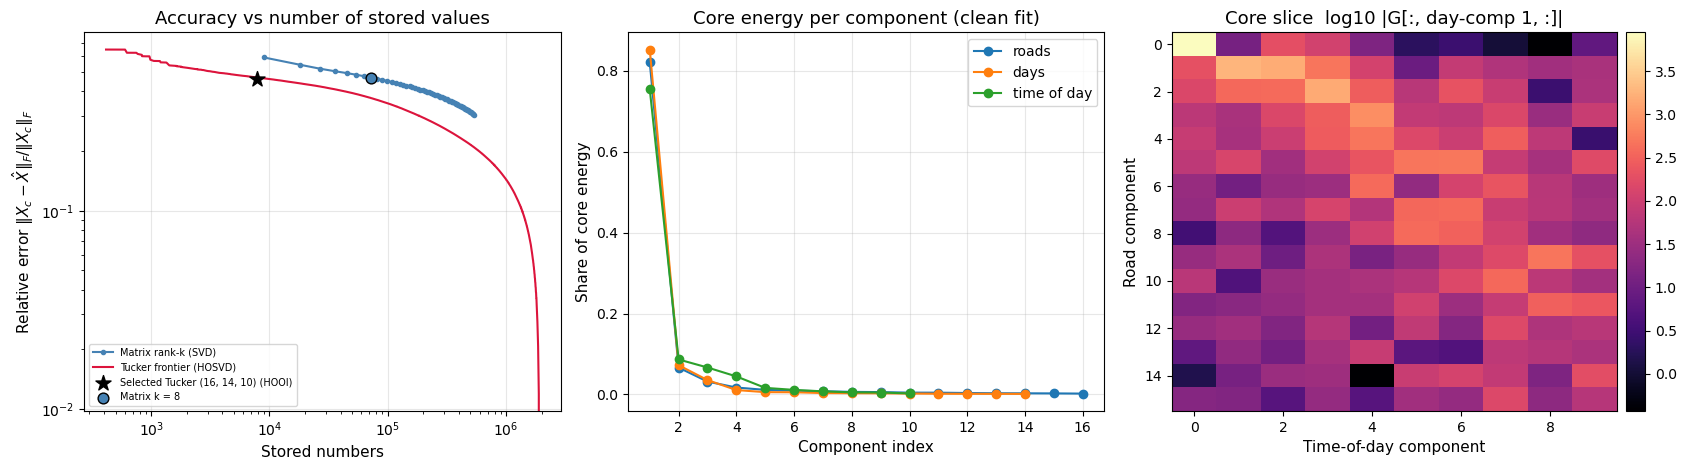

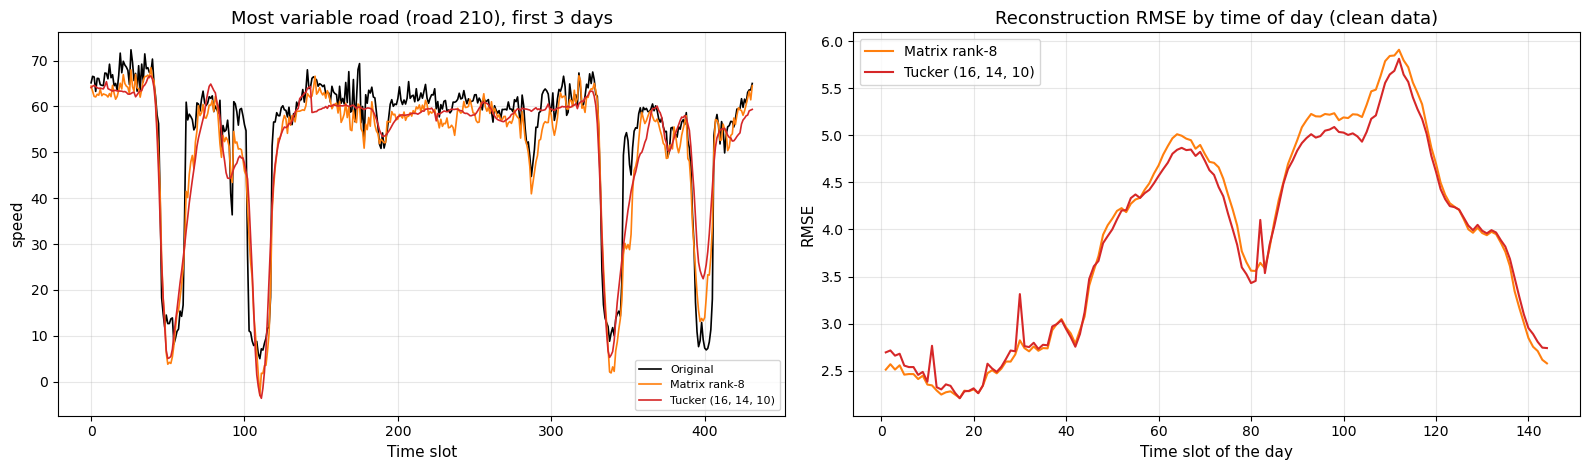

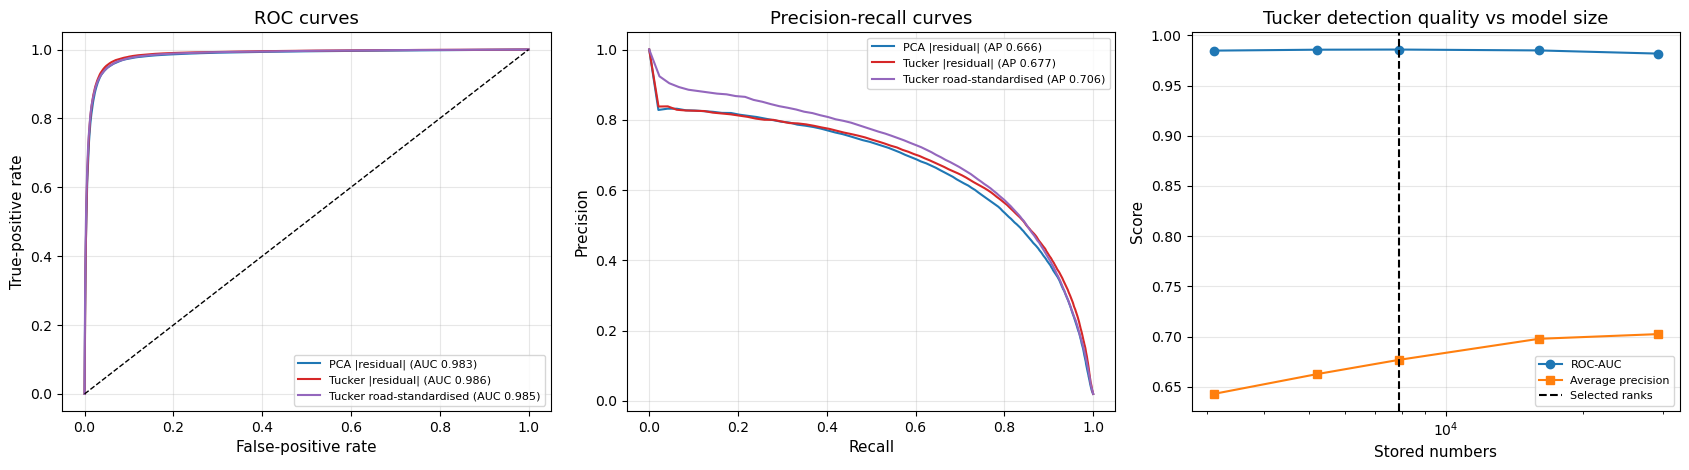


Section 13 complete. Variables available for later sections:
  TUCKER_RANKS, core_clean, factors_clean, core_anom, factors_anom, R_tucker,
  score_tucker, score_tucker_road, tucker_scores_table, tucker_sweep, fit_tucker(), tucker_reconstruct()


In [17]:
# ============================================================
# SECTION 13: TUCKER DECOMPOSITION
# Requires: Sections 1-12
#   (Xc_tensor, Xc_anom_tensor, X_tensor, X_anom_tensor, row_means, row_means_anom,
#    TENSOR_SHAPE, mode_factors, mode_spectra, Y_true, eval_mask, eval_mask_tensor,
#    K_SELECTED, rel_err_curve, cum_Xc, m, n, n_times_clean, X_hat, slot_rmse,
#    score_pca, score_pca_road, pca_scores_table, ANOMALY_RATE, RANDOM_STATE, tl, tucker)
# Output: TUCKER_RANKS, core_clean, factors_clean, core_anom, factors_anom, R_tucker,
#         score_tucker, score_tucker_road, tucker_scores_table, tucker_sweep
# ============================================================
import time

for _name in ["Xc_tensor", "Xc_anom_tensor", "X_tensor", "row_means", "row_means_anom",
              "TENSOR_SHAPE", "mode_factors", "mode_spectra", "Y_true", "eval_mask",
              "eval_mask_tensor", "K_SELECTED", "rel_err_curve", "cum_Xc", "m", "n",
              "n_times_clean", "X_hat", "slot_rmse", "score_pca", "score_pca_road",
              "pca_scores_table", "ANOMALY_RATE", "tl", "tucker"]:
    if _name not in globals():
        raise NameError(f"'{_name}' is missing. Please run Sections 1-12 first.")

from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             precision_score, recall_score, f1_score)

N1, N2, N3 = TENSOR_SHAPE
fro_t = float(tl.norm(Xc_tensor, 2))                     # ||Xc||_F of the centred tensor

# ------------------------------------------------------------
# 0. Helper functions
# ------------------------------------------------------------
def tucker_reconstruct(core, factors):
    """T_hat = G x_1 U1 x_2 U2 x_3 U3 (built from mode-n products)."""
    out = core
    for mode, U_ in enumerate(factors):
        out = tl.tenalg.mode_dot(out, U_, mode)
    return out

def tucker_n_params(ranks, shape=TENSOR_SHAPE):
    """Numbers stored: core r1*r2*r3 plus the factor matrices n_i * r_i."""
    return int(np.prod(ranks) + sum(nn * rr for nn, rr in zip(shape, ranks)))

def fit_tucker(tensor, ranks, n_iter_max=30, tol=1e-5):
    """Tucker decomposition by HOOI (TensorLy), initialised with the HOSVD."""
    res = tucker(tensor, rank=[int(r) for r in ranks], n_iter_max=n_iter_max,
                 init="svd", tol=tol, random_state=RANDOM_STATE, verbose=False)
    return res[0], res[1]                                 # core, list of factor matrices

def masked_rmse_t(res_tensor):
    return float(np.sqrt(np.mean(res_tensor[eval_mask_tensor] ** 2)))

# ------------------------------------------------------------
# 1. HOSVD energy map: the error of EVERY multilinear rank (r1, r2, r3) at once
#    With the full orthogonal factors U_n from Section 12,
#        G_full = Xc x_1 U1^T x_2 U2^T x_3 U3^T
#    and the HOSVD core for ranks (r1, r2, r3) is just the sub-block G_full[:r1, :r2, :r3].
#    Because U_n have orthonormal columns:  error^2 = ||Xc||^2 - ||G[:r1,:r2,:r3]||^2.
# ------------------------------------------------------------
G_full = Xc_tensor
for mode in range(3):
    G_full = tl.tenalg.mode_dot(G_full, mode_factors[mode].T, mode)
energy_map = np.cumsum(np.cumsum(np.cumsum(G_full ** 2, axis=0), axis=1), axis=2)
assert np.isclose(energy_map[-1, -1, -1], fro_t ** 2), "Orthogonal transform must preserve energy."
rel_err_map = np.sqrt(np.clip(1.0 - energy_map / fro_t ** 2, 0.0, None))     # relative HOSVD error

# Sanity link to the matrix SVD: keeping ALL days and times with r1 = k is the rank-k matrix model
chk = energy_map[K_SELECTED - 1, -1, -1] / fro_t ** 2
print("--- HOSVD energy map ---")
print(f"Energy of the rank-{K_SELECTED} matrix model (Section 6) : {cum_Xc[K_SELECTED - 1]:.4%}")
print(f"Energy of Tucker ranks ({K_SELECTED}, {N2}, {N3})            : {chk:.4%}   "
      f"-> identical: {np.isclose(chk, cum_Xc[K_SELECTED - 1])}")

# ------------------------------------------------------------
# 2. Choosing the multilinear ranks by an equal-error rule
#    Target: reach at least the accuracy of the rank-K_SELECTED matrix model
#    with the FEWEST stored numbers. (Chosen on the clean tensor, like k in Section 9.)
# ------------------------------------------------------------
target_rel_err = float(rel_err_curve[K_SELECTED - 1])
R1, R2, R3 = np.meshgrid(np.arange(1, N1 + 1), np.arange(1, N2 + 1), np.arange(1, N3 + 1), indexing="ij")
param_map = R1 * R2 * R3 + N1 * R1 + N2 * R2 + N3 * R3

feasible = rel_err_map <= target_rel_err
cand = np.where(feasible, param_map, np.iinfo(np.int64).max)
best = np.unravel_index(np.argmin(cand), cand.shape)
TUCKER_RANKS = tuple(int(i) + 1 for i in best)
matrix_params = K_SELECTED * (m + n + 1)

print(f"\nTarget relative error (rank-{K_SELECTED} matrix model): {target_rel_err:.4f}")
print(f"Smallest-parameter Tucker ranks reaching it (HOSVD)  : {TUCKER_RANKS}")
print(f"Stored numbers: Tucker {tucker_n_params(TUCKER_RANKS):,}  vs  rank-{K_SELECTED} matrix {matrix_params:,}  "
      f"-> {matrix_params / tucker_n_params(TUCKER_RANKS):.1f}x fewer")

# Classical HOSVD error bound from the mode spectra (Section 12):
#   ||T - T_hat||^2 <= sum_n sum_{i > r_n} sigma_i^(n)^2
bound = np.sqrt(sum(np.sum(mode_spectra[mode][TUCKER_RANKS[mode]:] ** 2) for mode in range(3)))
hosvd_err = rel_err_map[tuple(r - 1 for r in TUCKER_RANKS)] * fro_t
print(f"HOSVD error at these ranks: {hosvd_err:,.2f}   |  spectral upper bound: {bound:,.2f}   "
      f"-> bound holds: {hosvd_err <= bound + 1e-6}")

# Pareto frontier: smallest error for every parameter budget
order = np.argsort(param_map.ravel())
err_sorted = rel_err_map.ravel()[order]
run_min = np.minimum.accumulate(err_sorted)
front = np.flatnonzero(err_sorted <= run_min)
frontier_params = param_map.ravel()[order][front]
frontier_err = err_sorted[front]

# ------------------------------------------------------------
# 3. Fit Tucker (HOOI) on the CLEAN centred tensor
# ------------------------------------------------------------
t0 = time.perf_counter()
core_clean, factors_clean = fit_tucker(Xc_tensor, TUCKER_RANKS)
t_fit = time.perf_counter() - t0
recon_clean = tucker_reconstruct(core_clean, factors_clean)
res_clean = Xc_tensor - recon_clean

orth_gap = max(np.max(np.abs(U_.T @ U_ - np.eye(U_.shape[1]))) for U_ in factors_clean)
err_hooi = float(tl.norm(res_clean, 2))
proj_gap = abs(err_hooi ** 2 - (fro_t ** 2 - float(tl.norm(core_clean, 2)) ** 2)) / fro_t ** 2

print(f"\n--- Tucker (HOOI) on the clean tensor, ranks {TUCKER_RANKS} ---")
print(f"Fitting time                        : {t_fit:.1f} s")
print(f"Core shape                          : {tuple(core_clean.shape)}")
print(f"Factor shapes                       : {[tuple(U_.shape) for U_ in factors_clean]}")
print(f"Max |U^T U - I| over the factors    : {orth_gap:.2e}")
print(f"||T - T_hat||^2 = ||T||^2 - ||G||^2 : gap {proj_gap:.2e} (relative)")
print(f"HOOI error {err_hooi:,.2f}  <=  HOSVD error {hosvd_err:,.2f}  : {err_hooi <= hosvd_err + 1e-6}")

# HOSVD reconstruction (sub-blocks of the full HOSVD core and of the Section 12 factors)
hosvd_core = G_full[:TUCKER_RANKS[0], :TUCKER_RANKS[1], :TUCKER_RANKS[2]]
hosvd_factors = [mode_factors[i][:, :TUCKER_RANKS[i]] for i in range(3)]
rmse_hosvd = masked_rmse_t(Xc_tensor - tucker_reconstruct(hosvd_core, hosvd_factors))

fit_table = pd.DataFrame([
    {"stored numbers": matrix_params, "rel. error vs Xc": target_rel_err,
     "RMSE (observed cells)": float(overall_rmse) if "overall_rmse" in globals() else np.nan},
    {"stored numbers": tucker_n_params(TUCKER_RANKS), "rel. error vs Xc": hosvd_err / fro_t,
     "RMSE (observed cells)": rmse_hosvd},
    {"stored numbers": tucker_n_params(TUCKER_RANKS), "rel. error vs Xc": err_hooi / fro_t,
     "RMSE (observed cells)": masked_rmse_t(res_clean)},
], index=[f"Matrix rank-{K_SELECTED} (SVD / PCA)", f"Tucker HOSVD {TUCKER_RANKS}", f"Tucker HOOI {TUCKER_RANKS}"])
print("\n--- Reconstruction accuracy on the clean data ---")
display(fit_table)

# ------------------------------------------------------------
# 4. Fit Tucker on the CONTAMINATED tensor and score the residuals
# ------------------------------------------------------------
t0 = time.perf_counter()
core_anom, factors_anom = fit_tucker(Xc_anom_tensor, TUCKER_RANKS)
t_fit_a = time.perf_counter() - t0
R_tucker_tensor = Xc_anom_tensor - tucker_reconstruct(core_anom, factors_anom)
R_tucker = np.asarray(R_tucker_tensor).reshape(m, n)                 # same layout as R_pca

score_tucker = np.abs(R_tucker)
road_med_t = np.median(R_tucker, axis=1, keepdims=True)
road_sig_t = 1.4826 * np.median(np.abs(R_tucker - road_med_t), axis=1, keepdims=True)
score_tucker_road = np.abs(R_tucker - road_med_t) / road_sig_t

y_eval = Y_true[eval_mask]
def evaluate(name, score):
    s = score[eval_mask]
    pred = s >= np.quantile(s, 1 - ANOMALY_RATE)                      # flag the top 2%
    return {"method": name, "ROC-AUC": roc_auc_score(y_eval, s),
            "avg. precision": average_precision_score(y_eval, s),
            "precision@top2%": precision_score(y_eval, pred),
            "recall@top2%": recall_score(y_eval, pred),
            "F1@top2%": f1_score(y_eval, pred)}

tucker_scores_table = pd.DataFrame([
    evaluate("Tucker |residual|", score_tucker),
    evaluate("Tucker road-standardised", score_tucker_road),
]).set_index("method")
compare_table = pd.concat([pca_scores_table.loc[["PCA |residual|", "PCA road-standardised"]], tucker_scores_table])
print(f"\n--- Cell-level detection on contaminated data (fitting time {t_fit_a:.1f} s) ---")
display(compare_table)

# ------------------------------------------------------------
# 5. Sensitivity to the chosen ranks (refits on the contaminated tensor)
# ------------------------------------------------------------
RUN_RANK_SWEEP = True                                     # set False to skip (saves a few minutes)
sweep_rows = [{"config": "selected", "ranks": TUCKER_RANKS, "stored numbers": tucker_n_params(TUCKER_RANKS),
               "ROC-AUC": tucker_scores_table.loc["Tucker |residual|", "ROC-AUC"],
               "avg. precision": tucker_scores_table.loc["Tucker |residual|", "avg. precision"]}]
if RUN_RANK_SWEEP:
    for scale in [0.5, 0.75, 1.5, 2.0]:
        rk = tuple(int(max(1, min(NN, round(r * scale)))) for r, NN in zip(TUCKER_RANKS, TENSOR_SHAPE))
        c_, f_ = fit_tucker(Xc_anom_tensor, rk)
        s_ = np.abs(np.asarray(Xc_anom_tensor - tucker_reconstruct(c_, f_)).reshape(m, n))[eval_mask]
        sweep_rows.append({"config": f"ranks x {scale}", "ranks": rk, "stored numbers": tucker_n_params(rk),
                           "ROC-AUC": roc_auc_score(y_eval, s_),
                           "avg. precision": average_precision_score(y_eval, s_)})
tucker_sweep = pd.DataFrame(sweep_rows).set_index("config").sort_values("stored numbers")
print("\n--- Detection quality vs Tucker ranks ---")
display(tucker_sweep)

# ------------------------------------------------------------
# 6. Visualizations
# ------------------------------------------------------------
# --- Figure 1: accuracy-vs-size frontier and core energy ----------------
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
k_axis = np.arange(1, 61)
axes[0].loglog(k_axis * (m + n + 1), rel_err_curve[:60], "o-", ms=3, color="steelblue", label="Matrix rank-k (SVD)")
axes[0].loglog(frontier_params, frontier_err, "-", color="crimson", label="Tucker frontier (HOSVD)")
axes[0].scatter([tucker_n_params(TUCKER_RANKS)], [err_hooi / fro_t], color="black", zorder=5, marker="*", s=130,
                label=f"Selected Tucker {TUCKER_RANKS} (HOOI)")
axes[0].scatter([matrix_params], [target_rel_err], color="steelblue", edgecolor="black", zorder=5, s=60,
                label=f"Matrix k = {K_SELECTED}")
axes[0].set_title("Accuracy vs number of stored values")
axes[0].set_xlabel("Stored numbers"); axes[0].set_ylabel(r"Relative error $\|X_c - \hat X\|_F / \|X_c\|_F$")
axes[0].legend(fontsize=7)

core_e = np.asarray(core_clean) ** 2
for mode, (c_, nm) in enumerate(zip(["tab:blue", "tab:orange", "tab:green"], ["roads", "days", "time of day"])):
    other = tuple(a for a in range(3) if a != mode)
    share = core_e.sum(axis=other) / core_e.sum()
    axes[1].plot(np.arange(1, len(share) + 1), share, "o-", color=c_, label=nm)
axes[1].set_title("Core energy per component (clean fit)")
axes[1].set_xlabel("Component index"); axes[1].set_ylabel("Share of core energy"); axes[1].legend()

im = axes[2].imshow(np.log10(np.abs(np.asarray(core_clean)[:, 0, :]) + 1e-9), aspect="auto", cmap="magma")
axes[2].set_title("Core slice  log10 |G[:, day-comp 1, :]|"); axes[2].grid(False)
axes[2].set_xlabel("Time-of-day component"); axes[2].set_ylabel("Road component")
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "13_tucker_frontier_core.png"), dpi=150)
plt.show()

# --- Figure 2: reconstruction examples and error by time of day -----------
zoom = 3 * n_times_clean
ex_road = int(np.argmax(X.std(axis=1)))
X_tucker_clean = (np.asarray(recon_clean) + row_means.reshape(N1, 1, 1)).reshape(m, n)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
axes[0].plot(X[ex_road, :zoom], color="black", lw=1.2, label="Original")
axes[0].plot(X_hat[ex_road, :zoom], color="tab:orange", lw=1.2, label=f"Matrix rank-{K_SELECTED}")
axes[0].plot(X_tucker_clean[ex_road, :zoom], color="tab:red", lw=1.2, label=f"Tucker {TUCKER_RANKS}")
axes[0].set_title(f"Most variable road (road {row_labels[ex_road]}), first 3 days")
axes[0].set_xlabel("Time slot"); axes[0].set_ylabel(VALUE_COL); axes[0].legend(fontsize=8)

res_sq = np.where(eval_mask_tensor, np.asarray(res_clean) ** 2, np.nan)
res_slot = np.sqrt(np.nanmean(res_sq, axis=(0, 1)))               # RMSE per time slot of the day
axes[1].plot(time_ids, slot_rmse.values, color="tab:orange", label=f"Matrix rank-{K_SELECTED}")
axes[1].plot(time_ids, res_slot, color="tab:red", label=f"Tucker {TUCKER_RANKS}")
axes[1].set_title("Reconstruction RMSE by time of day (clean data)")
axes[1].set_xlabel("Time slot of the day"); axes[1].set_ylabel("RMSE"); axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "13_tucker_reconstruction.png"), dpi=150)
plt.show()

# --- Figure 3: detection curves and rank sensitivity ----------------------
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
curves = [("PCA |residual|", score_pca, "tab:blue"), ("Tucker |residual|", score_tucker, "tab:red"),
          ("Tucker road-standardised", score_tucker_road, "tab:purple")]
for name, sc_, col in curves:
    s = sc_[eval_mask]
    fpr, tpr, _ = roc_curve(y_eval, s)
    keep = np.linspace(0, len(fpr) - 1, 2000).astype(int)
    auc_ = (pca_scores_table.loc[name, "ROC-AUC"] if name in pca_scores_table.index
            else tucker_scores_table.loc[name, "ROC-AUC"])
    axes[0].plot(fpr[keep], tpr[keep], color=col, label=f"{name} (AUC {auc_:.3f})")
    prec, rec, _ = precision_recall_curve(y_eval, s)
    keep = np.linspace(0, len(prec) - 1, 2000).astype(int)
    ap_ = (pca_scores_table.loc[name, "avg. precision"] if name in pca_scores_table.index
           else tucker_scores_table.loc[name, "avg. precision"])
    axes[1].plot(rec[keep], prec[keep], color=col, label=f"{name} (AP {ap_:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("ROC curves"); axes[0].set_xlabel("False-positive rate"); axes[0].set_ylabel("True-positive rate"); axes[0].legend(fontsize=8)
axes[1].set_title("Precision-recall curves"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend(fontsize=8)

axes[2].plot(tucker_sweep["stored numbers"], tucker_sweep["ROC-AUC"], "o-", label="ROC-AUC")
axes[2].plot(tucker_sweep["stored numbers"], tucker_sweep["avg. precision"], "s-", label="Average precision")
axes[2].axvline(tucker_n_params(TUCKER_RANKS), color="black", ls="--", label="Selected ranks")
axes[2].set_xscale("log")
axes[2].set_title("Tucker detection quality vs model size")
axes[2].set_xlabel("Stored numbers"); axes[2].set_ylabel("Score"); axes[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "13_tucker_detection.png"), dpi=150)
plt.show()

print("\nSection 13 complete. Variables available for later sections:")
print("  TUCKER_RANKS, core_clean, factors_clean, core_anom, factors_anom, R_tucker,")
print("  score_tucker, score_tucker_road, tucker_scores_table, tucker_sweep, fit_tucker(), tucker_reconstruct()")

  finished mild     seed 42   (elapsed    78 s)
  finished mild     seed 43   (elapsed   110 s)
  finished mild     seed 44   (elapsed   148 s)
  finished moderate seed 42   (elapsed   236 s)
  finished moderate seed 43   (elapsed   353 s)
  finished moderate seed 44   (elapsed   551 s)
  finished severe   seed 42   (elapsed   614 s)
  finished severe   seed 43   (elapsed   647 s)
  finished severe   seed 44   (elapsed   673 s)

--- Consistency with earlier sections (moderate, first seed) ---
Matrix SVD/PCA |res| ROC-AUC : 0.9832   (Section 11: 0.9832)
Tucker |res|        ROC-AUC : 0.9858   (Section 13: 0.9858)

--- ROC-AUC (mean ± std over 3 injections) ---


severity,mild,moderate,severe
method,,,
Per-road robust z-score,0.7830 ± 0.0063,0.9310 ± 0.0019,0.9703 ± 0.0011
Historical average |res|,0.9129 ± 0.0022,0.9741 ± 0.0009,0.9900 ± 0.0004
Historical average road-std,0.9143 ± 0.0019,0.9729 ± 0.0009,0.9884 ± 0.0004
Matrix SVD/PCA |res|,0.9209 ± 0.0033,0.9826 ± 0.0005,0.9940 ± 0.0002
Matrix SVD/PCA road-std,0.9265 ± 0.0025,0.9816 ± 0.0003,0.9925 ± 0.0002
Correlation PCA,0.9163 ± 0.0037,0.9801 ± 0.0008,0.9929 ± 0.0004
Tucker |res|,0.9288 ± 0.0032,0.9845 ± 0.0012,0.9944 ± 0.0005
Tucker road-std,0.9345 ± 0.0026,0.9840 ± 0.0009,0.9936 ± 0.0005



--- avg. precision (mean ± std over 3 injections) ---


severity,mild,moderate,severe
method,,,
Per-road robust z-score,0.0857 ± 0.0037,0.3033 ± 0.0095,0.5223 ± 0.0116
Historical average |res|,0.1323 ± 0.0006,0.4172 ± 0.0031,0.7081 ± 0.0050
Historical average road-std,0.1612 ± 0.0008,0.4846 ± 0.0023,0.7208 ± 0.0033
Matrix SVD/PCA |res|,0.2081 ± 0.0014,0.6598 ± 0.0056,0.8642 ± 0.0044
Matrix SVD/PCA road-std,0.2724 ± 0.0010,0.6833 ± 0.0039,0.8498 ± 0.0034
Correlation PCA,0.2591 ± 0.0024,0.6885 ± 0.0074,0.8676 ± 0.0054
Tucker |res|,0.2249 ± 0.0025,0.6674 ± 0.0081,0.8641 ± 0.0059
Tucker road-std,0.2914 ± 0.0024,0.6995 ± 0.0060,0.8598 ± 0.0046



--- TPR@1%FPR (mean ± std over 3 injections) ---


...

,comparison,severity,metric,mean difference,min difference,Tucker better in
0,Tucker |res| minus Matrix SVD/PCA |res|,mild,ROC-AUC,0.0079,0.0075,3/3 injections
1,Tucker |res| minus Matrix SVD/PCA |res|,mild,avg. precision,0.0168,0.0159,3/3 injections
2,Tucker |res| minus Matrix SVD/PCA |res|,moderate,ROC-AUC,0.0018,0.0013,3/3 injections
3,Tucker |res| minus Matrix SVD/PCA |res|,moderate,avg. precision,0.0076,0.0051,3/3 injections
4,Tucker |res| minus Matrix SVD/PCA |res|,severe,ROC-AUC,0.0004,0.0002,3/3 injections
5,Tucker |res| minus Matrix SVD/PCA |res|,severe,avg. precision,-0.0001,-0.0018,1/3 injections
6,Tucker road-std minus Matrix SVD/PCA road-std,mild,ROC-AUC,0.0080,0.0076,3/3 injections
7,Tucker road-std minus Matrix SVD/PCA road-std,mild,avg. precision,0.0190,0.0177,3/3 injections
8,Tucker road-std minus Matrix SVD/PCA road-std,moderate,ROC-AUC,0.0024,0.0020,3/3 injections
9,Tucker road-std minus Matrix SVD/PCA road-std,moderate,avg. precision,0.0162,0.0134,3/3 injections



--- ROC-AUC by anomaly type (first injection) ---


type                                  point  incident  regional
severity method                                                
mild     Per-road robust z-score     0.8111    0.7657    0.7764
         Historical average |res|    0.9283    0.9082    0.9157
         Historical average road-std 0.9284    0.9088    0.9179
         Matrix SVD/PCA |res|        0.9432    0.9206    0.9197
         Matrix SVD/PCA road-std     0.9426    0.9257    0.9266
         Correlation PCA             0.9388    0.9150    0.9170
         Tucker |res|                0.9483    0.9261    0.9307
         Tucker road-std             0.9486    0.9316    0.9376
moderate Per-road robust z-score     0.9372    0.9271    0.9320
         Historical average |res|    0.9790    0.9726    0.9757
         Historical average road-std 0.9774    0.9709    0.9751
         Matrix SVD/PCA |res|        0.9876    0.9818    0.9826
         Matrix SVD/PCA road-std     0.9851    0.9801    0.9820
         Correlation PCA             0.9859    0.9789    0.9808
         Tucker |res|                0.9901    0.9837    0.9858
         Tucker road-std             0.9884    0.9827    0.9858
severe   Per-road robust z-score     0.9753    0.9684    0.9709
         Historical average |res|    0.9941    0.9886    0.9905
         Historical average road-std 0.9927    0.9865    0.9891
         Matrix SVD/PCA |res|        0.9968    0.9930    0.9941
         Matrix SVD/PCA road-std     0.9955    0.9910    0.9927
         Correlation PCA             0.9961    0.9917    0.9931
         Tucker |res|                0.9975    0.9939    0.9945
         Tucker road-std             0.9966    0.9927    0.9940


--- Model size, run time and mild-severity accuracy ---


,stored numbers,mean run time (s),AP (mild),ROC-AUC (mild)
Per-road robust z-score,418,0.2778,0.0857,0.7830
Historical average |res|,30096,0.1327,0.1323,0.9129
Historical average road-std,30096,0.1327,0.1612,0.9143
Matrix SVD/PCA |res|,72161,3.8200,0.2081,0.9209
Matrix SVD/PCA road-std,72161,3.8200,0.2724,0.9265
Correlation PCA,72370,6.9265,0.2591,0.9163
Tucker |res|,8087,14.2012,0.2249,0.9288
Tucker road-std,8087,14.2012,0.2914,0.9345


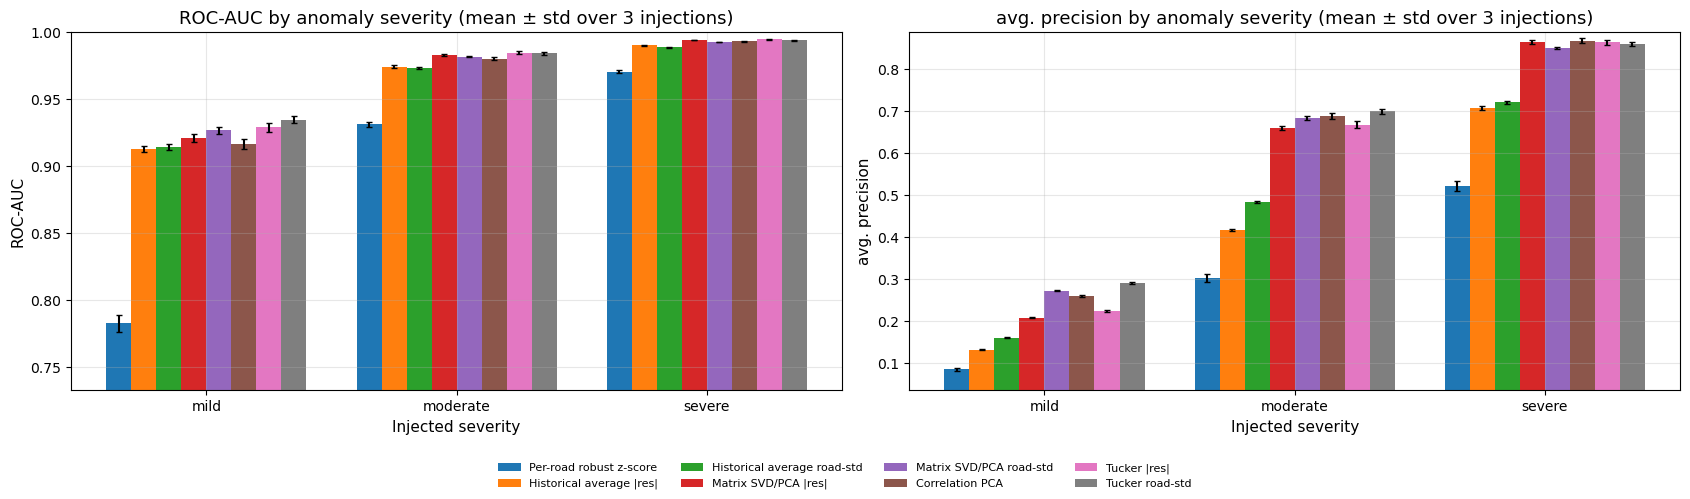

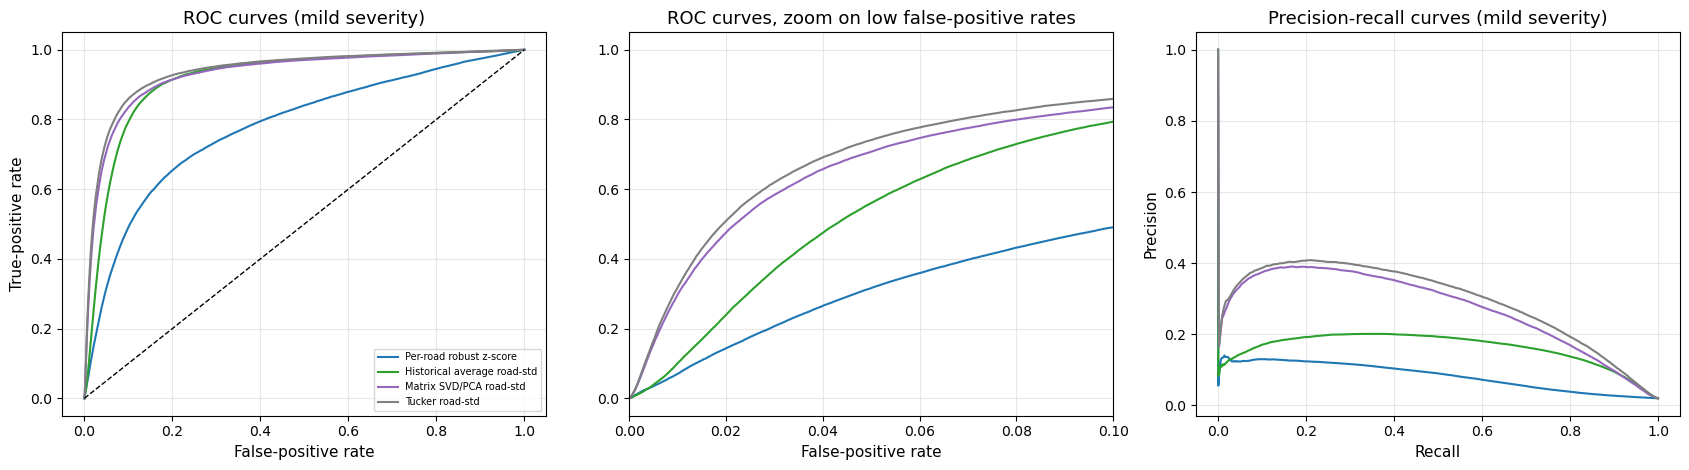

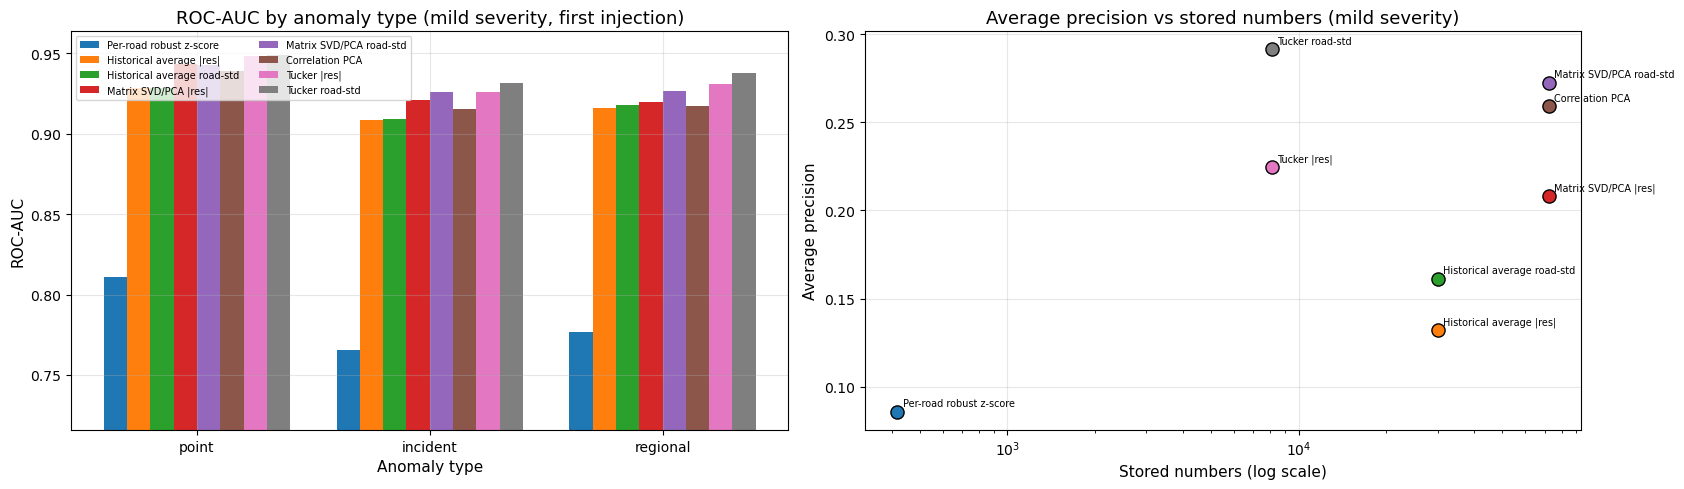

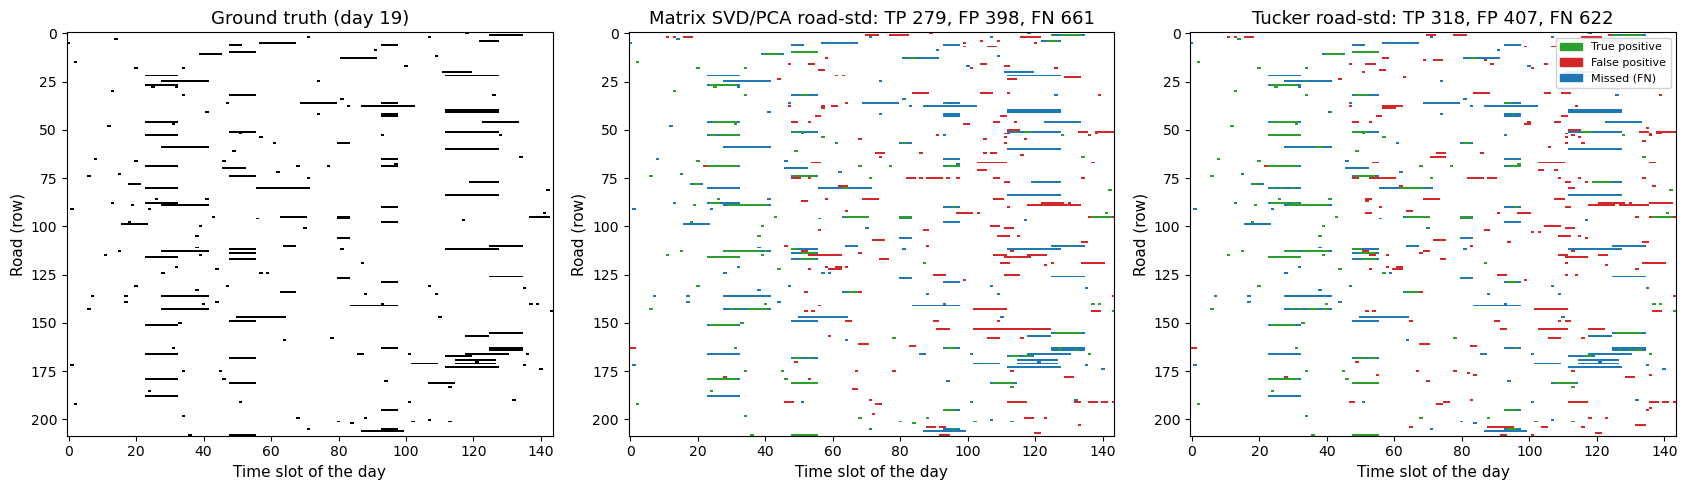


Section 14 complete. Variables available for the final summary:
  results_df, summary_tables, rank_table, paired_table, type_table, complexity_table
  (full results saved to outputs\14_results_long.csv)


In [18]:
# ============================================================
# SECTION 14: PERFORMANCE COMPARISON
# Requires: Sections 1-13
#   (X, X_imputed_mask, eval_mask, m, n, n_times_clean, TENSOR_SHAPE, K_SELECTED,
#    TUCKER_RANKS, ANOMALY_RATE, RANDOM_STATE, SEVERITY, TYPE_NAMES,
#    inject_anomalies, fit_tucker, tucker_reconstruct, tucker_n_params,
#    pca_scores_table, tucker_scores_table)
# Output: results_df, summary tables, paired_table, type_table, complexity_table
# ============================================================
import time

for _name in ["X", "X_imputed_mask", "eval_mask", "m", "n", "n_times_clean", "TENSOR_SHAPE",
              "K_SELECTED", "TUCKER_RANKS", "ANOMALY_RATE", "RANDOM_STATE", "SEVERITY",
              "TYPE_NAMES", "inject_anomalies", "fit_tucker", "tucker_reconstruct",
              "tucker_n_params", "pca_scores_table", "tucker_scores_table"]:
    if _name not in globals():
        raise NameError(f"'{_name}' is missing. Please run Sections 1-13 first.")

from sklearn.metrics import average_precision_score, precision_recall_curve

# ------------------------------------------------------------
# 0. Experiment settings
#    All model settings are FIXED beforehand (k from Section 9, Tucker ranks from Section 13),
#    so no method is tuned on the labels of the injected anomalies.
# ------------------------------------------------------------
SEVERITIES = ["mild", "moderate", "severe"]
SEEDS = [RANDOM_STATE, RANDOM_STATE + 1, RANDOM_STATE + 2]     # 3 independent injections per severity
T_, D_ = n_times_clean, n // n_times_clean
CURVE_SEVERITY = "mild"                                          # hardest setting, used for the curves/maps

METHODS = [
    "Per-road robust z-score",
    "Historical average |res|",
    "Historical average road-std",
    "Matrix SVD/PCA |res|",
    "Matrix SVD/PCA road-std",
    "Correlation PCA",
    "Tucker |res|",
    "Tucker road-std",
]

# ------------------------------------------------------------
# 1. The detectors: every one returns a residual / score matrix of shape (m, n)
# ------------------------------------------------------------
def road_standardise(res):
    """|res - road median| / robust sigma of that road (MAD)."""
    med = np.median(res, axis=1, keepdims=True)
    sig = 1.4826 * np.median(np.abs(res - med), axis=1, keepdims=True)
    return np.abs(res - med) / sig

def residual_zscore_base(Xa):                                   # baseline 1: how far from the road's typical speed
    med = np.median(Xa, axis=1, keepdims=True)
    return Xa - med

def residual_hist_avg(Xa):                                      # baseline 2: road x time-of-day median profile
    X3 = Xa.reshape(m, D_, T_)
    return (X3 - np.median(X3, axis=1, keepdims=True)).reshape(m, n)

def residual_lowrank(Xa, k=K_SELECTED):                         # matrix rank-k model (SVD = PCA)
    Xc_ = Xa - Xa.mean(axis=1, keepdims=True)
    U_, S_, Vt_ = sla.svd(Xc_, full_matrices=False)
    return Xc_ - (U_[:, :k] * S_[:k]) @ Vt_[:k]

def residual_corr_pca(Xa, k=K_SELECTED):                        # PCA of the standardised roads
    Zs = (Xa - Xa.mean(axis=1, keepdims=True)) / Xa.std(axis=1, keepdims=True)
    U_, S_, Vt_ = sla.svd(Zs, full_matrices=False)
    return Zs - (U_[:, :k] * S_[:k]) @ Vt_[:k]

def residual_tucker(Xa):                                        # Tucker model with the Section 13 ranks
    ten = (Xa - Xa.mean(axis=1, keepdims=True)).reshape(TENSOR_SHAPE)
    core_, fac_ = fit_tucker(ten, TUCKER_RANKS)
    return np.asarray(ten - tucker_reconstruct(core_, fac_)).reshape(m, n)

def all_scores(Xa):
    """Return {method: (score matrix, seconds)} for one contaminated matrix."""
    out = {}
    def timed(name, fn):
        t0 = time.perf_counter(); s = fn(); out[name] = (s, time.perf_counter() - t0)
    timed("Per-road robust z-score",   lambda: road_standardise(residual_zscore_base(Xa)))
    r_ha = None
    t0 = time.perf_counter(); r_ha = residual_hist_avg(Xa); t_ha = time.perf_counter() - t0
    out["Historical average |res|"] = (np.abs(r_ha), t_ha)
    out["Historical average road-std"] = (road_standardise(r_ha), t_ha)
    t0 = time.perf_counter(); r_lr = residual_lowrank(Xa); t_lr = time.perf_counter() - t0
    out["Matrix SVD/PCA |res|"] = (np.abs(r_lr), t_lr)
    out["Matrix SVD/PCA road-std"] = (road_standardise(r_lr), t_lr)
    timed("Correlation PCA",           lambda: np.abs(residual_corr_pca(Xa)))
    t0 = time.perf_counter(); r_tk = residual_tucker(Xa); t_tk = time.perf_counter() - t0
    out["Tucker |res|"] = (np.abs(r_tk), t_tk)
    out["Tucker road-std"] = (road_standardise(r_tk), t_tk)
    return out

# ------------------------------------------------------------
# 2. Metrics (all computed on observed cells only)
# ------------------------------------------------------------
def metrics(score, lab):
    s, y = score[eval_mask], lab[eval_mask]
    neg = s[~y]
    tpr_1pct = float(np.mean(s[y] > np.quantile(neg, 0.99)))           # recall at 1% false-positive rate
    pred = s >= np.quantile(s, 1 - ANOMALY_RATE)                       # flag the top 2% (assumed contamination)
    tp = float(np.sum(pred & y))
    prec, rec = tp / pred.sum(), tp / y.sum()
    return {"ROC-AUC": roc_auc_score(y, s), "avg. precision": average_precision_score(y, s),
            "TPR@1%FPR": tpr_1pct, "precision@top2%": prec, "recall@top2%": rec,
            "F1@top2%": 2 * prec * rec / (prec + rec)}

# ------------------------------------------------------------
# 3. Run the experiment: severities x seeds x methods
# ------------------------------------------------------------
records, type_records, timing = [], [], {k: [] for k in METHODS}
curve_scores, curve_labels = {}, {}
CURVE_KEEP = ["Per-road robust z-score", "Historical average road-std",
              "Matrix SVD/PCA road-std", "Tucker road-std"]
t_start = time.perf_counter()
for sev in SEVERITIES:
    for seed in SEEDS:
        Xa, lab, aty, _ = inject_anomalies(X, severity=sev, seed=seed, forbidden=X_imputed_mask)
        scores = all_scores(Xa)
        for name in METHODS:
            sc_, secs = scores[name]
            rec_ = metrics(sc_, lab)
            rec_.update({"severity": sev, "seed": seed, "method": name})
            records.append(rec_)
            timing[name].append(secs)
            if seed == SEEDS[0]:                                        # per-type AUC on the first seed only
                for t, tname in TYPE_NAMES.items():
                    sel = eval_mask & ((aty == t) | ~lab)
                    type_records.append({"severity": sev, "method": name, "type": tname,
                                         "ROC-AUC": roc_auc_score(aty[sel] == t, sc_[sel])})
        if sev == CURVE_SEVERITY and seed == SEEDS[0]:
            curve_scores = {k: scores[k][0].astype(np.float32) for k in CURVE_KEEP}
            curve_labels = {"lab": lab.copy(), "aty": aty.copy()}
        del Xa, scores
        print(f"  finished {sev:<8} seed {seed}   (elapsed {time.perf_counter() - t_start:5.0f} s)")

results_df = pd.DataFrame(records)
type_df = pd.DataFrame(type_records)

# ------------------------------------------------------------
# 4. Cross-check against Sections 11 and 13 (same injection, moderate, seed = RANDOM_STATE)
# ------------------------------------------------------------
ref = results_df[(results_df.severity == "moderate") & (results_df.seed == RANDOM_STATE)].set_index("method")
print("\n--- Consistency with earlier sections (moderate, first seed) ---")
print(f"Matrix SVD/PCA |res| ROC-AUC : {ref.loc['Matrix SVD/PCA |res|', 'ROC-AUC']:.4f}   "
      f"(Section 11: {pca_scores_table.loc['PCA |residual|', 'ROC-AUC']:.4f})")
print(f"Tucker |res|        ROC-AUC : {ref.loc['Tucker |res|', 'ROC-AUC']:.4f}   "
      f"(Section 13: {tucker_scores_table.loc['Tucker |residual|', 'ROC-AUC']:.4f})")
assert abs(ref.loc['Matrix SVD/PCA |res|', 'ROC-AUC'] - pca_scores_table.loc['PCA |residual|', 'ROC-AUC']) < 1e-6
assert abs(ref.loc['Tucker |res|', 'ROC-AUC'] - tucker_scores_table.loc['Tucker |residual|', 'ROC-AUC']) < 1e-3

# ------------------------------------------------------------
# 5. Summary tables: mean +- std over the seeds
# ------------------------------------------------------------
def pm_table(metric):
    g = results_df.groupby(["method", "severity"])[metric].agg(["mean", "std"]).reset_index()
    g["txt"] = g.apply(lambda r: f"{r['mean']:.4f} ± {r['std']:.4f}", axis=1)
    return g.pivot(index="method", columns="severity", values="txt").loc[METHODS, SEVERITIES]

summary_tables = {}
for metric in ["ROC-AUC", "avg. precision", "TPR@1%FPR", "F1@top2%"]:
    summary_tables[metric] = pm_table(metric)
    print(f"\n--- {metric} (mean ± std over {len(SEEDS)} injections) ---")
    display(summary_tables[metric])

# Average rank of each method (1 = best) across severities
rank_rows = {}
for metric in ["ROC-AUC", "avg. precision"]:
    mean_ = results_df.groupby(["severity", "method"])[metric].mean().unstack("method")[METHODS]
    rank_rows[metric] = mean_.rank(axis=1, ascending=False).mean(axis=0)
rank_table = pd.DataFrame(rank_rows).sort_values("avg. precision")
print("\n--- Average rank over the 3 severities (1 = best) ---")
display(rank_table)

# ------------------------------------------------------------
# 6. Paired comparison: Tucker vs matrix SVD/PCA on the SAME injections
# ------------------------------------------------------------
pairs = [("Tucker |res|", "Matrix SVD/PCA |res|"), ("Tucker road-std", "Matrix SVD/PCA road-std")]
rows = []
for a, b in pairs:
    for sev in SEVERITIES:
        for metric in ["ROC-AUC", "avg. precision"]:
            va = results_df[(results_df.method == a) & (results_df.severity == sev)].sort_values("seed")[metric].to_numpy()
            vb = results_df[(results_df.method == b) & (results_df.severity == sev)].sort_values("seed")[metric].to_numpy()
            d = va - vb
            rows.append({"comparison": f"{a}  minus  {b}", "severity": sev, "metric": metric,
                         "mean difference": d.mean(), "min difference": d.min(),
                         "Tucker better in": f"{int(np.sum(d > 0))}/{len(d)} injections"})
paired_table = pd.DataFrame(rows)
print("\n--- Paired differences (positive = Tucker better) ---")
display(paired_table)

# ------------------------------------------------------------
# 7. Detection quality by anomaly type (first injection of each severity)
# ------------------------------------------------------------
type_table = type_df.pivot_table(index=["severity", "method"], columns="type", values="ROC-AUC").loc[
    [(s_, mth) for s_ in SEVERITIES for mth in METHODS], ["point", "incident", "regional"]]
print("\n--- ROC-AUC by anomaly type (first injection) ---")
display(type_table)

# ------------------------------------------------------------
# 8. Model complexity and cost
# ------------------------------------------------------------
stored = {
    "Per-road robust z-score": 2 * m,
    "Historical average |res|": m * T_,
    "Historical average road-std": m * T_,
    "Matrix SVD/PCA |res|": K_SELECTED * (m + n + 1) + m,
    "Matrix SVD/PCA road-std": K_SELECTED * (m + n + 1) + m,
    "Correlation PCA": K_SELECTED * (m + n + 1) + 2 * m,
    "Tucker |res|": tucker_n_params(TUCKER_RANKS) + m,
    "Tucker road-std": tucker_n_params(TUCKER_RANKS) + m,
}
complexity_table = pd.DataFrame({
    "stored numbers": pd.Series(stored),
    "mean run time (s)": pd.Series({k: np.mean(v) for k, v in timing.items()}),
    "AP (mild)": results_df[results_df.severity == "mild"].groupby("method")["avg. precision"].mean(),
    "ROC-AUC (mild)": results_df[results_df.severity == "mild"].groupby("method")["ROC-AUC"].mean(),
}).loc[METHODS]
complexity_table["stored numbers"] = complexity_table["stored numbers"].astype(int)
print("\n--- Model size, run time and mild-severity accuracy ---")
display(complexity_table)

# ------------------------------------------------------------
# 9. Visualizations
# ------------------------------------------------------------
palette = plt.cm.tab10(np.linspace(0, 1, 10))[: len(METHODS)]

# --- Figure 1: accuracy across severities (mean +- std) ------------------
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
width = 0.1
for ax, metric in zip(axes, ["ROC-AUC", "avg. precision"]):
    agg = results_df.groupby(["method", "severity"])[metric].agg(["mean", "std"])
    for i, name in enumerate(METHODS):
        means = [agg.loc[(name, s_), "mean"] for s_ in SEVERITIES]
        stds = [agg.loc[(name, s_), "std"] for s_ in SEVERITIES]
        ax.bar(np.arange(len(SEVERITIES)) + (i - len(METHODS) / 2 + 0.5) * width, means, width,
               yerr=stds, color=palette[i], label=name, capsize=2)
    lo = results_df.groupby(["method", "severity"])[metric].mean().min()
    ax.set_ylim(max(0.0, lo - 0.05), min(1.0, results_df[metric].max() + 0.015))
    ax.set_xticks(np.arange(len(SEVERITIES))); ax.set_xticklabels(SEVERITIES)
    ax.set_title(f"{metric} by anomaly severity (mean ± std over {len(SEEDS)} injections)")
    ax.set_xlabel("Injected severity"); ax.set_ylabel(metric)
handles_, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles_, labels_, loc="lower center", ncol=4, fontsize=8, frameon=False)
plt.tight_layout(rect=[0, 0.09, 1, 1])
plt.savefig(os.path.join(OUTPUT_DIR, "14_comparison_bars.png"), dpi=150)
plt.show()

# --- Figure 2: ROC / zoomed ROC / PR for the hardest setting --------------
y_c = curve_labels["lab"][eval_mask]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
cmap_c = {k: palette[METHODS.index(k)] for k in CURVE_KEEP}
for name in CURVE_KEEP:
    s = curve_scores[name][eval_mask]
    fpr, tpr, _ = roc_curve(y_c, s)
    keep = np.unique(np.linspace(0, len(fpr) - 1, 4000).astype(int))
    axes[0].plot(fpr[keep], tpr[keep], color=cmap_c[name], label=name)
    axes[1].plot(fpr[keep], tpr[keep], color=cmap_c[name], label=name)
    prec, rec, _ = precision_recall_curve(y_c, s)
    keep = np.unique(np.linspace(0, len(prec) - 1, 4000).astype(int))
    axes[2].plot(rec[keep], prec[keep], color=cmap_c[name], label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title(f"ROC curves ({CURVE_SEVERITY} severity)"); axes[0].set_xlabel("False-positive rate"); axes[0].set_ylabel("True-positive rate")
axes[1].set_xlim(0, 0.1); axes[1].set_title("ROC curves, zoom on low false-positive rates"); axes[1].set_xlabel("False-positive rate")
axes[2].set_title(f"Precision-recall curves ({CURVE_SEVERITY} severity)"); axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision")
axes[0].legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "14_comparison_curves.png"), dpi=150)
plt.show()

# --- Figure 3: by anomaly type, and accuracy vs model size -----------------
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
sub = type_df[type_df.severity == CURVE_SEVERITY].pivot(index="method", columns="type", values="ROC-AUC").loc[METHODS, ["point", "incident", "regional"]]
for i, name in enumerate(METHODS):
    axes[0].bar(np.arange(3) + (i - len(METHODS) / 2 + 0.5) * width, sub.loc[name].values, width, color=palette[i], label=name)
axes[0].set_xticks(np.arange(3)); axes[0].set_xticklabels(["point", "incident", "regional"])
axes[0].set_ylim(max(0.0, sub.values.min() - 0.05), min(1.0, sub.values.max() + 0.015))
axes[0].set_title(f"ROC-AUC by anomaly type ({CURVE_SEVERITY} severity, first injection)")
axes[0].set_xlabel("Anomaly type"); axes[0].set_ylabel("ROC-AUC"); axes[0].legend(fontsize=7, loc="upper left", ncol=2)

for i, name in enumerate(METHODS):
    axes[1].scatter(complexity_table.loc[name, "stored numbers"], complexity_table.loc[name, "AP (mild)"],
                    s=90, color=palette[i], edgecolor="black", zorder=3)
    axes[1].annotate(name, (complexity_table.loc[name, "stored numbers"], complexity_table.loc[name, "AP (mild)"]),
                     fontsize=7, xytext=(4, 4), textcoords="offset points")
axes[1].set_xscale("log")
axes[1].set_title(f"Average precision vs stored numbers ({CURVE_SEVERITY} severity)")
axes[1].set_xlabel("Stored numbers (log scale)"); axes[1].set_ylabel("Average precision")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "14_comparison_type_complexity.png"), dpi=150)
plt.show()

# --- Figure 4: detection maps for one day (mild severity, first injection) -
lab_c, aty_c = curve_labels["lab"], curve_labels["aty"]
d_star = int(np.argmax(lab_c.reshape(m, D_, T_).sum(axis=(0, 2))))
win = slice(d_star * T_, (d_star + 1) * T_)
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
cm4 = ListedColormap(["white", "tab:green", "tab:red", "tab:blue"])      # 0 none, 1 TP, 2 FP, 3 FN
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].imshow(lab_c[:, win], aspect="auto", cmap=ListedColormap(["white", "black"]), interpolation="nearest")
axes[0].set_title(f"Ground truth (day {d_star + 1})")
for ax, name in zip(axes[1:], ["Matrix SVD/PCA road-std", "Tucker road-std"]):
    s_all = curve_scores[name]
    thr = np.quantile(s_all[eval_mask], 1 - ANOMALY_RATE)
    pred = (s_all >= thr) & eval_mask
    code = np.zeros(lab_c.shape, dtype=int)
    code[pred & lab_c] = 1; code[pred & ~lab_c] = 2; code[~pred & lab_c] = 3
    ax.imshow(code[:, win], aspect="auto", cmap=cm4, vmin=0, vmax=3, interpolation="nearest")
    tp, fp, fn = int(np.sum(code[:, win] == 1)), int(np.sum(code[:, win] == 2)), int(np.sum(code[:, win] == 3))
    ax.set_title(f"{name}: TP {tp}, FP {fp}, FN {fn}")
for ax in axes:
    ax.set_xlabel("Time slot of the day"); ax.set_ylabel("Road (row)"); ax.grid(False)
axes[2].legend(handles=[Patch(color="tab:green", label="True positive"), Patch(color="tab:red", label="False positive"),
                        Patch(color="tab:blue", label="Missed (FN)")], loc="upper right", fontsize=8, framealpha=0.9)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "14_comparison_detection_maps.png"), dpi=150)
plt.show()

results_df.to_csv(os.path.join(OUTPUT_DIR, "14_results_long.csv"), index=False)
print("\nSection 14 complete. Variables available for the final summary:")
print("  results_df, summary_tables, rank_table, paired_table, type_table, complexity_table")
print(f"  (full results saved to {os.path.join(OUTPUT_DIR, '14_results_long.csv')})")

RESULTS LEDGER (all values computed in Sections 2-14)


,stage,quantity,value
0,2-4 Data,Raw observations,"1,855,589 rows"
1,2-4 Data,Roads x days x time slots (raw),214 x 61 x 144
2,2-4 Data,Absent grid cells,"24,187 (1.29%)"
3,2-4 Data,Roads dropped (> 20% missing),"5: [48, 55, 123, 146, 147]"
4,2-4 Data,Cells imputed on kept roads,427 (0.0233%)
5,5 Matrix,Matrix X (roads x day-time slots),"209 x 8,784"
6,5 Matrix,Frobenius norm ||X||_F,"54,971.08"
7,6 Rank,Numerical rank of X,209 (maximum possible 209)
8,6 Rank,sigma_1 energy share (raw X / centred Xc),97.98% / 64.96%
9,6 Rank,Components for 90% / 95% / 99% energy (centred),55 / 102 / 174



LINEAR-ALGEBRA CONCEPTS AND EVIDENCE


,concept,sections,evidence from this project
0,Matrix representation,5,"X is 209 x 8,784: rows = roads, columns = (day, time) slots"
1,Matrix rank,6,"full numerical rank 209, but 102 components for 95% energy (centred)"
2,SVD,7,U S V^T reproduces Xc to 2e-15; mode 1 = network-wide speed level
3,Low-rank approximation (Eckart-Young),8,rank 8 keeps 78.0% of the energy; error = sqrt(sum of discarded sigma^2)
4,Frobenius norm,"5, 6, 8, 9, 12, 13",relative error ||Xc - X_hat||_F / ||Xc||_F = 0.469 at rank 8
5,Perturbation (Weyl),10,max singular-value shift 115 <= ||E||_2 = 674
6,PCA,11,identical to the SVD (largest gap 2e-12); adds SPE / T^2 monitoring
7,"Tensor, unfolding, mode-n product",12,"tensor (209, 61, 144); mode-1 unfolding equals X; (T x_n A)_(n) = A T_(n) verified"
8,Tucker / HOSVD / HOOI,13,"ranks (16, 14, 10): 9.1x fewer stored numbers than the matrix model"



KEY FINDINGS
1. Traffic speed is approximately, not exactly, low rank. After removing road means, one singular value carries 65.0% of the energy, yet 102 of 209 components are needed for 95% and the matrix is numerically full rank (209). 

2. The rank should be chosen by held-out validation, not by the elbow. Held-out RMSE fell from 8.34 (k = 0) to 4.26 at k = 8 and rose to 6.81 at k = 80, while the elbow rule suggested k = 43. 

3. PCA and the SVD are the same computation: all equivalence checks agree to 2e-12. PCA adds monitoring statistics, but the residuals are heavy-tailed (excess kurtosis 7.6), so Gaussian control limits over-alarm (25.5% of slots above the SPE limit against a nominal 1%). 

4. Low-rank structure adds real detection power over simple baselines: the weakest low-rank variant exceeds the strongest baseline in average precision at every severity (smallest margin 0.047). 

5. The tensor (Tucker) model is better than the matrix model in a consistent but modest way: it

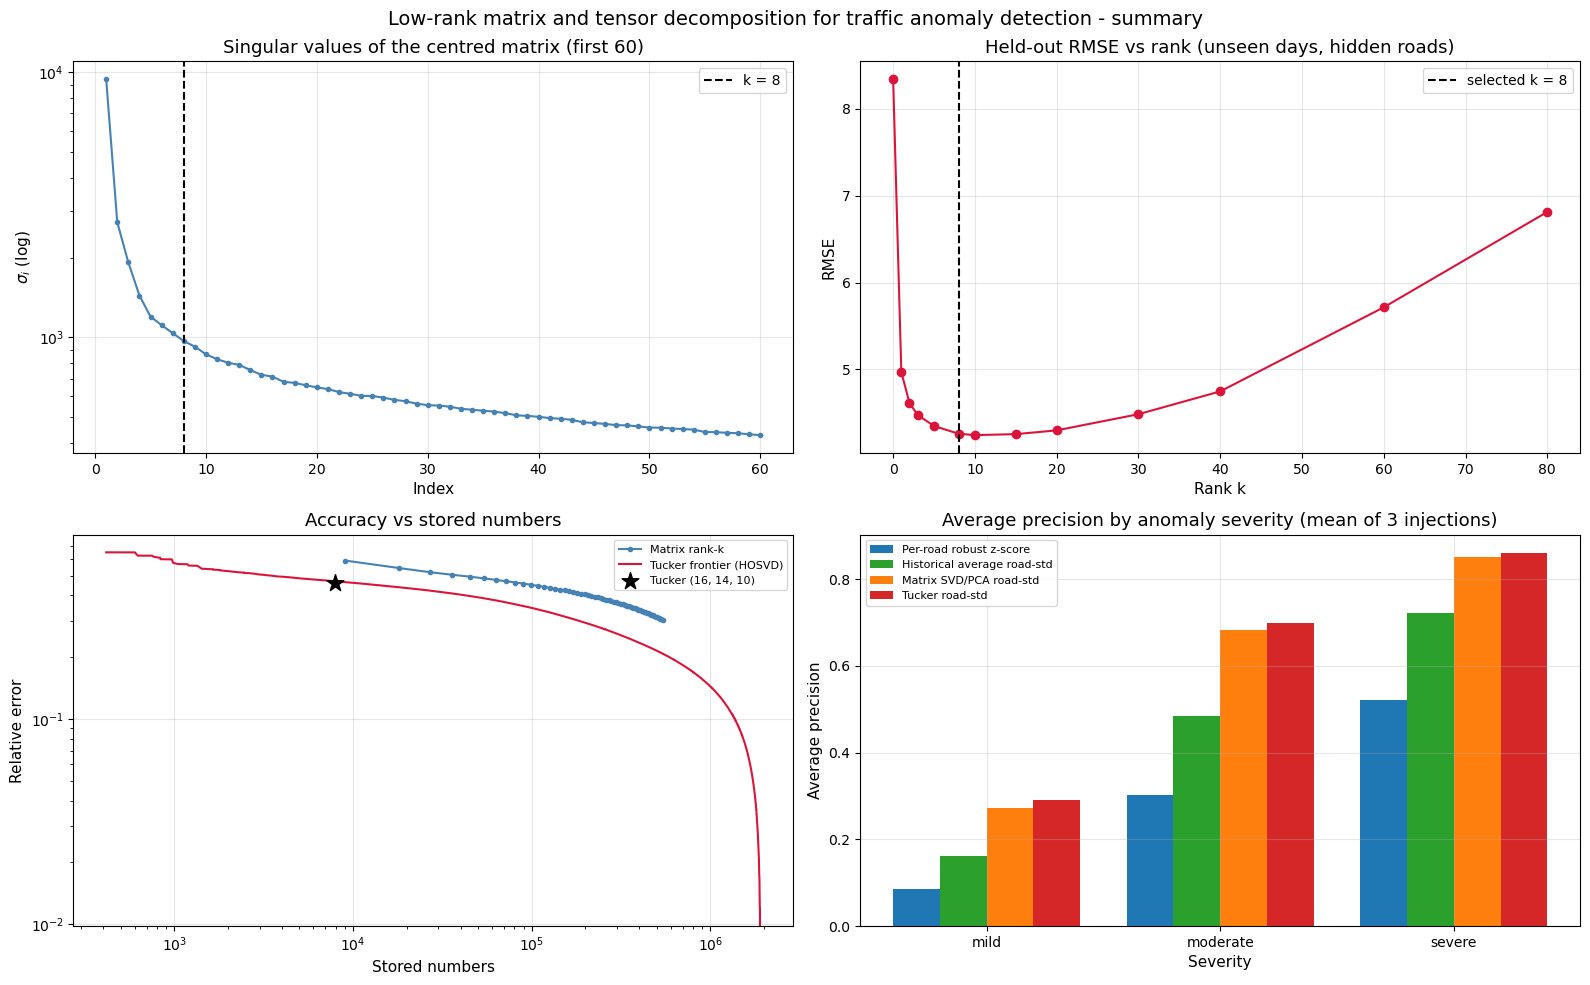


Files in the output folder:
  02_speed_distribution_raw.png                     41.4 KB
  03_absent_cells.png                               78.3 KB
  03_speed_overview.png                            198.1 KB
  04_cleaning_overview.png                          78.7 KB
  04_imputation_example.png                        143.2 KB
  05_matrix_heatmap_full.png                       907.1 KB
  05_matrix_heatmap_zoom.png                       348.1 KB
  05_matrix_rows_columns.png                       258.7 KB
  06_rank_analysis.png                             138.7 KB
  06_rank_vs_tolerance.png                          45.9 KB
  07_svd_left_vectors.png                          143.7 KB
  07_svd_right_vectors.png                         364.7 KB
  08_lowrank_error_curves.png                      108.2 KB
  08_lowrank_heatmaps.png                         1407.9 KB
  08_lowrank_road_series.png                       313.1 KB
  09_choose_k_and_residuals.png                    123.4 KB
  09_error_

In [19]:
# ============================================================
# SECTION 15: FINAL SUMMARY
# Requires: Sections 1-14. Every number below is read from variables computed earlier;
# nothing is typed in by hand.
# Output: ledger_df, concept_df, findings (text), final files in OUTPUT_DIR
# ============================================================
import json

_required = ["X", "Sc", "K_SELECTED", "TUCKER_RANKS", "results_df", "paired_table",
             "complexity_table", "cv_table", "rank_summary", "dist_table", "events_df",
             "Y_true", "fit_table", "pca_scores_table", "multilinear_table", "SEVERITIES"]
_missing = [v for v in _required if v not in globals()]
if _missing:
    raise NameError(f"Missing variables {_missing}. Please run Sections 1-14 first.")

def G(name, default=np.nan):
    """Fetch an earlier variable (or NaN if it does not exist)."""
    return globals().get(name, default)

def rs(prefix, col):
    """Value from rank_summary (Section 6) whose row label starts with 'prefix'."""
    label = next(i for i in rank_summary.index if i.startswith(prefix))
    return rank_summary.loc[label, col]

ledger = []
def add(stage, quantity, value):
    ledger.append({"stage": stage, "quantity": quantity, "value": value})

K = K_SELECTED
r_full = len(Sc)
cmat = "Xc (row-centred)"

# ------------------------------------------------------------
# 1. Results ledger (one row per headline quantity)
# ------------------------------------------------------------
# --- Data, cleaning, matrix ---------------------------------------------
add("2-4 Data", "Raw observations", f"{len(df):,} rows")
add("2-4 Data", "Roads x days x time slots (raw)", f"{n_roads} x {n_days} x {n_times}")
add("2-4 Data", "Absent grid cells", f"{n_absent:,} ({n_absent / (n_roads * n_days * n_times):.2%})")
add("2-4 Data", f"Roads dropped (> {MAX_ROAD_MISSING_FRAC:.0%} missing)", f"{len(roads_dropped)}: {roads_dropped.tolist()}")
add("2-4 Data", "Cells imputed on kept roads", f"{int(imputed_mask_3d.sum()):,} ({imputed_mask_3d.mean():.4%})")
add("5 Matrix", "Matrix X (roads x day-time slots)", f"{X.shape[0]} x {X.shape[1]:,}")
add("5 Matrix", "Frobenius norm ||X||_F", f"{fro_X:,.2f}")

# --- Rank and SVD ---------------------------------------------------------
add("6 Rank", "Numerical rank of X", f"{rank_default} (maximum possible {min(X.shape)})")
add("6 Rank", "sigma_1 energy share (raw X / centred Xc)", f"{rs('sigma_1', 'X (raw)'):.2%} / {rs('sigma_1', cmat):.2%}")
add("6 Rank", "Components for 90% / 95% / 99% energy (centred)",
    f"{int(rs('k for 90%', cmat))} / {int(rs('k for 95%', cmat))} / {int(rs('k for 99%', cmat))}")
add("6 Rank", "Stable rank (centred)", f"{rs('stable rank', cmat):.2f}")
add("7 SVD", "Relative reconstruction error U S V^T vs Xc", f"{G('checks').loc['relative reconstruction error', cmat]:.1e}")
add("7 SVD", "Max gap between eig(Xc Xc^T) and sigma^2", f"{G('rel_gap'):.1e}")
add("7 SVD", "Corr(u1 of X, road mean) / Corr(v1 of Xc, network deviation)", f"{G('corr_u1_mean'):.4f} / {G('corr_v1_net'):.4f}")

# --- Low-rank approximation and error analysis ----------------------------
add("8 Low rank", f"Energy retained by rank {K}", f"{cum_Xc[K - 1]:.2%}")
add("8 Low rank", f"Relative error vs ||Xc||_F at rank {K}", f"{rel_err_curve[K - 1]:.4f}")
add("8 Low rank", f"Storage compression at rank {K}", f"{(m * n) / (K * (m + n + 1) + m):.1f}x")
add("9 Error", "Rank by elbow rule / best held-out / selected",
    f"{G('k_elbow')} / {G('best_k')} / {K}")
add("9 Error", "Held-out RMSE: k=0 -> selected k -> largest k tested",
    f"{cv_table['held-out RMSE'].iloc[0]:.2f} -> {cv_table.loc[K, 'held-out RMSE']:.2f} -> "
    f"{cv_table['held-out RMSE'].iloc[-1]:.2f} (k={cv_table.index[-1]})")
add("9 Error", f"In-sample RMSE / MAE at rank {K}", f"{G('overall_rmse'):.3f} / {G('overall_mae'):.3f}")
add("9 Error", "Residual excess kurtosis / share beyond 3 robust sigma",
    f"{dist_table.loc['excess kurtosis', 'value']:.2f} / {dist_table.loc['share beyond 3 robust sigma', 'value']:.2%}")
add("9 Error", "Median road R^2 (variance explained)", f"{G('road_table')['R^2 (variance explained)'].median():.3f}")

# --- Injection and PCA ----------------------------------------------------
n_by_type = events_df.groupby("type").size().to_dict()
add("10 Injection", "Injected anomalous cells", f"{int(Y_true.sum()):,} ({Y_true.mean():.3%})")
add("10 Injection", "Events (point / incident / regional)",
    f"{n_by_type.get('point', 0):,} / {n_by_type.get('incident', 0):,} / {n_by_type.get('regional', 0):,}")
add("10 Injection", "Weyl: max |sigma shift| vs ||E||_2",
    f"{G('max_shift'):,.1f} <= {G('spec_E'):,.1f}  ({G('max_shift') <= G('spec_E') + 1e-9})")
add("11 PCA", "Largest gap in all PCA-vs-SVD equivalence checks", f"{G('equiv').max():.1e}")
add("11 PCA", "Slots above SPE limit / T^2 limit (nominal 1%)",
    f"{np.mean(G('spe') > G('Q_limit')):.1%} / {np.mean(G('t2') > G('T2_limit')):.1%}")
add("11 PCA", "Top-SPE slots whose biggest contributor is an injected cell", f"{G('hit_rate'):.0%}")

# --- Tensor, Tucker -------------------------------------------------------
add("12 Tensor", "Tensor shape (roads, days, times)", f"{TENSOR_SHAPE}")
add("12 Tensor", "Components for 95% energy per mode (roads, days, times)",
    f"{', '.join(str(int(v)) for v in multilinear_table['k for 95% energy'])}")
tk_params, mx_params = tucker_n_params(TUCKER_RANKS), K * (m + n + 1)
add("13 Tucker", "Selected multilinear ranks", f"{TUCKER_RANKS}")
add("13 Tucker", "Stored numbers: Tucker vs matrix", f"{tk_params:,} vs {mx_params:,}  ({mx_params / tk_params:.1f}x fewer)")
add("13 Tucker", "Relative error: matrix vs Tucker (HOOI)",
    f"{fit_table.iloc[0]['rel. error vs Xc']:.4f} vs {fit_table.iloc[2]['rel. error vs Xc']:.4f}")

# --- Comparison -------------------------------------------------------------
means = results_df.groupby(["severity", "method"])[["ROC-AUC", "avg. precision", "F1@top2%"]].mean()
for sev in SEVERITIES:
    for metric in ["ROC-AUC", "avg. precision"]:
        best = means.loc[sev, metric].idxmax()
        add("14 Comparison", f"Best {metric} at {sev} severity", f"{best} ({means.loc[(sev, best), metric]:.4f})")

ledger_df = pd.DataFrame(ledger)
print("=" * 78)
print("RESULTS LEDGER (all values computed in Sections 2-14)")
print("=" * 78)
with pd.option_context("display.max_rows", None, "display.max_colwidth", 110, "display.width", 200):
    display(ledger_df)

# ------------------------------------------------------------
# 2. Where each linear-algebra concept was used
# ------------------------------------------------------------
concept_df = pd.DataFrame([
    ("Matrix representation", "5", f"X is {m} x {n:,}: rows = roads, columns = (day, time) slots"),
    ("Matrix rank", "6", f"full numerical rank {rank_default}, but {int(rs('k for 95%', cmat))} components for 95% energy (centred)"),
    ("SVD", "7", f"U S V^T reproduces Xc to {G('checks').loc['relative reconstruction error', cmat]:.0e}; mode 1 = network-wide speed level"),
    ("Low-rank approximation (Eckart-Young)", "8", f"rank {K} keeps {cum_Xc[K - 1]:.1%} of the energy; error = sqrt(sum of discarded sigma^2)"),
    ("Frobenius norm", "5, 6, 8, 9, 12, 13", f"relative error ||Xc - X_hat||_F / ||Xc||_F = {rel_err_curve[K - 1]:.3f} at rank {K}"),
    ("Perturbation (Weyl)", "10", f"max singular-value shift {G('max_shift'):,.0f} <= ||E||_2 = {G('spec_E'):,.0f}"),
    ("PCA", "11", f"identical to the SVD (largest gap {G('equiv').max():.0e}); adds SPE / T^2 monitoring"),
    ("Tensor, unfolding, mode-n product", "12", f"tensor {TENSOR_SHAPE}; mode-1 unfolding equals X; (T x_n A)_(n) = A T_(n) verified"),
    ("Tucker / HOSVD / HOOI", "13", f"ranks {TUCKER_RANKS}: {mx_params / tk_params:.1f}x fewer stored numbers than the matrix model"),
], columns=["concept", "sections", "evidence from this project"])
print("\n" + "=" * 78)
print("LINEAR-ALGEBRA CONCEPTS AND EVIDENCE")
print("=" * 78)
with pd.option_context("display.max_colwidth", 130, "display.width", 220):
    display(concept_df)

# ------------------------------------------------------------
# 3. Key findings (sentences are generated from the numbers above)
# ------------------------------------------------------------
lowrank_methods = ["Matrix SVD/PCA |res|", "Matrix SVD/PCA road-std", "Correlation PCA", "Tucker |res|", "Tucker road-std"]
baseline_methods = ["Per-road robust z-score", "Historical average |res|", "Historical average road-std"]
ap_margin = min(means.loc[(sev, lowrank_methods), "avg. precision"].min() - means.loc[(sev, baseline_methods), "avg. precision"].max()
                for sev in SEVERITIES)

all_wins = [str(s).split()[0].split("/")[0] == str(s).split()[0].split("/")[1] for s in paired_table["Tucker better in"]]
_exc = paired_table[~pd.Series(all_wins, index=paired_table.index)]
exceptions_txt = "" if _exc.empty else "; exception(s): " + "; ".join(
    f"{r_['comparison'].split('  minus  ')[0]} vs matrix, {r_['metric']}, {r_['severity']} ({r_['Tucker better in']})"
    for _, r_ in _exc.iterrows())
mild_pairs = paired_table[(paired_table.severity == "mild") & (paired_table.comparison.str.contains("road-std"))]
d_auc = mild_pairs[mild_pairs.metric == "ROC-AUC"]["mean difference"].iloc[0]
d_ap = mild_pairs[mild_pairs.metric == "avg. precision"]["mean difference"].iloc[0]
t_tk = complexity_table.loc["Tucker road-std", "mean run time (s)"]
t_mx = complexity_table.loc["Matrix SVD/PCA road-std", "mean run time (s)"]
best_mild_ap = means.loc["mild", "avg. precision"].idxmax()

findings = [
    f"1. Traffic speed is approximately, not exactly, low rank. After removing road means, one singular value carries "
    f"{rs('sigma_1', cmat):.1%} of the energy, yet {int(rs('k for 95%', cmat))} of {r_full} components are needed for 95% "
    f"and the matrix is numerically full rank ({rank_default}).",
    f"2. The rank should be chosen by held-out validation, not by the elbow. Held-out RMSE fell from "
    f"{cv_table['held-out RMSE'].iloc[0]:.2f} (k = 0) to {cv_table.loc[K, 'held-out RMSE']:.2f} at k = {K} and rose to "
    f"{cv_table['held-out RMSE'].iloc[-1]:.2f} at k = {cv_table.index[-1]}, while the elbow rule suggested k = {G('k_elbow')}.",
    f"3. PCA and the SVD are the same computation: all equivalence checks agree to {G('equiv').max():.0e}. "
    f"PCA adds monitoring statistics, but the residuals are heavy-tailed (excess kurtosis "
    f"{dist_table.loc['excess kurtosis', 'value']:.1f}), so Gaussian control limits over-alarm "
    f"({np.mean(G('spe') > G('Q_limit')):.1%} of slots above the SPE limit against a nominal 1%).",
    (f"4. Low-rank structure adds real detection power over simple baselines: the weakest low-rank variant exceeds the "
     f"strongest baseline in average precision at every severity (smallest margin {ap_margin:.3f})."
     if ap_margin > 0 else
     f"4. Low-rank models and baselines are close at some severities (smallest AP margin {ap_margin:.3f})."),
    f"5. The tensor (Tucker) model is better than the matrix model in a consistent but modest way: it was ahead in every "
    f"injection in {sum(all_wins)} of {len(all_wins)} paired comparisons{exceptions_txt}. At mild severity the "
    f"road-standardised gain is {d_auc:+.4f} ROC-AUC and {d_ap:+.4f} average precision; at severe severity the methods are close.",
    f"6. Tucker reaches slightly better reconstruction accuracy than the rank-{K} matrix model (relative error "
    f"{fit_table.iloc[2]['rel. error vs Xc']:.4f} vs {fit_table.iloc[0]['rel. error vs Xc']:.4f}) with {mx_params / tk_params:.1f}x fewer "
    f"stored numbers ({tk_params:,} vs {mx_params:,}); on this machine it was {t_tk / t_mx:.1f}x slower to fit "
    f"({t_tk:.1f} s vs {t_mx:.1f} s).",
    f"7. Absolute performance on mild anomalies is limited: the best average precision is "
    f"{means.loc[('mild', best_mild_ap), 'avg. precision']:.3f} ({best_mild_ap}). Natural anomalies in the data are counted "
    f"as false alarms, so absolute precision is pessimistic, but relative comparisons are fair.",
]
limitations = [
    "Anomalies are synthetic (multiplicative drops and spikes); real incidents may look different, and natural anomalies are unlabelled.",
    "The rank k and the Tucker ranks were chosen on the clean data; without clean data another selection rule is needed.",
    f"Only {len(SEEDS)} injections per severity were run; consistent signs across them are evidence, but no significance test was done.",
    f"{len(roads_dropped)} roads (> {MAX_ROAD_MISSING_FRAC:.0%} missing) were removed and {imputed_mask_3d.mean():.2%} of the remaining cells "
    "imputed; day-of-week is unknown, so weekly effects are not modelled explicitly.",
    "Low-rank models can output negative speeds; regional events used random roads because the data has no coordinates.",
    f"The top-{ANOMALY_RATE:.0%} flagging rule assumes the contamination rate is known.",
]
future_work = [
    "Robust PCA (low rank + sparse) so that anomalies do not distort the subspace they are measured against.",
    "Spatial information (road adjacency) and calendar information (weekday / weekend) as extra structure.",
    "Other tensor models (CP, Tucker with non-negativity) and tensor completion for the missing roads.",
    "Evaluation on real labelled incidents and online / streaming updates of the subspace.",
]

print("\n" + "=" * 78)
print("KEY FINDINGS")
print("=" * 78)
for line in findings:
    print(line, "\n")
print("LIMITATIONS")
for line in limitations:
    print(" -", line)
print("\nFUTURE WORK")
for line in future_work:
    print(" -", line)

# ------------------------------------------------------------
# 4. One-page dashboard
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0, 0].semilogy(np.arange(1, 61), Sc[:60], "o-", ms=3, color="steelblue")
axes[0, 0].axvline(K, color="black", ls="--", label=f"k = {K}")
axes[0, 0].set_title("Singular values of the centred matrix (first 60)")
axes[0, 0].set_xlabel("Index"); axes[0, 0].set_ylabel(r"$\sigma_i$ (log)"); axes[0, 0].legend()

axes[0, 1].plot(cv_table.index, cv_table["held-out RMSE"], "o-", color="crimson")
axes[0, 1].axvline(K, color="black", ls="--", label=f"selected k = {K}")
axes[0, 1].set_title("Held-out RMSE vs rank (unseen days, hidden roads)")
axes[0, 1].set_xlabel("Rank k"); axes[0, 1].set_ylabel("RMSE"); axes[0, 1].legend()

axes[1, 0].loglog(np.arange(1, 61) * (m + n + 1), rel_err_curve[:60], "o-", ms=3, color="steelblue", label="Matrix rank-k")
if "frontier_params" in globals():
    axes[1, 0].loglog(frontier_params, frontier_err, color="crimson", label="Tucker frontier (HOSVD)")
axes[1, 0].scatter([tk_params], [fit_table.iloc[2]["rel. error vs Xc"]], marker="*", s=160, color="black", zorder=5,
                   label=f"Tucker {TUCKER_RANKS}")
axes[1, 0].set_title("Accuracy vs stored numbers"); axes[1, 0].set_xlabel("Stored numbers")
axes[1, 0].set_ylabel("Relative error"); axes[1, 0].legend(fontsize=8)

key = ["Per-road robust z-score", "Historical average road-std", "Matrix SVD/PCA road-std", "Tucker road-std"]
cols_k = ["tab:blue", "tab:green", "tab:orange", "tab:red"]
w_ = 0.2
for i, name in enumerate(key):
    vals = [means.loc[(sev, name), "avg. precision"] for sev in SEVERITIES]
    axes[1, 1].bar(np.arange(len(SEVERITIES)) + (i - 1.5) * w_, vals, w_, color=cols_k[i], label=name)
axes[1, 1].set_xticks(np.arange(len(SEVERITIES))); axes[1, 1].set_xticklabels(SEVERITIES)
axes[1, 1].set_title("Average precision by anomaly severity (mean of 3 injections)")
axes[1, 1].set_xlabel("Severity"); axes[1, 1].set_ylabel("Average precision"); axes[1, 1].legend(fontsize=8)

plt.suptitle("Low-rank matrix and tensor decomposition for traffic anomaly detection - summary", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "15_final_dashboard.png"), dpi=150)
plt.show()

# ------------------------------------------------------------
# 5. Save the summary for the report
# ------------------------------------------------------------
ledger_df.to_csv(os.path.join(OUTPUT_DIR, "15_results_ledger.csv"), index=False)
concept_df.to_csv(os.path.join(OUTPUT_DIR, "15_concepts_evidence.csv"), index=False)
with open(os.path.join(OUTPUT_DIR, "15_final_summary.md"), "w", encoding="utf-8") as fh:
    fh.write("# Final summary\n\n## Key findings\n\n" + "\n\n".join(findings))
    fh.write("\n\n## Limitations\n\n" + "\n".join(f"- {s}" for s in limitations))
    fh.write("\n\n## Future work\n\n" + "\n".join(f"- {s}" for s in future_work))
    fh.write("\n\n## Results ledger\n\n| stage | quantity | value |\n|---|---|---|\n")
    fh.write("\n".join(f"| {r_['stage']} | {r_['quantity']} | {r_['value']} |" for _, r_ in ledger_df.iterrows()))
    fh.write("\n")

settings = {"random_state": RANDOM_STATE, "selected_rank_k": int(K), "tucker_ranks": [int(v) for v in TUCKER_RANKS],
            "anomaly_rate": ANOMALY_RATE, "severities": list(SEVERITIES), "seeds": [int(s) for s in SEEDS],
            "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__}
with open(os.path.join(OUTPUT_DIR, "15_run_settings.json"), "w") as fh:
    json.dump(settings, fh, indent=2)

print("\nFiles in the output folder:")
for fname in sorted(os.listdir(OUTPUT_DIR)):
    print(f"  {fname:<45} {os.path.getsize(os.path.join(OUTPUT_DIR, fname)) / 1024:8.1f} KB")
print("\nSection 15 complete. The notebook is finished.")